<h2 style="color:#FFA500";> 0. Notebook Directory </h2>

Category breakdown of every numbered section below, plus what each header color means.

| Category | Sections |
|---|---|
| Data & Feature Engineering | §1–§4.2, §6 |
| Descriptive / Bivariate Stats | §5, §5.1–5.3 |
| ML Core Training Pipeline | §7, §8, §8.1, §8.2, §9, §9.1 |
| ML Core Reporting (primary results) | §9.2, §10, §10.1–10.2, §12, §12.1–12.3, §12.5 |
| ML Sensitivity / Validation | §9.3, §9.4, §12.4 |
| Survey Regression — Core Reported | §11 |
| Survey Regression — Diagnostics/Sensitivity | §11.1 |

**Header color legend:**

- **Orange** (`#FFA500`) — major section header (h2): a top-level numbered pipeline stage (e.g. "7. Model Training").
- **Yellow** — core subsection header (h3): a numbered step that is part of the primary pipeline or is itself a directly reported result.
- **Sky blue** (`#87CEEB`) — sensitivity/diagnostic subsection header (h3): a numbered check that does not feed forward into anything else in the notebook — it exists to test the robustness or validity of another section's result, not to produce a result of its own.
- **Light blue** (`#7FDBFF` / `lightblue`) — inline note or summary aside (h4): a short explanatory callout embedded within a section, not a numbered pipeline step itself (e.g. "Note — quasi-complete separation").

<h2 style="color:yellow";> 1. Load Packages </h2>


In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt

<h2 style="color:yellow";> 2. Load Dataset </h2>

Load KNHANES survey data (2020–2024) across five annual CSV files and inspect shape, column names, and first rows.

In [2]:
CSV_DIR = '../csv'

df_hn24 = pd.read_csv(f'{CSV_DIR}/HN24_all.csv', low_memory=False)
df_hn23 = pd.read_csv(f'{CSV_DIR}/HN23_all.csv', low_memory=False)
df_hn22 = pd.read_csv(f'{CSV_DIR}/HN22_all.csv', low_memory=False)
df_hn21 = pd.read_csv(f'{CSV_DIR}/HN21_all.csv', low_memory=False)
df_hn20 = pd.read_csv(f'{CSV_DIR}/HN20_all.csv', low_memory=False)


df = pd.concat([df_hn20, df_hn21, df_hn22, df_hn23, df_hn24], ignore_index=True)
print(df.shape)
print(df.columns.tolist())
print(df.head())


(34640, 1188)
['mod_d', 'ID', 'ID_fam', 'year', 'region', 'town_t', 'apt_t', 'psu', 'sex', 'age', 'age_month', 'incm', 'ho_incm', 'incm5', 'ho_incm5', 'edu', 'occp', 'wt_hs', 'wt_itvex', 'wt_oe', 'wt_ntr', 'wt_tot', 'wt_oent', 'kstrata', 'cfam', 'genertn', 'allownc', 'house', 'live_t', 'ainc_unit1', 'ainc_1', 'ainc', 'marri_1', 'marri_2', 'fam_rela', 'tins', 'npins', 'ID_F', 'ID_M', 'D_1_1', 'D_2_1', 'D_2_wk', 'DI1_dg', 'DI1_ag', 'DI1_pr', 'DI1_pt', 'DI1_2', 'DI2_dg', 'DI2_ag', 'DI2_pr', 'DI2_pt', 'DI2_2', 'DI3_dg', 'DI3_ag', 'DI3_pr', 'DI3_pt', 'DI3_2', 'DI4_dg', 'DI4_pr', 'DI4_pt', 'DI5_dg', 'DI5_ag', 'DI5_pr', 'DI5_pt', 'DI6_dg', 'DI6_ag', 'DI6_pr', 'DI6_pt', 'DM1_dg', 'DM1_pr', 'DM1_pt', 'DM2_dg', 'DM2_ag', 'DM2_pr', 'DM2_pt', 'DM3_dg', 'DM3_ag', 'DM3_pr', 'DM3_pt', 'DM4_dg', 'DM4_ag', 'DM4_pr', 'DM4_pt', 'DJ2_dg', 'DJ2_ag', 'DJ2_pr', 'DJ2_pt', 'DJ4_dg', 'DJ4_ag', 'DJ4_pr', 'DJ4_pt', 'DJ4_3', 'DE2_dg', 'DE2_ag', 'DE2_pr', 'DE2_pt', 'DE1_dg', 'DE1_ag', 'DE1_pr', 'DE1_pt', 'DE1_3', '

In [3]:
raw_columns = [
    'year', 'age', 'sex',
    # SES / demographics
    'ho_incm', 'edu', 'occp', 'marri_1', 'marri_2', 'genertn', 'fam_rela', 'house', 'cfam', 'live_t', 'tins',
    'region', 'town_t',
    # Disease diagnoses (sentinel 8/9 → NaN)
    'DE1_dg',
    # Lab values
    'HE_HbA1c', 'HE_BMI', 'HE_crea',
    'HE_Uacid', 'HE_TG', 'HE_sbp', 'HE_dbp', 'HE_chol', 'HE_HDL_st2',
    # Urinalysis
    'HE_Upro', 'HE_Ucrea',
    # Lifestyle
    'sm_presnt', 'BD1', 'pa_aerobic', 'BP1',
    # Ever used nicotine e-cigarette/vape (sentinel 8/9 → NaN)
    'BS12_1',
    # Dietary
    'N_CA', 'N_NA', 'N_PROT', 'N_TDF', 'LS_VEG1', 'LS_FRUIT', 'N_SUGAR', 'L_BR_FQ',
    # Dental
    'OR1',
    'O_pain',
    'MO4_00',
    'BM1_0', 'BM1_1', 'BM1_2', 'BM1_3', 'BM1_4', 'BM1_5', 'BM1_6', 'BM1_7', 'BM1_8',
    # Candidate variables screened in §4.1.1 -- loaded here so the screen runs on the FULL
    # candidate pool (joint VIF + missingness), not just the variables already decided to
    # keep. The shared exclusion policy is defined from the 50+ reference cohort and applied
    # after the diagnostic screen; kept here only long enough to be screened on equal footing.
    'HE_obe', 'HE_wc', 'HE_glu', 'N_EN', 'DI4_dg', 'DE1_4', 'BS3_1', 'BD2_1', 'LW_ms',
    # Target
    'O_TC',
    # survey design (not modelled; weighted inference only)
    'wt_itvex', 'psu', 'kstrata',
]

age_threshold = 65
df_subset = df[raw_columns].copy()
df_subset = df_subset[df_subset['age'] >= age_threshold]
print(df_subset.shape)
print(df_subset.columns.tolist())

(9003, 66)
['year', 'age', 'sex', 'ho_incm', 'edu', 'occp', 'marri_1', 'marri_2', 'genertn', 'fam_rela', 'house', 'cfam', 'live_t', 'tins', 'region', 'town_t', 'DE1_dg', 'HE_HbA1c', 'HE_BMI', 'HE_crea', 'HE_Uacid', 'HE_TG', 'HE_sbp', 'HE_dbp', 'HE_chol', 'HE_HDL_st2', 'HE_Upro', 'HE_Ucrea', 'sm_presnt', 'BD1', 'pa_aerobic', 'BP1', 'BS12_1', 'N_CA', 'N_NA', 'N_PROT', 'N_TDF', 'LS_VEG1', 'LS_FRUIT', 'N_SUGAR', 'L_BR_FQ', 'OR1', 'O_pain', 'MO4_00', 'BM1_0', 'BM1_1', 'BM1_2', 'BM1_3', 'BM1_4', 'BM1_5', 'BM1_6', 'BM1_7', 'BM1_8', 'HE_obe', 'HE_wc', 'HE_glu', 'N_EN', 'DI4_dg', 'DE1_4', 'BS3_1', 'BD2_1', 'LW_ms', 'O_TC', 'wt_itvex', 'psu', 'kstrata']


<h2 style="color:#FFA500";> 3. Target Variable — Cleaning & Binary Label </h2>

Clean `O_TC` (total tooth count) and produce a binary classification target:

- **a.** Most missing `O_TC` entries appear as `NaN`, but the 2024 file (HN24) encodes them as a `-1.80E+308` overflow sentinel that parses to `-inf` rather than `NaN`.
- **b.** `pd.to_numeric(..., errors='coerce')` coerces any remaining non-numeric values to `NaN`; the `±inf` sentinels are then replaced explicitly with `NaN`.
- **c.** Rows where `O_TC` is `NaN` are dropped; only records with a valid tooth count are kept.
- **d.** Binary label `O_TC_`: `1` if tooth count < 20 (functionally impaired), `0` otherwise.
- **e.** Class imbalance is assessed via the ratio of majority (0) to minority (1) class counts.


In [4]:
print(df_subset[pd.to_numeric(df_subset['O_TC'], errors='coerce').isna()]['O_TC'].unique())
# ^ finds all non numeric codes in the O_TC column and displays what those 'errors' were, in this case it 
# was ['-1.80E+308']

df_subset['O_TC'] = pd.to_numeric(df_subset['O_TC'], errors='coerce')
# -1.80E+308 overflows float64 and becomes -inf (not NaN), so replace both infinities explicitly
df_subset['O_TC'] = df_subset['O_TC'].replace([np.inf, -np.inf], np.nan)

before_drop = len(df_subset)
df_subset = df_subset.dropna(subset=['O_TC'])
print(f"Rows dropped (NaN O_TC): {before_drop - len(df_subset)}")

df_subset['O_TC_'] = (df_subset['O_TC'] < 20).astype(int)
# ^ a lot of research papers determined O_TC value below 20 is considered impactful to the normal
# chewing and digestion problems.

label_counts    = df_subset['O_TC_'].value_counts()
label_0         = label_counts[0]
label_1         = label_counts[1]
unique          = df_subset['O_TC'].nunique()

print(f"Age filter: >= {age_threshold}")
print(f"Unique O_TC values: {unique}")
print(f"Label 0 (≥20 teeth): {label_0}")
print(f"Label 1 (<20 teeth): {label_1}")
print(df_subset['O_TC'].value_counts(dropna=False).head(unique))

print(f"NaN count: {df_subset['O_TC'].isna().sum()}")

[nan '-1.80E+308']
Rows dropped (NaN O_TC): 1299
Age filter: >= 65
Unique O_TC values: 33
Label 0 (≥20 teeth): 4346
Label 1 (<20 teeth): 3358
O_TC
0.0     764
28.0    634
27.0    500
26.0    499
25.0    450
24.0    448
23.0    393
22.0    364
21.0    312
20.0    265
19.0    240
18.0    191
29.0    189
16.0    183
17.0    180
15.0    139
12.0    138
4.0     138
14.0    137
30.0    131
6.0     126
11.0    125
13.0    125
10.0    123
9.0     119
2.0     119
7.0     119
8.0     116
5.0     114
32.0    108
3.0     107
1.0      55
31.0     53
Name: count, dtype: int64
NaN count: 0


<h2 style="color:#FFA500";> 4. Missing Value Audit & Invalid-Code Replacement </h2>

Survey responses use reserved codes (8, 9, 88, 99, 888, 999) for refusals and non-applicable items — these are **not** true values and must be replaced with `NaN` before modelling.

- **Disease columns** (`DE1_dg`): replace invalid codes (8 = N/A, 9 = missing) with `NaN`.
- **Survey columns** (`edu`, `ho_incm`, `occp`, `marri_1`, `sm_presnt`, `BP1`, `O_pain`, `MO4_00`, `BM1_0`–`BM1_8`, etc.): replace invalid codes with `NaN`.
- **Lab columns** (`HE_HbA1c`, `HE_BMI`, `HE_crea`, `HE_Uacid`, `HE_TG`, `HE_sbp`, `HE_dbp`, `HE_Ucrea`): coerce to numeric and nullify sentinel magnitudes (≥ 1e10).
- Creatinine values ≤ 0 are physiologically impossible and are also nullified.

In [5]:
# Disease diagnoses: 8 = not applicable (children/adolescents), 9 = refused/missing
disease_cols = ['DE1_dg', 'DE1_4', 'BS3_1', 'BD2_1']

# Survey ordinal / binary: 8 = not applicable, 9 = refused/missing
# BD1 (lifetime drinking experience, >=1 full drink, excl. ceremonial sips):
#   1 = NEVER drank, 2 = Yes, 8 = N/A (child), 9 = unknown / no response.
#   NOTE THE DIRECTION -- 1 means never. Verified against the KNHANES skip pattern:
#   BD2_1 (drinking frequency) is 100% N/A when BD1 == 1 vs 29% when BD1 == 2.
#   Recoded to 1=drinker / 0=never in the modelling cells (map({1: 0, 2: 1})).
# HE_Upro (proteinuria): 9 = missing (valid values 0–5)
# O_pain: dental pain perception; 0=no pain, 1=pain
# MO4_00 (dental visit past year): 9 = missing
# BM1_0 (toothbrushing yesterday): 9 = missing
# BM1_1–BM1_8 (brushing timing): 8 = N/A (if BM1_0 == 0), 9 = missing
# BS12_1 (ever used nicotine e-cigarette/vape): 1=yes, 2=no; 8=N/A, 9=missing
survey_cols = ['edu', 'ho_incm', 'occp', 'marri_1', 'house', 'sm_presnt', 'BD1', 'pa_aerobic', 'BP1', 'BS12_1', 'L_BR_FQ', 'HE_Upro', 'OR1', 'O_pain',
               'MO4_00', 'BM1_0', 'BM1_1', 'BM1_2', 'BM1_3', 'BM1_4', 'BM1_5', 'BM1_6', 'BM1_7', 'BM1_8']

# Lab continuous: coerce + overflow-sentinel removal (large float placeholders → NaN)
lab_cols = [
    'HE_HbA1c', 'HE_BMI', 'HE_crea',
    'HE_Uacid', 'HE_TG', 'HE_sbp', 'HE_dbp', 'HE_chol', 'HE_HDL_st2',
    'HE_Ucrea',
    # Screened candidates (§4.1.1) -- lab-style cleaning (coerce + overflow-sentinel only,
    # no blanket 8/9/88/99 replace). LW_ms deliberately gets this treatment too; see the
    # note in §4.1.1 for why.
    'HE_obe', 'HE_wc', 'HE_glu', 'N_EN', 'DI4_dg', 'LW_ms',
]

# Dietary continuous
diet_cols = ['N_CA', 'N_NA', 'N_PROT', 'N_TDF', 'LS_VEG1', 'LS_FRUIT', 'N_SUGAR']

# Coerce to numeric first: HN24 loads these columns as strings (its overflow-sentinel
# value forces object dtype), so the numeric-keyed .replace({8: nan, ...}) below would
# silently no-op on every 2024 row without this (mirrors the all_lab coercion pattern below).
df_subset[disease_cols + survey_cols] = df_subset[disease_cols + survey_cols].apply(pd.to_numeric, errors='coerce')

df_subset[disease_cols] = df_subset[disease_cols].replace({8: np.nan, 9: np.nan, 88: np.nan, 99: np.nan})
df_subset[survey_cols]  = df_subset[survey_cols].replace({8: np.nan, 9: np.nan, 88: np.nan, 99: np.nan})
df_subset[survey_cols]  = df_subset[survey_cols].replace([np.inf, -np.inf], np.nan)

all_lab = lab_cols + diet_cols
df_subset[all_lab] = df_subset[all_lab].apply(pd.to_numeric, errors='coerce')
df_subset[all_lab] = df_subset[all_lab].where(df_subset[all_lab].abs() < 1e10, np.nan)

df_subset.loc[df_subset['HE_crea'] <= 0, 'HE_crea'] = np.nan

# LS_VEG1/LS_FRUIT are frequency CODES (1=>=3x/day ... 9=almost never), not grams -- they
# ride along in diet_cols for the generic numeric-coerce/overflow pass above, but that pass
# only strips overflow sentinels, not this variable's OWN missing code. 99 = "don't know/no
# response" here, which the overflow check (abs >= 1e10) does not catch.
df_subset[['LS_VEG1', 'LS_FRUIT']] = df_subset[['LS_VEG1', 'LS_FRUIT']].replace({99: np.nan})

# D13: nominal/count cols outside survey_cols still carried sentinels
# (verified in data: tins has 99, live_t has 9, all three have a stray -inf)
# Coerce to numeric first: HN24 loads these as strings too (same overflow-sentinel
# issue as disease_cols/survey_cols above), so cfam in particular was silently
# carrying the raw '-1.80E+308' string past the inf-replace below.
df_subset[['cfam', 'tins', 'live_t']] = df_subset[['cfam', 'tins', 'live_t']].apply(pd.to_numeric, errors='coerce')
df_subset[['cfam', 'tins', 'live_t']] = df_subset[['cfam', 'tins', 'live_t']].replace([np.inf, -np.inf], np.nan)
df_subset['tins']   = df_subset['tins'].replace({99: np.nan})   # 99 = missing (valid: 10/20/30)
df_subset['live_t'] = df_subset['live_t'].replace({9: np.nan})  # 9 = missing (valid: 1-4)
df_subset['cfam']   = df_subset['cfam'].replace({9: np.nan})    # 9 = missing sentinel (valid: 1-6)

# marri_2 / genertn / fam_rela: added nominal SES vars with COLUMN-SPECIFIC sentinels.
# They can't join the blanket survey_cols replace above because fam_rela's 9 is a VALID
# category (sibling), not a missing code -- a blanket {8,9,88,99}->NaN would destroy it.
# Coerce first (HN24 loads these as strings via the overflow sentinel, same as cfam/tins).
df_subset[['marri_2', 'genertn', 'fam_rela']] = df_subset[['marri_2', 'genertn', 'fam_rela']].apply(pd.to_numeric, errors='coerce')
df_subset[['marri_2', 'genertn', 'fam_rela']] = df_subset[['marri_2', 'genertn', 'fam_rela']].replace([np.inf, -np.inf], np.nan)
df_subset['marri_2']  = df_subset['marri_2'].replace({8: np.nan, 88: np.nan, 99: np.nan})  # 8/88 = N/A (unmarried), 99 = missing (valid: 1-4)
df_subset['genertn']  = df_subset['genertn'].replace({9: np.nan})                           # 9 = missing (valid: 1-7)
df_subset['fam_rela'] = df_subset['fam_rela'].replace({99: np.nan})                         # 99 = missing (valid: 1-10, incl. 9 = sibling)

# marri_2 gets EXPLICIT levels so marital status is fully encoded by ONE variable:
#   0   = never married (marri_1 == 2; marri_2 is structurally N/A for them)
#   1-4 = KNHANES detail (1 married-cohabiting, 2 married-separated, 3 widowed, 4 divorced)
#   5   = married but marital detail missing (genuine non-response among marri_1 == 1)
# marri_1 is then an exact function of marri_2 (marri_1 == 2 <=> marri_2 == 0), so it is
# NOT carried as a separate predictor in either arm -- the never-married contrast is read
# off the marri_2_0 dummy. Previously marri_1 + marri_2 together silently dropped every
# never-married respondent from the complete-case models AND left marri_1 zero-variance,
# where §11's inestimable-column guard removed it without comment.
df_subset.loc[df_subset['marri_1'] == 2, 'marri_2'] = 0
df_subset.loc[(df_subset['marri_1'] == 1) & df_subset['marri_2'].isna(), 'marri_2'] = 5
print("marri_2 levels after recode (0 = never married, 5 = married/detail missing):")
print(df_subset['marri_2'].value_counts(dropna=False).sort_index())
# region (1-17) and town_t (1/2): verified clean, no sentinel codes

print("NaN counts per column after cleaning:")
total = len(df_subset)
for col in disease_cols + survey_cols + lab_cols + diet_cols:
    count = df_subset[col].isna().sum()
    pct   = (count / total) * 100
    print(f"  {col:<15}: {count:>5}  ({pct:.1f}%)")

marri_2 levels after recode (0 = never married, 5 = married/detail missing):
marri_2
0.0      69
1.0    5150
2.0      77
3.0    1956
4.0     443
5.0       8
NaN       1
Name: count, dtype: int64
NaN counts per column after cleaning:
  DE1_dg         :     6  (0.1%)
  DE1_4          :  5884  (76.4%)
  BS3_1          :  4960  (64.4%)
  BD2_1          :  4197  (54.5%)
  edu            :   677  (8.8%)
  ho_incm        :    53  (0.7%)
  occp           :   875  (11.4%)
  marri_1        :     1  (0.0%)
  house          :     9  (0.1%)
  sm_presnt      :   272  (3.5%)
  BD1            :   249  (3.2%)
  pa_aerobic     :   900  (11.7%)
  BP1            :   278  (3.6%)
  BS12_1         :   271  (3.5%)
  L_BR_FQ        :   596  (7.7%)
  HE_Upro        :   182  (2.4%)
  OR1            :     0  (0.0%)
  O_pain         :     0  (0.0%)
  MO4_00         :   277  (3.6%)
  BM1_0          :   274  (3.6%)
  BM1_1          :   527  (6.8%)
  BM1_2          :   527  (6.8%)
  BM1_3          :   527  (6.8%)
  B

<h3 style="color:yellow";> 4.1 NaN Count </h3>

<h4 style="color:#7FDBFF";> 4.1.1 Preprocessing Screening — Missingness & Collinearity Across All Candidate Variables </h4>

Every variable loaded into `raw_columns` above -- the 39 core predictors plus the 9 additional
candidates carried along purely to be screened (`HE_obe`, `HE_wc`, `HE_glu`, `N_EN`, `DI4_dg`,
`DE1_4`, `BS3_1`, `BD2_1`, `LW_ms`) -- is screened here on this cohort's actual cleaned data.
These cohort-specific verdicts are diagnostic only. To keep the model specification comparable
across the overlapping 50–64, 65+, and 50+ analyses, the exclusion policy is defined once from
the full 50+ reference cohort and applied unchanged in all three notebooks. Consequently,
cohort-specific missingness percentages are reported diagnostically, but the shared exclusion
decision is based on the 15% threshold in the 50+ reference cohort.

**Categories:**
- **Structural** (`year`, `O_TC`, `wt_itvex`, `psu`, `kstrata`, `age`, `sex`) are never candidates for exclusion and are skipped entirely.
- **Precursor** variables (`DE1_dg`, `HE_HbA1c`, `HE_crea`, `BM1_1`–`BM1_8`) are consumed by the eGFR / diabetes / brush_freq derivations below and then dropped or superseded -- auto-dropping them here would break those cells, so they are reported (missingness only) but exempt from the verdict.
- Everything else enters the decision pool. **NaN% > 15 → exclude**. Among missingness survivors, **VIF > 10 → redundancy review**, not automatic deletion of whichever variable happens to be listed; one clinically interpretable representative is retained from each redundant group. **5 < VIF ≤ 10 → flag, keep**. Multi-category nominal variables (`region`, `occp`, `marri_2`, `genertn`, `fam_rela`, `tins`, `live_t`, `house`) skip raw-code VIF because their codes have no linear ordering.

`OR1` (self-rated oral health) is loaded and cleaned like any other variable here -- same treatment as `O_pain` and `MO4_00`: retained in both the ML arm and the §11 regression. In §11 its aOR is interpreted strictly as a cross-sectional adjusted association, not an etiological effect, because self-rated oral health may be a consequence of existing tooth loss (reverse causation).

**Representative-variable policy:** continuous `HE_BMI` is retained as the adiposity representative, while `HE_obe` and `HE_wc` are excluded as redundant encodings or measures. `HE_glu` is excluded in favor of the prespecified HbA1c-based glycaemia representation. `N_EN` is excluded as an overlapping overall dietary-intake measure in favor of the retained nutrient-specific profile; it is **not** the arithmetic sum of calcium, sodium, protein, fiber, and sugar. The displayed verdict incorporates these decisions directly.

**This cell computes and prints cohort-specific diagnostics; the next cell applies the shared 50+ reference policy by dropping the same 9 candidates in every notebook.** `feature_cols` and `exposures` never reference these 9 names, so nothing downstream needs to change.

In [6]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

# ── Category definitions ──────────────────────────────────────────────────────────────────
# Precursor: consumed by a derivation below, then dropped/superseded -- reported only.
precursor_cols = ['DE1_dg', 'HE_HbA1c', 'HE_crea',
                   'BM1_1', 'BM1_2', 'BM1_3', 'BM1_4', 'BM1_5', 'BM1_6', 'BM1_7', 'BM1_8']

# Already cleaned above (survey/lab/diet blocks) -- part of the auto-decidable pool. OR1 is
# here now too -- loaded and cleaned like O_pain/MO4_00 (see the survey_cols cell above).
already_clean_pool = [
    'ho_incm', 'edu', 'occp', 'marri_1', 'marri_2', 'genertn', 'fam_rela', 'house', 'cfam',
    'live_t', 'tins', 'region', 'town_t',
    'HE_BMI', 'HE_Uacid', 'HE_TG', 'HE_sbp', 'HE_dbp', 'HE_chol', 'HE_HDL_st2',
    'HE_Upro', 'HE_Ucrea',
    'sm_presnt', 'BD1', 'pa_aerobic', 'BP1', 'BS12_1',
    'N_CA', 'N_NA', 'N_PROT', 'N_TDF', 'LS_VEG1', 'LS_FRUIT', 'N_SUGAR', 'L_BR_FQ',
    'O_pain', 'MO4_00', 'BM1_0', 'OR1',
]
# Loaded into raw_columns/df_subset in §2 and cleaned alongside everything else in §4 -- no
# longer pulled in separately here. Their exclusion is decided by the thresholds below, not
# assumed beforehand, and applied in the cell right after this one.
screened_candidates = ['HE_obe', 'HE_wc', 'HE_glu', 'N_EN', 'DI4_dg', 'DE1_4', 'BS3_1', 'BD2_1', 'LW_ms']
nominal_multi_category = {'region', 'occp', 'marri_2', 'genertn', 'fam_rela', 'tins', 'live_t', 'house'}
REDUNDANCY_REPRESENTATIVE = {
    'HE_obe': 'HE_BMI (continuous adiposity representative)',
    'HE_wc':  'HE_BMI (continuous adiposity representative)',
    'HE_glu': 'HE_HbA1c (prespecified glycaemia biomarker)',
    'N_EN':   'prespecified nutrient-specific dietary profile',
}

# LW_ms carries the same caveat noted for fam_rela in §4: its value 9 may be a genuine
# category rather than a missing code, so it gets lab-style (coerce + overflow-only)
# cleaning in §4, not the blanket {8,9,88,99} replace. This is already >50% NaN/-inf
# structurally (N/A for males) regardless, so the choice does not change its verdict.

auto_pool = already_clean_pool + screened_candidates
screen = df_subset[precursor_cols + auto_pool].copy()

n_total = len(screen)
nan_pct = (screen.isna().sum() / n_total * 100).round(2)

# STAGE 1 (NaN, marginal): decides who is even eligible for the VIF stage. Running VIF
# jointly across variables with very different missingness patterns (e.g. BD2_1's "N/A for
# non-drinkers" alongside LW_ms's "N/A for males") collapses the complete-case intersection
# to almost nothing and makes every VIF explode to inf/undefined -- so anything that already
# fails the NaN test is dropped BEFORE the VIF matrix is built, not lumped in with it.
MISSINGNESS_THRESHOLD = 15
nan_survivors = [c for c in auto_pool if nan_pct[c] <= MISSINGNESS_THRESHOLD]

# STAGE 2 (VIF, joint): complete-case among the NaN-stage survivors only (nominal skipped).
vif_pool = [c for c in nan_survivors if c not in nominal_multi_category]
vif_frame = screen[vif_pool].dropna()
_zero_var = [c for c in vif_pool if vif_frame[c].nunique() <= 1]
_vif_cols = [c for c in vif_pool if c not in _zero_var]
_Xc = sm.add_constant(vif_frame[_vif_cols].astype(float), has_constant='add')
vif = pd.Series(
    [variance_inflation_factor(_Xc.values, i) for i in range(_Xc.shape[1])],
    index=_Xc.columns
).drop('const')

rows = []
for col in nan_pct.index:
    cat = 'precursor (exempt)' if col in precursor_cols else 'auto-decidable'
    row = {'Variable': col, 'Category': cat, 'NaN %': nan_pct[col]}
    if col in vif.index:
        row['VIF'] = round(vif[col], 2)
    elif col in nominal_multi_category and col in nan_survivors:
        row['VIF'] = 'skipped (nominal)'
    elif col in _zero_var:
        row['VIF'] = 'undefined (zero variance)'
    elif col in auto_pool and col not in nan_survivors:
        row['VIF'] = 'not computed (failed NaN stage)'
    else:
        row['VIF'] = np.nan
    rows.append(row)
verdict_df = pd.DataFrame(rows).set_index('Variable')

def _verdict(r):
    if r['Category'] != 'auto-decidable':
        return 'kept as-is (see cell above)'
    if r['NaN %'] > MISSINGNESS_THRESHOLD:
        return f'EXCLUDE (NaN% > {MISSINGNESS_THRESHOLD})'
    if r.name in REDUNDANCY_REPRESENTATIVE:
        return f'EXCLUDE (redundant; keep {REDUNDANCY_REPRESENTATIVE[r.name]})'
    if r.name == 'HE_BMI':
        return 'KEEP (continuous adiposity representative; HE_obe/HE_wc excluded)'
    v = r['VIF']
    if isinstance(v, (int, float)) and not pd.isna(v):
        if v > 10:
            return 'REVIEW (VIF > 10; retain prespecified representative)'
        if v > 5:
            return 'FLAG (5 < VIF <= 10), keep'
    return 'keep'

verdict_df['Verdict'] = verdict_df.apply(_verdict, axis=1)
print(f"Preprocessing screening -- n = {n_total} cohort rows, "
      f"VIF complete-case n = {len(vif_frame)} among {len(_vif_cols)} numeric survivors")
print(verdict_df.sort_values(['Category', 'NaN %']).to_string())

_review_vif = verdict_df[verdict_df['Verdict'].astype(str).str.startswith('REVIEW (VIF > 10')]
if not _review_vif.empty:
    print(f"\nVIF review required for: {list(_review_vif.index)}. High VIF identifies a "
          f"redundant group; it does not determine which member to discard. The shared "
          f"representative-variable policy above governs the applied feature set.")


# ── Prespecified redundancy/overlap policy — 4 non-missingness exclusions ───
# The VIF column above is a JOINT fit over the whole survivor pool, so a variable redundant
# with exactly one retained counterpart can still post a modest VIF. This block attaches a
# number to each prespecified exclusion: the share of the candidate's variance explained
# by its named retained representation (complete-case, this cohort). R² quantifies
# empirical overlap; it does not imply that differently scaled variables are literal sums.
def _r2_on(y_col, x_cols):
    x_cols = list(x_cols)
    d = screen[[y_col] + x_cols].replace([np.inf, -np.inf], np.nan).dropna()
    if len(d) < 20:
        return np.nan, len(d)
    _X = sm.add_constant(d[x_cols].astype(float), has_constant='add')
    return sm.OLS(d[y_col].astype(float), _X).fit().rsquared, len(d)

def _pvif(r2):
    return round(1.0 / (1.0 - r2), 2) if pd.notna(r2) and r2 < 1 else np.inf

_red_rows = []

_r2, _n = _r2_on('HE_wc', ['HE_BMI'])
_red_rows.append({'Variable': 'HE_wc', 'Retained counterpart': 'HE_BMI',
                  'Relationship': 'alternate adiposity measure',
                  'R² on counterpart': round(_r2, 3), 'Pairwise VIF': _pvif(_r2), 'n': _n,
                  'Detail': ''})

_d = screen[['HE_obe', 'HE_BMI']].replace([np.inf, -np.inf], np.nan).dropna()
_obe_recode = pd.Series(
    pd.cut(_d['HE_BMI'], bins=[-np.inf, 18.5, 25.0, np.inf], labels=False, right=False),
    index=_d.index).astype(float) + 1
_obe_match = float((_d['HE_obe'].astype(float) == _obe_recode).mean())
_obe_rho   = float(_d['HE_obe'].astype(float).corr(_d['HE_BMI'], method='spearman'))
_red_rows.append({'Variable': 'HE_obe', 'Retained counterpart': 'HE_BMI',
                  'Relationship': 'categorical recode of BMI',
                  'R² on counterpart': round(_obe_rho ** 2, 3), 'Pairwise VIF': np.nan, 'n': len(_d),
                  'Detail': f'Spearman ρ={_obe_rho:.3f}; {_obe_match:.1%} reproduced by <18.5/<25/≥ 25 cutpoints'})

_r2, _n = _r2_on('HE_glu', ['HE_HbA1c'])
_dg   = screen[['HE_glu', 'HE_HbA1c']].replace([np.inf, -np.inf], np.nan).dropna()
_glur = float(_dg['HE_glu'].corr(_dg['HE_HbA1c'])) if len(_dg) > 1 else np.nan
_red_rows.append({'Variable': 'HE_glu', 'Retained counterpart': 'HE_HbA1c (prespecified biomarker)',
                  'Relationship': 'alternate glycaemia biomarker',
                  'R² on counterpart': round(_r2, 3), 'Pairwise VIF': _pvif(_r2), 'n': _n,
                  'Detail': f'Pearson r={_glur:.3f} with HbA1c; fasting glucose is not a component of the study diabetes definition'})

_comp   = [c for c in ['N_PROT', 'N_CA', 'N_NA', 'N_TDF', 'N_SUGAR'] if c in screen.columns]
_r2, _n = _r2_on('N_EN', _comp)
_red_rows.append({'Variable': 'N_EN', 'Retained counterpart': ' + '.join(_comp),
                  'Relationship': 'overall energy vs nutrient-specific intake profile',
                  'R² on counterpart': round(_r2, 3), 'Pairwise VIF': _pvif(_r2), 'n': _n,
                  'Detail': 'Empirical overlap only; these differently scaled nutrients are not summed to calculate N_EN'})

redundancy_df = pd.DataFrame(_red_rows).set_index('Variable')
print("\n── Prespecified redundancy/overlap — 4 non-missingness exclusions ─────")
print("R² quantifies empirical overlap with the retained representation (complete-case).")
print("It does not mean differently scaled variables are arithmetic components of one another.")
print(redundancy_df.to_string())

Preprocessing screening -- n = 7704 cohort rows, VIF complete-case n = 5754 among 35 numeric survivors
                      Category  NaN %                              VIF                                                                   Verdict
Variable                                                                                                                                        
region          auto-decidable   0.00                skipped (nominal)                                                                      keep
town_t          auto-decidable   0.00                             1.11                                                                      keep
O_pain          auto-decidable   0.00                             1.08                                                                      keep
OR1             auto-decidable   0.00                             1.09                                                                      keep
marri_1         auto-decida

In [7]:
# ── Apply the shared 50+ reference-cohort exclusion policy ───────────────────────────────
# Missingness exclusions were determined once in the full 50+ reference cohort using the
# stated NaN% > 15 rule. The four redundancy exclusions are shared manual decisions supported
# by the reference-cohort redundancy analysis. Apply both lists unchanged in every cohort so
# subgroup-specific missingness does not silently change the candidate-variable policy.
# Dropped here so
# nothing downstream (feature_cols in §6, exposures in §11) can reference them even by
# accident -- a stray reference now fails loudly with a KeyError instead of silently reusing
# a column that was supposed to be gone.
_reference_50plus_missingness = ['DI4_dg', 'DE1_4', 'BS3_1', 'BD2_1', 'LW_ms']
_reference_50plus_redundancy = ['HE_obe', 'HE_wc', 'HE_glu', 'N_EN']
assert set(_reference_50plus_redundancy) == set(REDUNDANCY_REPRESENTATIVE), (
    'displayed redundancy verdicts and applied exclusion policy must match')
_screened_out = _reference_50plus_missingness + _reference_50plus_redundancy
assert all(c in df_subset.columns for c in _screened_out), (
    f"expected screened-out columns missing from df_subset: "
    f"{[c for c in _screened_out if c not in df_subset.columns]}"
)
df_subset = df_subset.drop(columns=_screened_out)
print(f"Dropped {len(_screened_out)} screened-out candidates: {_screened_out}")
print(f"df_subset now has {df_subset.shape[1]} columns")

Dropped 9 screened-out candidates: ['DI4_dg', 'DE1_4', 'BS3_1', 'BD2_1', 'LW_ms', 'HE_obe', 'HE_wc', 'HE_glu', 'N_EN']
df_subset now has 58 columns


<h3 style="color:yellow";> 4.2 Derived Features — eGFR, Diabetes, Hypertension & Brushing Frequency </h3>

Four features are derived below. Each subsection gives its source column(s), the derivation rule, and how missing values are handled.

<h4 style="color:#7FDBFF";> eGFR (replaces `HE_crea`) </h4>

**Source:** `HE_crea`, `age`, `sex`
**Rule:** CKD-EPI 2021 creatinine equation — a more clinically interpretable, less sex-dependent measure of kidney function than raw creatinine:

eGFR = 142 × min(SCr/κ, 1)^α × max(SCr/κ, 1)^(-1.200) × 0.9938^Age × 1.012 (if female)

where SCr = serum creatinine (mg/dL), κ = 0.7 (female) / 0.9 (male), α = −0.241 (female) / −0.302 (male).
**Missing handling:** `NaN` if `HE_crea` or `sex` is missing. `HE_crea` is dropped after the derivation; `sex` is retained as a model feature and inferential covariate.

Source: [NIDDK — GFR equations for adults](https://www.niddk.nih.gov/research-funding/research-programs/kidney-clinical-research-epidemiology/laboratory/glomerular-filtration-rate-equations/adults)

<h4 style="color:#7FDBFF";> diabetes </h4>

**Source:** `DE1_dg` (diagnosed), `HE_HbA1c` (lab)
**Rule:** `1` if diagnosed (`DE1_dg == 1`) **OR** `HE_HbA1c ≥ 6.5%`, else `0`. This is the study's prespecified operational definition; fasting glucose (`HE_glu`) is not a component and the definition should not be described as a comprehensive clinical case definition.
**Missing handling:** `NaN` only if *both* sources are missing. NaN rows are excluded from the printed counts below, so percentages are of the valid (non-NaN) population.

<h4 style="color:#7FDBFF";> hypertension </h4>

**Source:** `HE_sbp`, `HE_dbp`
**Rule:** `1` if `HE_sbp ≥ 140` **OR** `HE_dbp ≥ 90` (standard clinical threshold), else `0`.
**Missing handling:** `NaN` only if *both* BP columns are missing.

<h4 style="color:#7FDBFF";> brush_freq </h4>

**Source:** `BM1_0` (brushed yesterday, 0/1), `BM1_1`–`BM1_8` (per-occasion flags)
**Rule:** sum of the 8 occasion flags (range 0–8). If `BM1_0 == 0` (did not brush yesterday), forced to `0` — all 8 occasion slots are structurally N/A in that case, not genuinely missing.
**Missing handling:** `NaN` = predominantly `BM1_0` itself missing (median-imputed downstream); a small residual reflects rows where `BM1_0` is answered but the occasion flags are still unrecorded. Both `BM1_0` and `brush_freq` are used exactly as KNHANES records them, with no separate handling for edentulous respondents and none dropped.

**Edentulism caveat:** respondents with no natural teeth (`O_TC == 0`) are tooth-loss cases by construction, so associations involving `BM1_0` or `brush_freq` may partly reflect how edentulous respondents report brushing dentures, gums, or the tongue. No separate edentulism sensitivity analysis is performed in this notebook; interpret these brushing variables accordingly.

In [8]:
def calculate_egfr(row):
    scr = row['HE_crea']
    age = row['age']
    sex = row['sex']   # KNHANES: 1 = male, 2 = female

    if pd.isna(scr) or pd.isna(sex):
        return np.nan

    if sex == 2:   # female
        kappa, alpha, sex_factor = 0.7, -0.241, 1.012
    else:          # male
        kappa, alpha, sex_factor = 0.9, -0.302, 1.0

    ratio = scr / kappa
    return (142
            * (min(ratio, 1) ** alpha)
            * (max(ratio, 1) ** -1.200)
            * (0.9938 ** age)
            * sex_factor)

df_subset['eGFR'] = df_subset.apply(calculate_egfr, axis=1)
df_subset = df_subset.drop(columns=['HE_crea'], errors='ignore')
# sex is retained — used as a feature in the ML model and as a covariate in the inferential model

In [9]:
# Operational diabetes definition: diagnosed (DE1_dg == 1) OR HbA1c ≥ 6.5%.
# Fasting glucose (HE_glu) is deliberately not a component.
# NaN comparisons return False, so OR logic is safe — only set NaN when both sources are missing
diagnosed = (df_subset['DE1_dg'] == 1)
hba1c_pos = (df_subset['HE_HbA1c'] >= 6.5)
df_subset['diabetes'] = (diagnosed | hba1c_pos).astype(float)

both_missing = df_subset['DE1_dg'].isna() & df_subset['HE_HbA1c'].isna()
df_subset.loc[both_missing, 'diabetes'] = np.nan
df_subset = df_subset.drop(columns=['DE1_dg'], errors='ignore')

# Hypertension binary: SBP ≥ 140 OR DBP ≥ 90 (standard clinical threshold)
# NaN only when both BP columns are missing; otherwise classify from available values
sbp_pos = (df_subset['HE_sbp'] >= 140)
dbp_pos = (df_subset['HE_dbp'] >= 90)
df_subset['hypertension'] = (sbp_pos | dbp_pos).astype(float)

both_bp_missing = df_subset['HE_sbp'].isna() & df_subset['HE_dbp'].isna()
df_subset.loc[both_bp_missing, 'hypertension'] = np.nan

# BM1_1–BM1_8: binary flags for each brushing occasion → sum = brushing frequency count (0–8)
bm1_cols = ['BM1_1','BM1_2','BM1_3','BM1_4','BM1_5','BM1_6','BM1_7','BM1_8']
df_subset['brush_freq'] = df_subset[bm1_cols].sum(axis=1, min_count=1)
# Non-brushers (BM1_0 == 0) have all 8 slots coded N/A → NaN sum; their true frequency is 0.
df_subset.loc[df_subset['BM1_0'] == 0, 'brush_freq'] = 0
# Remaining brush_freq NaN = BM1_0 itself missing (median-imputed downstream)

# interdental dropped: BM2_1/BM2_3 are absent from the HN23 & HN24 files, so the feature
# is 100% missing for all of 2023 and the entire 2024 test year — degenerate, removed.

# Brushing is modelled exactly as KNHANES records it: BM1_0 (brushed yesterday, 0/1) and
# brush_freq (occasions yesterday, 0-8). Edentulous respondents are NOT given a separate
# category and are NOT dropped -- they answer BM1_0 like anyone else and stay in the sample.

# ── Diabetes & Hypertension summary ─────────────────────────────────────
print(f"{'diabetes = 1 (combined)':28s}{int(df_subset['diabetes'].sum()):>8,}")
print(f"{'diabetes = 0':28s}{int((df_subset['diabetes'] == 0).sum()):>8,}")
print(f"{'diabetes = NaN':28s}{df_subset['diabetes'].isna().sum():>8,}")
print(f"{'hypertension = 1':28s}{int(df_subset['hypertension'].sum()):>8,}")
print(f"{'hypertension = 0':28s}{int((df_subset['hypertension'] == 0).sum()):>8,}")
print(f"{'hypertension = NaN':28s}{df_subset['hypertension'].isna().sum():>8,}")

# ── Brushing frequency summary ───────────────────────────────────────
print(f"{'brush_freq NaN':28s}{df_subset['brush_freq'].isna().sum():>8,}")
print(df_subset['brush_freq'].value_counts().sort_index())

diabetes = 1 (combined)        2,166
diabetes = 0                   5,537
diabetes = NaN                     1
hypertension = 1               1,722
hypertension = 0               5,893
hypertension = NaN                89
brush_freq NaN                   277
brush_freq
0.0     250
1.0     776
2.0    2778
3.0    2382
4.0     907
5.0     253
6.0      65
7.0       9
8.0       7
Name: count, dtype: int64


<h2 style="color:#FFA500";> 5. Statistical Comparison of Variables by Tooth-Loss Status </h2>

<h3 style="color:yellow";> 5.1 Bivariate Comparison — Independent-Samples t-test </h3>

Compare the means of continuous clinical and demographic variables between
tooth-loss groups (<code>O_TC_ = 0</code>: ≥20 teeth vs <code>O_TC_ = 1</code>: &lt;20 teeth).
Welch's t-test is used (does not assume equal variance). Design-weighted via R's `survey::svyttest` (wt_itvex/psu/kstrata), matching §11's design-based inference -- an unweighted Table 1 feeding a weighted regression would describe a different population than the one being modelled.
Results are descriptive unadjusted comparisons; they do not select predictors for either
the ML models or §11's multivariable regression. Those predictor sets are prespecified.

**Reported for two scopes.** The **FULL (2020–2024)** table is the manuscript's Table 1 — it describes the sample used by §11. The **TRAIN-ONLY (2020–2023)** table is a descriptive view of the ML development period, provided without exposing the 2024 hold-out outcomes during development. Neither table determines `feature_cols`; the ML predictor set is prespecified.

In [10]:
import rpy2.robjects as ro
from rpy2.robjects import pandas2ri, numpy2ri
from rpy2.robjects.conversion import localconverter
from rpy2.robjects.packages import importr

_survey_pkg = importr('survey')
ro.r('options(survey.lonely.psu = "adjust")')

def _svy_design(sub_df, extra_cols):
    """Design-based svydesign object for a sub_df slice. Raw psu/kstrata codes repeat
    across pooled survey years, so svy_strata/svy_psu combine year+kstrata(+psu) into
    globally-unique integer ids -- same convention used in §11's svyglm design."""
    d = sub_df[['O_TC_', 'wt_itvex', 'year', 'kstrata', 'psu'] + extra_cols].copy()
    d = d.replace([np.inf, -np.inf], np.nan).dropna()
    d['svy_wt'] = d['wt_itvex'] / d['year'].nunique()
    d['svy_strata'] = pd.factorize(
        d['year'].astype(int).astype(str) + '_' + d['kstrata'].astype(int).astype(str)
    )[0] + 1
    d['svy_psu'] = pd.factorize(
        d['year'].astype(int).astype(str) + '_'
        + d['kstrata'].astype(int).astype(str) + '_'
        + d['psu'].astype(str)
    )[0] + 1
    r_cols = ['O_TC_', 'svy_wt', 'svy_strata', 'svy_psu'] + extra_cols
    with localconverter(ro.default_converter + numpy2ri.converter + pandas2ri.converter):
        r_df = pandas2ri.py2rpy(d[r_cols])
    return _survey_pkg.svydesign(
        ids=ro.Formula('~svy_psu'), strata=ro.Formula('~svy_strata'),
        weights=ro.Formula('~svy_wt'), data=r_df,
    )

cont_vars = {
    "age"       : "Age (years)",
    "HE_HbA1c" : "HbA1c (%)",
    "eGFR"      : "eGFR (mL/min/1.73m²)",
    "HE_BMI"    : "BMI (kg/m²)",
    "HE_Uacid" : "Uric Acid (mg/dL)",
    "HE_sbp"    : "Systolic BP (mmHg)",
    "HE_dbp"    : "Diastolic BP (mmHg)",
    "HE_TG"     : "Triglycerides (mg/dL)",
    "HE_chol"   : "Total Cholesterol (mg/dL)",
    "HE_HDL_st2": "HDL Cholesterol (mg/dL)",
    "brush_freq": "Brushing Frequency",
    "N_TDF"     : "Dietary Fiber (g)",
    "N_SUGAR"   : "Total Sugar (g)",
    "HE_Ucrea"  : "Urine Creatinine (mg/dL)",
    "N_CA"       : "Calcium Intake (mg)",
    "N_NA"       : "Sodium Intake (mg)",
    "N_PROT"     : "Protein Intake (g)",
}

# ── Table-1 scopes ─────────────────────────────────────────────────────
#   FULL (2020-2024)       -> the manuscript's Table 1.
#   TRAIN-ONLY (2020-2023) -> descriptive view of the ML development period.
# Both scopes are design-weighted population descriptions. Neither performs feature
# selection; feature_cols is prespecified independently of these bivariate p-values.
TABLE1_SCOPES = {
    "FULL (2020-2024) — manuscript Table 1":        df_subset["year"].notna(),
    "TRAIN-ONLY (2020-2023) — development-period description": df_subset["year"] != 2024.0,
}

for _scope, _scope_mask in TABLE1_SCOPES.items():
    _s = df_subset[_scope_mask]

    rows = []
    for col, label in cont_vars.items():
        cc = _s.dropna(subset=[col, "O_TC_", "wt_itvex", "year", "kstrata", "psu"])
        g0 = cc[cc["O_TC_"] == 0]   # ≥20 teeth
        g1 = cc[cc["O_TC_"] == 1]   # <20 teeth

        design = _svy_design(cc, [col])
        ttest_res = _survey_pkg.svyttest(ro.Formula(f'{col} ~ O_TC_'), design)
        t_stat = float(np.asarray(ttest_res.rx2('statistic'))[0])
        p = float(np.asarray(ttest_res.rx2('p.value'))[0])

        d0 = _svy_design(g0, [col])
        d1 = _svy_design(g1, [col])
        mean0 = float(np.asarray(_survey_pkg.svymean(ro.Formula(f'~{col}'), d0))[0])
        sd0   = float(np.asarray(_survey_pkg.svyvar(ro.Formula(f'~{col}'), d0))[0]) ** 0.5
        mean1 = float(np.asarray(_survey_pkg.svymean(ro.Formula(f'~{col}'), d1))[0])
        sd1   = float(np.asarray(_survey_pkg.svyvar(ro.Formula(f'~{col}'), d1))[0]) ** 0.5

        sig = "***" if p < 0.001 else ("**" if p < 0.01 else ("*" if p < 0.05 else "ns"))
        rows.append({
            "Variable"       : label,
            "n (≥20 teeth)"  : len(g0),
            "≥20 teeth"      : f"{mean0:.2f} ± {sd0:.2f}",
            "n (<20 teeth)"  : len(g1),
            "<20 teeth"      : f"{mean1:.2f} ± {sd1:.2f}",
            "t"              : round(t_stat, 3),
            "p-value"        : f"{p:.4f}",
            "Sig"            : sig,
        })

    ttest_df = pd.DataFrame(rows)
    print(f"\n══ Design-weighted Welch t-test (svyttest) — {_scope}  (n = {len(_s):,}) ══")
    print(ttest_df.to_string(index=False))



══ Design-weighted Welch t-test (svyttest) — FULL (2020-2024) — manuscript Table 1  (n = 7,704) ══
                 Variable  n (≥20 teeth)         ≥20 teeth  n (<20 teeth)         <20 teeth       t p-value Sig
              Age (years)           4346      71.64 ± 4.96           3358      74.60 ± 5.04  21.738  0.0000 ***
                HbA1c (%)           4204       5.95 ± 0.76           3186       6.06 ± 0.90   4.792  0.0000 ***
     eGFR (mL/min/1.73m²)           4213     85.08 ± 13.92           3191     81.36 ± 15.30  -9.190  0.0000 ***
              BMI (kg/m²)           4238      24.21 ± 3.09           3171      23.90 ± 3.37  -3.447  0.0006 ***
        Uric Acid (mg/dL)           4210       4.84 ± 1.27           3191       4.96 ± 1.46   3.508  0.0005 ***
       Systolic BP (mmHg)           4308    127.95 ± 16.25           3307    129.27 ± 17.29   2.907  0.0038  **
      Diastolic BP (mmHg)           4308      74.24 ± 9.07           3307      72.65 ± 9.34  -6.937  0.0000 ***
    

<h3 style="color:yellow";> 5.2 Bivariate Comparison — Mann-Whitney U (Ordinal Variables) </h3>

Ordinal variables cannot assume interval spacing between categories, so the
parametric t-test is inappropriate. Mann-Whitney U (Wilcoxon rank-sum) is used instead:
rank-based, requires no normality assumption, and respects the ordered-but-not-interval
nature of Likert-style and quintile-coded variables. Design-weighted via R's `survey::svyranktest` (Wilcoxon), for the same reason §5.1 is weighted.
Results reported as <b>Median [Q1–Q3]</b> per group.

**Reported for two scopes.** The **FULL (2020–2024)** table is the manuscript's Table 1 — it describes the sample used by §11. The **TRAIN-ONLY (2020–2023)** table is a descriptive view of the ML development period, provided without exposing the 2024 hold-out outcomes during development. Neither table determines `feature_cols`; the ML predictor set is prespecified.

In [11]:
# rpy2 setup and _svy_design() are defined in §5.1 above and reused here.

def _svy_quartiles(design, col):
    q_res = _survey_pkg.svyquantile(ro.Formula(f'~{col}'), design, quantiles=ro.FloatVector([0.25, 0.5, 0.75]))
    qmat = np.asarray(q_res.rx2(col))
    return qmat[0, 0], qmat[1, 0], qmat[2, 0]  # q1, median, q3

ord_vars = {
    "edu"     : "Education (1=≤Elem → 4=College)",
    "ho_incm" : "Income Quartile (1=Low → 4=High)",
    "cfam"    : "Household Size (1=1 person → 6=≥6 people)",
    "HE_Upro" : "Proteinuria Severity (0–5)",
    "BP1"     : "Perceived Stress (1=High → 4=Low)",
    "L_BR_FQ" : "Breakfast Frequency (1=Daily → 4=Rarely)",
    "OR1"     : "Self-Rated Oral Health (1=Very good → 5=Very poor)",
    "LS_VEG1" : "Vegetable Intake Frequency (1=≥3x/day → 9=Almost never)",
    "LS_FRUIT": "Fresh Fruit Intake Frequency (1=≥3x/day → 9=Almost never)",
}

TABLE1_SCOPES = {
    "FULL (2020-2024) — manuscript Table 1":        df_subset["year"].notna(),
    "TRAIN-ONLY (2020-2023) — development-period description": df_subset["year"] != 2024.0,
}

for _scope, _scope_mask in TABLE1_SCOPES.items():
    _s = df_subset[_scope_mask]

    rows = []
    for col, label in ord_vars.items():
        cc = _s.dropna(subset=[col, "O_TC_", "wt_itvex", "year", "kstrata", "psu"])
        g0 = cc[cc["O_TC_"] == 0]
        g1 = cc[cc["O_TC_"] == 1]

        design = _svy_design(cc, [col])
        rank_res = _survey_pkg.svyranktest(ro.Formula(f'{col} ~ O_TC_'), design, test="wilcoxon")
        stat = float(np.asarray(rank_res.rx2('statistic'))[0])
        p = float(np.asarray(rank_res.rx2('p.value'))[0])

        d0 = _svy_design(g0, [col])
        d1 = _svy_design(g1, [col])
        q1_0, med0, q3_0 = _svy_quartiles(d0, col)
        q1_1, med1, q3_1 = _svy_quartiles(d1, col)

        sig = "***" if p < 0.001 else ("**" if p < 0.01 else ("*" if p < 0.05 else "ns"))
        rows.append({
            "Variable"         : label,
            "n (≥20 teeth)"    : len(g0),
            "Median [IQR] ≥20" : f"{med0:.1f} [{q1_0:.1f}–{q3_0:.1f}]",
            "n (<20 teeth)"    : len(g1),
            "Median [IQR] <20" : f"{med1:.1f} [{q1_1:.1f}–{q3_1:.1f}]",
            "t (svyranktest)"  : round(stat, 3),
            "p-value"          : f"{p:.4f}",
            "Sig"              : sig,
        })

    mwu_df = pd.DataFrame(rows)
    print(f"\n══ Design-weighted rank-sum test (svyranktest, Wilcoxon) — {_scope}  (n = {len(_s):,}) ══")
    print(mwu_df.to_string(index=False))



══ Design-weighted rank-sum test (svyranktest, Wilcoxon) — FULL (2020-2024) — manuscript Table 1  (n = 7,704) ══
                                                 Variable  n (≥20 teeth) Median [IQR] ≥20  n (<20 teeth) Median [IQR] <20  t (svyranktest) p-value Sig
                          Education (1=≤Elem → 4=College)           4108    2.0 [1.0–3.0]           2919    1.0 [1.0–3.0]          -13.400  0.0000 ***
                         Income Quartile (1=Low → 4=High)           4326    2.0 [1.0–3.0]           3325    1.0 [1.0–2.0]          -14.968  0.0000 ***
                Household Size (1=1 person → 6=≥6 people)           4346    2.0 [2.0–2.0]           3357    2.0 [1.0–2.0]           -5.290  0.0000 ***
                               Proteinuria Severity (0–5)           4276    0.0 [0.0–0.0]           3246    0.0 [0.0–0.0]            5.031  0.0000 ***
                        Perceived Stress (1=High → 4=Low)           4262    3.0 [3.0–4.0]           3164    3.0 [3.0–4.0]          

<h3 style="color:yellow";> 5.3 Bivariate Comparison — Chi-square (Categorical Variables) </h3>

Categorical variables (binary and nominal) are compared using a design-weighted Rao-Scott corrected chi-square (R's `survey::svychisq`), for the same reason §5.1/§5.2 are weighted.
Results reported as <b>n (%)</b> of the positive/reference category per group.
A † flag marks cells where any expected count &lt; 5 (Fisher’s exact preferred there).

<b>Binary variables</b> show % of the flagged category (Yes / positive code).<br>
<b>Nominal variables</b> (>2 unordered categories) show χ² and p-value only — too many categories for inline display.

**Reported for two scopes.** The **FULL (2020–2024)** table is the manuscript's Table 1 — it describes the sample used by §11. The **TRAIN-ONLY (2020–2023)** table is a descriptive view of the ML development period, provided without exposing the 2024 hold-out outcomes during development. Neither table determines `feature_cols`; the ML predictor set is prespecified.

In [12]:
# rpy2 setup and _svy_design() are defined in §5.1 above and reused here.

def _svy_chisq(cc, col):
    """cc must have the outcome/design columns present; col is cast to an integer factor.
    Returns (F-statistic, "num_df, denom_df", p-value) from svychisq's Rao-Scott
    second-order correction (svychisq's default)."""
    d = cc.copy()
    d[col] = d[col].astype(int)
    design = _svy_design(d, [col])
    ro.r.assign('tmpdesign1x', design)
    ro.r(f'tmpdesign1x$variables${col} <- factor(tmpdesign1x$variables${col})')
    ro.r('tmpdesign1x$variables$O_TC_ <- factor(tmpdesign1x$variables$O_TC_)')
    res = ro.r(f'svychisq(~{col}+O_TC_, tmpdesign1x)')
    stat = float(np.asarray(res.rx2('statistic'))[0])
    p = float(np.asarray(res.rx2('p.value'))[0])
    df_param = res.rx2('parameter')
    df_str = ", ".join(f"{float(x):.1f}" for x in np.asarray(df_param)) if df_param != ro.NULL else ""
    return stat, df_str, p

def _svy_weighted_pct(sub_df, col, level):
    """Weighted % of sub_df (one O_TC_ group already) at integer `level`, design-based."""
    d = sub_df.dropna(subset=[col, "wt_itvex", "year", "kstrata", "psu"]).copy()
    if len(d) == 0:
        return 0.0, 0
    d[col] = d[col].astype(int)
    design = _svy_design(d, [col])
    ro.r.assign('tmpdesign2x', design)
    ro.r(f'tmpdesign2x$variables${col} <- factor(tmpdesign2x$variables${col})')
    mean_res = ro.r(f'svymean(~{col}, tmpdesign2x)')
    names = list(mean_res.names)
    target_name = f'{col}{level}'
    vals = np.asarray(mean_res)
    pct = float(vals[names.index(target_name)]) * 100 if target_name in names else 0.0
    n_lvl = int((d[col] == level).sum())
    return pct, n_lvl

# ── Binary categorical ───────────────────────────────────────────────────
# pos_key: the value to report as the "positive" category n(%)
binary_vars = {
    "sex"         : ("Sex (Female)",           2),
    "diabetes"    : ("Diabetes (Yes)",          1),
    "hypertension": ("Hypertension (Yes)",      1),
    "sm_presnt"   : ("Current Smoker (Yes)",    1),
    # BD1: 1 = NEVER drank, 2 = Yes (lifetime drinking experience). The positive
    # category is therefore 2, not 1 -- see the codebook note in §4.
    "BD1"         : ("Alcohol Drinker (Yes)",   2),
    "pa_aerobic"  : ("Aerobic PA (Yes)",        1),
    "BS12_1"      : ("Ever Vaped (Yes)",  1),
    "O_pain"      : ("Dental Pain (Yes)",       1),
    "MO4_00"      : ("Dental Visit past yr (Yes)", 1),
    "BM1_0"       : ("Brushed Yesterday (Yes)", 1),
    "town_t"      : ("Urban Area",              1),
}

# ── Nominal categorical ────────────────────────────────────────────────────
nominal_vars = {
    "occp"    : "Occupation",
    "marri_2" : "Marital Status (detailed, 0 = never married)",
    "genertn" : "Household Generation Composition",
    "region"  : "Region",
    "fam_rela": "Relationship to Household Head",
    "tins"    : "Insurance Type",
    "house"   : "Home Ownership",
    "live_t"  : "Dwelling Type",
}

# Category labels for the per-level n(%) breakdown below.
NOMINAL_LEVEL_LABELS = {
    "occp": {
        1: "Manager / professional", 2: "Office worker", 3: "Service & sales",
        4: "Skilled agriculture / forestry / fishery",
        5: "Craft / machine operation / assembly", 6: "Elementary occupation",
        7: "Not employed (homemaker, retired, student)",
    },
    "marri_2": {
        0: "Never married", 1: "Married, living together", 2: "Married, living apart",
        3: "Widowed", 4: "Divorced", 5: "Married (detail not recorded)",
    },
    "genertn": {
        1: "One generation — living alone", 2: "One generation — couple",
        3: "One generation — other",
        4: "Two generations — couple + unmarried children",
        5: "Two generations — single parent + unmarried children",
        6: "Two generations — other", 7: "Three or more generations",
    },
    "region": {
        1: "Seoul", 2: "Busan", 3: "Daegu", 4: "Incheon", 5: "Gwangju", 6: "Daejeon",
        7: "Ulsan", 8: "Sejong", 9: "Gyeonggi", 10: "Gangwon", 11: "Chungbuk",
        12: "Chungnam", 13: "Jeonbuk", 14: "Jeonnam", 15: "Gyeongbuk", 16: "Gyeongnam",
        17: "Jeju",
    },
    "fam_rela": {
        1: "Self", 2: "Spouse", 3: "Child", 4: "Child's spouse", 5: "Grandchild",
        6: "Parent", 7: "Grandparent", 8: "Sibling", 9: "Other relative",
        10: "Non-relative",
    },
}

TABLE1_SCOPES = {
    "FULL (2020-2024) — manuscript Table 1":        df_subset["year"].notna(),
    "TRAIN-ONLY (2020-2023) — development-period description": df_subset["year"] != 2024.0,
}

for _scope, _scope_mask in TABLE1_SCOPES.items():
    _s = df_subset[_scope_mask]
    g0 = _s[_s["O_TC_"] == 0]
    g1 = _s[_s["O_TC_"] == 1]

    print(f"\n══ Design-weighted chi-square (svychisq) — {_scope}  (n = {len(g0) + len(g1):,}) ══")

    rows_bin = []
    for col, (label, pos_key) in binary_vars.items():
        if col not in df_subset.columns:
            continue
        cc = _s.dropna(subset=[col, "O_TC_", "wt_itvex", "year", "kstrata", "psu"])
        a = g0[col].dropna()
        b = g1[col].dropna()
        stat, dfree, p = _svy_chisq(cc, col)
        pct_a, na_lvl = _svy_weighted_pct(g0, col, pos_key)
        pct_b, nb_lvl = _svy_weighted_pct(g1, col, pos_key)
        sig = "***" if p < 0.001 else ("**" if p < 0.01 else ("*" if p < 0.05 else "ns"))
        rows_bin.append({
            "Variable"    : label,
            "n (≥20)"     : len(a),
            "≥20 teeth"   : f"{na_lvl} ({pct_a:.1f}%)",
            "n (<20)"     : len(b),
            "<20 teeth"   : f"{nb_lvl} ({pct_b:.1f}%)",
            "F"           : round(stat, 3),
            "df"          : dfree,
            "p-value"     : f"{p:.4f}",
            "Sig"         : sig,
        })

    print("── Binary Categorical Variables (design-weighted, svychisq) ─────────────")
    print(pd.DataFrame(rows_bin).to_string(index=False))

    rows_nom = []
    for col, label in nominal_vars.items():
        if col not in df_subset.columns:
            continue
        cc = _s.dropna(subset=[col, "O_TC_", "wt_itvex", "year", "kstrata", "psu"])
        a = g0[col].dropna()
        b = g1[col].dropna()
        stat, dfree, p = _svy_chisq(cc, col)
        sig = "***" if p < 0.001 else ("**" if p < 0.01 else ("*" if p < 0.05 else "ns"))
        rows_nom.append({
            "Variable"  : label,
            "n (≥20)"   : len(a),
            "≥20 teeth" : "",
            "n (<20)"   : len(b),
            "<20 teeth" : "",
            "F"         : round(stat, 3),
            "df"        : dfree,
            "p-value"   : f"{p:.4f}",
            "Sig"       : sig,
        })
        for lvl, lvl_label in NOMINAL_LEVEL_LABELS.get(col, {}).items():
            pct_a, na_lvl = _svy_weighted_pct(g0, col, lvl)
            pct_b, nb_lvl = _svy_weighted_pct(g1, col, lvl)
            rows_nom.append({
                "Variable"  : f"    {lvl_label}",
                "n (≥20)"   : na_lvl,
                "≥20 teeth" : f"{na_lvl} ({pct_a:.1f}%)",
                "n (<20)"   : nb_lvl,
                "<20 teeth" : f"{nb_lvl} ({pct_b:.1f}%)",
                "F"         : "",
                "df"        : "",
                "p-value"   : "",
                "Sig"       : "",
            })

    print()
    print("── Nominal Categorical Variables (design-weighted, svychisq) ───────────")
    print(pd.DataFrame(rows_nom).to_string(index=False))

print()
print("F-test: Rao-Scott second-order corrected design-based chi-square (svychisq default).")



══ Design-weighted chi-square (svychisq) — FULL (2020-2024) — manuscript Table 1  (n = 7,704) ══
── Binary Categorical Variables (design-weighted, svychisq) ─────────────
                  Variable  n (≥20)    ≥20 teeth  n (<20)    <20 teeth       F         df p-value Sig
              Sex (Female)     4346 2480 (55.9%)     3358 1887 (56.9%)   0.707 1.0, 697.0  0.4006  ns
            Diabetes (Yes)     4346 1126 (25.4%)     3357 1040 (31.2%)  25.182 1.0, 697.0  0.0000 ***
        Hypertension (Yes)     4308  917 (21.8%)     3307  805 (24.4%)   5.680 1.0, 696.0  0.0174   *
      Current Smoker (Yes)     4262   317 (7.9%)     3170  369 (11.4%)  18.795 1.0, 697.0  0.0000 ***
     Alcohol Drinker (Yes)     4267 3316 (78.2%)     3188 2264 (71.9%)  31.136 1.0, 697.0  0.0000 ***
          Aerobic PA (Yes)     3988 1377 (35.7%)     2816  741 (27.4%)  33.252 1.0, 695.0  0.0000 ***
          Ever Vaped (Yes)     4262    23 (0.6%)     3171    24 (0.9%)   1.469 1.0, 697.0  0.2259  ns
         Den

<h2 style="color:#FFA500;"> 6. Train / Test Split (Temporal) & Mode/Median Imputation </h2>

Split by survey year to respect the temporal ordering of data collection:

| Set | Source files | Years |
|-----|-------------|-------|
| **Train** | HN20_all.csv, HN21_all.csv, HN22_all.csv, HN23_all.csv | 2020, 2021, 2022, 2023 |
| **Test** | HN24_all.csv | 2024 |

The imputer is fitted on the training fold only and applied to the test set without refitting, preventing data leakage. `year` is used solely as a split key and is excluded from `feature_cols`. Rare nominal levels are pooled using a policy defined on the 50+ reference training cohort, and the resulting fixed dummy schema is applied unchanged to all three age cohorts.

In [13]:
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

# ML feature frame: work on a copy so df_subset stays intact for the inferential model
feat = df_subset.copy()

# B5: BD1 is LIFETIME DRINKING EXPERIENCE with 1 = NEVER and 2 = Yes (see §4 codebook
# note), so the drinker indicator is map({1: 0, 2: 1}) -- NOT {1: 1, 2: 0}. The earlier
# mapping inverted the variable, labelling never-drinkers as drinkers everywhere.
# O_pain and MO4_00 are already 0/1 in the data (verified in raw CSVs), left as-is.
feat['BD1'] = feat['BD1'].map({1: 0, 2: 1})
# B8: reverse BP1 so higher = more stressed (matches the inferential coding)
feat['BP1'] = 5 - feat['BP1']
# BS12_1: 1=yes, 2=no -> recode to 1/0 (binary)
feat['BS12_1'] = feat['BS12_1'].map({1: 1, 2: 0})
# LS_VEG1/LS_FRUIT: raw KNHANES is 1=>=3x/day ... 9=almost never, so a HIGHER code means
# LESS intake. Reverse (10 - x) so higher = more frequent, matching BP1 above and §11's
# coding. Without this the SHAP / LR-coefficient sign here reads opposite to the aOR
# reported for the same variable in §11.
feat['LS_VEG1']  = 10 - feat['LS_VEG1']
feat['LS_FRUIT'] = 10 - feat['LS_FRUIT']

# marri_2 already carries its never-married (0) and married/detail-missing (5) levels,
# assigned once during cleaning in §4 -- no local recode here, and marri_1 is dropped
# from ordinal_cols below because it is an exact function of marri_2.

# B6/B7: one-hot encode nominal vars; trees unaffected, fixes LR
# (nominal codes have no interval order — raw scaled integers would mislead the LR model)
#
# REFERENCE LEVELS: one level per parent is dropped so the dummy block is not collinear
# with the intercept. Keeping every level (the previous dummy_na=False with no drop) made
# region -- 17 levels and ZERO missing values -- sum to exactly 1 in every row, an exact
# dummy trap. Trees were unaffected, but it left the Logistic Regression coefficients
# unidentified and therefore made its |coef| entries — used as an LR feature-importance signal in §9 — arbitrary. Reference levels match §11's inferential model so a coefficient
# means the same thing in both arms.
nominal_ref = {'tins': 10, 'region': 1, 'occp': 1, 'house': 1,
               'live_t': 1, 'marri_2': 1, 'genertn': 1, 'fam_rela': 1}
# Shared category policy, defined once from the 50+ training/reference cohort. Valid levels
# below the 20-row reference threshold are pooled into an explicit OTHER_RARE level instead
# of being dropped and thereby misrepresented as the reference category. Missing values stay
# explicit *_nan levels. The fixed schema below is then imposed on every cohort.
SHARED_RARE_LEVELS_50PLUS = {'marri_2': {5}, 'fam_rela': {4, 7, 9, 10}}
for _nom in nominal_ref:
    _rare = SHARED_RARE_LEVELS_50PLUS.get(_nom, set())
    feat[_nom] = feat[_nom].map(
        lambda v: np.nan if pd.isna(v) else
        ('OTHER_RARE' if int(round(float(v))) in _rare else str(int(round(float(v)))))
    )
feat = pd.get_dummies(feat, columns=list(nominal_ref), prefix=list(nominal_ref),
                      dummy_na=True, dtype=float)
# dummy_na=True: a MISSING parent value gets its own explicit "unknown" column instead of
# an all-zero dummy row. Under the previous dummy_na=False that all-zero pattern was
# byte-identical to the dropped REFERENCE level, so respondents with an unknown occupation
# were silently modelled as occp 1 (Manager/professional & related); the kept "unknown"
# column counts are printed below. get_dummies also resolves NaN BEFORE the imputer runs,
# so the 'most_frequent' step never saw those cells and could not have fixed it.
# The shared schema deliberately retains even all-zero unknown columns, preventing the
# feature matrix from changing when a level is absent in one age subgroup.
_nan_cols  = [c for c in feat.columns if c.endswith('_nan')]
_unknown_kept = {c: int(feat[c].sum()) for c in _nan_cols}
_ref_cols = [f'{p}_{l}' for p, l in nominal_ref.items()]
_missing_ref = [c for c in _ref_cols if c not in feat.columns]
assert not _missing_ref, f"Reference dummy column(s) not found: {_missing_ref}"
feat = feat.drop(columns=_ref_cols)

print("── Categorical Encoding " + "─" * 45)
print("Reference levels dropped (baseline):")
print("  " + ", ".join(_ref_cols))
print()
if _unknown_kept:
    print("Explicit 'unknown' categories kept (n rows):")
    for _col, _n in sorted(_unknown_kept.items(), key=lambda kv: -kv[1]):
        print(f"  {_col:<16s}{_n:>6,}")
    print()

# Exact post-reference dummy schema from the 50+ reference policy. Add absent subgroup
# columns as zeros and reject unexpected levels so all three model matrices stay aligned.
tins_dummies     = ['tins_20', 'tins_30', 'tins_nan']
region_dummies   = [f'region_{i}' for i in range(2, 18)] + ['region_nan']
occp_dummies     = [f'occp_{i}' for i in range(2, 8)] + ['occp_nan']
house_dummies    = ['house_2', 'house_3', 'house_nan']
live_t_dummies   = ['live_t_2', 'live_t_3', 'live_t_4', 'live_t_nan']
marri_2_dummies  = ['marri_2_0', 'marri_2_2', 'marri_2_3', 'marri_2_4',
                     'marri_2_OTHER_RARE', 'marri_2_nan']
genertn_dummies  = [f'genertn_{i}' for i in range(2, 8)] + ['genertn_nan']
fam_rela_dummies = ['fam_rela_2', 'fam_rela_3', 'fam_rela_6', 'fam_rela_8',
                     'fam_rela_OTHER_RARE', 'fam_rela_nan']
nominal_dummies = (tins_dummies + region_dummies + occp_dummies + house_dummies + live_t_dummies
                   + marri_2_dummies + genertn_dummies + fam_rela_dummies)
_nominal_prefixes = tuple(f'{p}_' for p in nominal_ref)
_unexpected_dummies = sorted(c for c in feat.columns
                             if c.startswith(_nominal_prefixes) and c not in nominal_dummies)
assert not _unexpected_dummies, f"Unexpected nominal levels: {_unexpected_dummies}"
for _col in nominal_dummies:
    if _col not in feat.columns:
        feat[_col] = 0.0

# ── Column roles for SCALING (consumed by make_scaler below) ─────────────────────
# Three groups, kept in THIS ORDER because make_scaler() addresses them as contiguous index
# ranges of the imputer's output:
#   ordinal_scaled_cols -> mode-imputed, THEN standardised  (3+ ordered levels)
#   binary_cols         -> mode-imputed, NOT standardised   (0/1 indicators, incl. one-hot)
#   continuous_cols     -> median-imputed, THEN standardised
#
# Binary indicators are left unscaled whether they came from one-hot encoding or were already
# binary in the raw data -- the distinction is meaningless for scaling, since a raw binary IS
# a one-hot column with its reference level dropped. Standardising one manufactures an extreme
# value out of nothing: a column with proportion p sends its minority rows to sqrt((1-p)/p).
# The rarest binaries here would land several SD out -- an artefact of rarity, not signal.
# Left as recorded, a binary's maximum is always 1: "belongs to this category".
#
# The genuine ordinals below DO get standardised: they carry different ranges (1-4, 1-6, 0-5)
# so an unscaled elastic-net penalty would treat them inconsistently.
ordinal_scaled_cols = [
    # SES / demographics
    'ho_incm', 'edu', 'cfam',
    # lifestyle / behaviour
    'BP1', 'L_BR_FQ', 'LS_VEG1', 'LS_FRUIT',
    # urinalysis ordinal (0-5)
    'HE_Upro',
    # dental
    'OR1',
]
binary_cols = [
    # demographics. KNHANES codes sex and town_t as 1/2 rather than 0/1; for a linear model
    # that is only an intercept shift, so they are left exactly as recorded.
    # marri_1 dropped: exact function of marri_2 (marri_1 == 2 <=> marri_2 == 0), so it is
    # perfectly collinear with the marri_2_0 dummy -- the never-married contrast is marri_2_0
    'sex', 'town_t',
    # lifestyle / behavior
    'sm_presnt', 'BD1', 'pa_aerobic', 'BS12_1',
    # dental
    'O_pain',
    'MO4_00', 'BM1_0',  # brushed yesterday (0/1), as recorded by KNHANES -- see the caveat in §4.2
    # derived
    'diabetes',
    # interdental dropped: BM2_1/BM2_3 absent from 2023-2024 files (100% missing on test year)
    # hypertension dropped (C-parallel): redundant with raw HE_sbp/HE_dbp, which are kept
    # one-hot blocks (tins, region, occp, house, live_t, marri_2, genertn, fam_rela)
] + nominal_dummies

# The IMPUTER treats both groups identically (most_frequent); only the SCALER separates them.
ordinal_cols = ordinal_scaled_cols + binary_cols
continuous_cols = [
    # demographics
    'age',
    # original lab
    'HE_BMI', 'eGFR',
    # additional lab
    'HE_Uacid', 'HE_TG', 'HE_sbp', 'HE_dbp', 'HE_chol', 'HE_HDL_st2',
    # urinalysis continuous
    'HE_Ucrea',
    # dietary
    'N_CA', 'N_NA', 'N_PROT', 'N_TDF', 'N_SUGAR',
    # dental composite
    'brush_freq',
]
feature_cols = ordinal_cols + continuous_cols


# Temporal split: train on 2020-2023, test on 2024 (masks from df_subset; feat shares its index)
train_mask = df_subset['year'].isin([2020.0, 2021.0, 2022.0, 2023.0])
test_mask  = df_subset['year'].isin([2024.0])

# Diagnostic only: sparse shared-schema columns are retained rather than silently merged
# into the reference group. Binary columns are not standardised, so rarity cannot create
# the scaling artefact that motivated the old cohort-specific drop guard.
MIN_DUMMY_COUNT = 20
_dummy_counts = feat.loc[train_mask, nominal_dummies].sum()
_rare_dummies = sorted(_dummy_counts[_dummy_counts < MIN_DUMMY_COUNT].index)
if _rare_dummies:
    print(f"Retained {len(_rare_dummies)} sparse shared-schema dummies "
          f"(< {MIN_DUMMY_COUNT} TRAIN positives):")
    for _col in sorted(_rare_dummies, key=lambda c: -_dummy_counts[c]):
        print(f"  {_col:<16s}{int(_dummy_counts[_col]):>6,}")
    print()
# The three role lists must still concatenate back to ordinal_cols in order, or make_scaler's
# index ranges silently address the wrong columns.
assert ordinal_cols == ordinal_scaled_cols + binary_cols, (
    "ordinal_cols must stay ordered as [ordinal_scaled | binary] for make_scaler()")
print(f"Feature count under shared 50+ schema: {len(feature_cols)}  "
      f"({len(ordinal_cols)} ordinal/dummy + {len(continuous_cols)} continuous)")

X_train = feat.loc[train_mask, feature_cols].replace([np.inf, -np.inf], np.nan)
X_test  = feat.loc[test_mask,  feature_cols].replace([np.inf, -np.inf], np.nan)
y_train = df_subset.loc[train_mask, 'O_TC_']
y_test  = df_subset.loc[test_mask,  'O_TC_']

# ── Survey weights — EVALUATION ONLY ─────────────────────────────────────────────
# wt_itvex enters only where a metric is REPORTED, never where a model is fitted or
# selected. Fitting stays unweighted, the standard choice for prediction models on complex
# surveys. The learned decision rule is unchanged; supported test-set discrimination and
# calibration point estimates are reweighted to the target population. Unsupported analyses
# remain explicitly labeled as sample-level below.
#
# psu / kstrata are deliberately NOT used. They drive design-based VARIANCE estimation,
# which the sklearn metrics do not perform at all, and clustering the CV folds would change
# model selection rather than the reported metrics.
#
# Left as sample-level quantities (flagged where they occur):
#   - the DeLong test    (the fast algorithm assumes unweighted, i.i.d. rows)
#   - decision curve analysis (dcurves takes no weights)
#   - confusion matrices
#   - Youden/MCC thresholds and CV/OOF selection scores, which are train-derived
# Calibration curves use the custom weighted-bin implementation in §12.3/§12.4.
w_test = df_subset.loc[test_mask, 'wt_itvex'].astype(float)
assert w_test.index.equals(X_test.index), "test weights misaligned with X_test rows"
assert w_test.notna().all() and (w_test > 0).all(), "wt_itvex must be present and positive"
w_test_arr = w_test.to_numpy()

print()
print("── Train / Test Split " + "─" * 47)
_train_years = sorted(int(y) for y in df_subset.loc[train_mask, 'year'].unique())
_test_years  = sorted(int(y) for y in df_subset.loc[test_mask,  'year'].unique())
print(f"Train: {len(X_train):>6,} rows   years {_train_years[0]}–{_train_years[-1]}")
print(f"Test : {len(X_test):>6,} rows   years {', '.join(str(y) for y in _test_years)}")
print(f"Test-set survey weights: range {w_test_arr.min():,.0f}–{w_test_arr.max():,.0f}   "
      f"sum {w_test_arr.sum():,.0f}")

_ord_nan  = X_train[ordinal_cols].isna().sum().sum()
_cont_nan = X_train[continuous_cols].isna().sum().sum()
_tot_nan  = X_train.isna().sum().sum()
print()
print("── Missingness (train) " + "─" * 46)
print(f"Ordinal     {_ord_nan:>7,}")
print(f"Continuous  {_cont_nan:>7,}")
print(f"Total       {_tot_nan:>7,}")

def make_imputer():
    # C11: keep_empty_features=True stops SimpleImputer's default silent-drop of an
    # all-NaN column, which would otherwise shrink the transformed matrix with no error.
    return ColumnTransformer([
        ('mode',   SimpleImputer(strategy='most_frequent', keep_empty_features=True), ordinal_cols),
        ('median', SimpleImputer(strategy='median',        keep_empty_features=True), continuous_cols),
    ])

def make_scaler():
    """Standardise the ordinal and continuous blocks; pass binary indicators through as 0/1.

    Three contiguous index ranges of the imputer's output, which emits
    [ordinal_scaled_cols | binary_cols | continuous_cols] in that order:

        ordinal_scaled_cols -> StandardScaler   (3+ ordered levels, unequal ranges)
        binary_cols         -> passthrough      (0/1 indicators, incl. every one-hot dummy)
        continuous_cols     -> StandardScaler   (age, BMI, BP, dietary intakes)

    Standardising a binary manufactures an extreme value out of nothing -- a column with
    proportion p sends its minority rows to sqrt((1-p)/p), which explodes as the positive
    count falls. This matters especially for sparse columns retained by the shared schema.
    Left as recorded, the
    maximum is always 1. Ordinals and continuous features genuinely do need standardising so the
    elastic-net penalty treats their different ranges consistently.

    ALL THREE blocks are listed explicitly and in order. A ColumnTransformer with
    remainder='passthrough' emits the TRANSFORMED block first, which would silently permute
    the columns relative to feature_cols and mislabel every SHAP row in §9. The assertions
    below lock both the width and the ordering in.
    """
    _n_ord = len(ordinal_scaled_cols)
    _n_bin = len(binary_cols)
    _n_con = len(continuous_cols)
    return ColumnTransformer([
        ('scale_ordinal', StandardScaler(), list(range(_n_ord))),
        ('passthrough',   'passthrough',    list(range(_n_ord, _n_ord + _n_bin))),
        ('scale_cont',    StandardScaler(), list(range(_n_ord + _n_bin,
                                                       _n_ord + _n_bin + _n_con))),
    ])

# C11: safety net -- if the imputer's output width ever drifts from feature_cols
# (e.g. keep_empty_features behavior changes), fail loudly here instead of a shape
# mismatch surfacing downstream (e.g. the SHAP arrays in §9, which index by feature_cols).
_imp_check = make_imputer().fit_transform(X_train)
assert _imp_check.shape[1] == len(feature_cols), (
    f"Imputer output width {_imp_check.shape[1]} != len(feature_cols) {len(feature_cols)}"
)
# The scaler must preserve the imputer's WIDTH and COLUMN ORDER: §9 indexes SHAP values by
# feature_cols against the SCALED matrix, so a reordering scaler would mislabel every row.
_sc_check = make_scaler().fit_transform(_imp_check)
_b0 = len(ordinal_scaled_cols)
_b1 = _b0 + len(binary_cols)
assert _sc_check.shape == _imp_check.shape, "scaler changed the matrix shape"
assert np.allclose(_sc_check[:, _b0:_b1], _imp_check[:, _b0:_b1]), (
    "scaler must pass the BINARY block through unchanged AND in place")
assert _sc_check[:, _b0:_b1].max() <= 2.0 + 1e-9, (
    "binary block should still be on its recorded 0/1 (or 1/2) scale after make_scaler()")
assert abs(_sc_check[:, :_b0].mean()) < 1e-9 and abs(_sc_check[:, _b1:].mean()) < 1e-9, (
    "ordinal and continuous blocks should be mean-centred after make_scaler()")

print()
print("── Scaling " + "─" * 58)
print(f"Standardised:  {len(ordinal_scaled_cols):>3} ordinal + {len(continuous_cols)} continuous")
print(f"Passthrough:   {len(binary_cols):>3} binary/one-hot (kept on 0/1 scale, not z-scored)")
del _imp_check, _sc_check, _b0, _b1

── Categorical Encoding ─────────────────────────────────────────────
Reference levels dropped (baseline):
  tins_10, region_1, occp_1, house_1, live_t_1, marri_2_1, genertn_1, fam_rela_1

Explicit 'unknown' categories kept (n rows):
  occp_nan           875
  house_nan            9
  fam_rela_nan         9
  live_t_nan           5
  genertn_nan          5
  tins_nan             1
  marri_2_nan          1
  region_nan           0

Retained 11 sparse shared-schema dummies (< 20 TRAIN positives):
  fam_rela_OTHER_RARE    17
  fam_rela_8          12
  house_nan            6
  fam_rela_nan         5
  marri_2_OTHER_RARE     5
  genertn_nan          2
  live_t_nan           2
  marri_2_nan          1
  tins_nan             1
  fam_rela_3           0
  region_nan           0

Feature count under shared 50+ schema: 88  (72 ordinal/dummy + 16 continuous)

── Train / Test Split ───────────────────────────────────────────────
Train:  5,946 rows   years 2020–2023
Test :  1,758 rows   years 2024
T

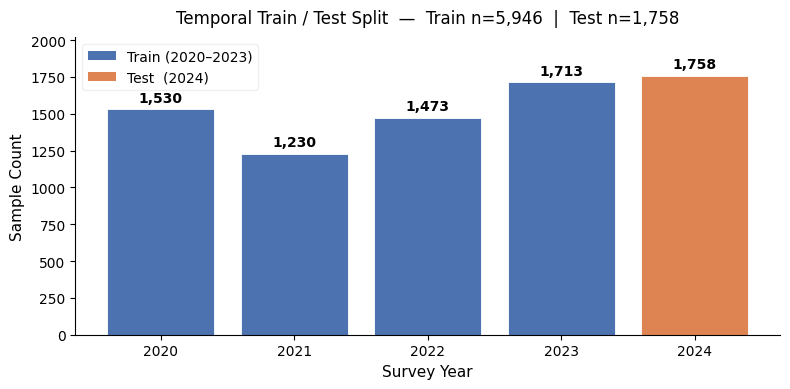

In [14]:
# ── Train / Test split — sample count by year ─────────────────────────────────────────────
year_counts = df_subset["year"].value_counts().sort_index()

colors = ["#4C72B0" if y != 2024.0 else "#DD8452" for y in year_counts.index]
labels = [str(int(y)) for y in year_counts.index]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(labels, year_counts.values, color=colors, edgecolor="white", linewidth=0.6)

for bar, val in zip(bars, year_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 30,
            f"{val:,}", ha="center", va="bottom", fontsize=10, fontweight="bold")

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="#4C72B0", label="Train (2020–2023)"),
    Patch(facecolor="#DD8452", label="Test  (2024)"),
]
ax.legend(handles=legend_elements, fontsize=10, framealpha=0.3)

train_n = year_counts[year_counts.index != 2024.0].sum()
test_n  = year_counts.get(2024.0, 0)
ax.set_title(
    f"Temporal Train / Test Split  —  Train n={train_n:,}  |  Test n={test_n:,}",
    fontsize=12, pad=10
)
ax.set_xlabel("Survey Year", fontsize=11)
ax.set_ylabel("Sample Count", fontsize=11)
ax.set_ylim(0, year_counts.max() * 1.15)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

<h2 style="color:#FFA500";> 7. Model Training </h2>

Five classifiers are tuned with Optuna (50 trials, 5-fold stratified CV, AUPRC objective). Class-imbalance handling is fixed, not tuned, for every model — see §8 for the `scale_pos_weight` pinning rationale.

In [15]:
from sklearn.pipeline import Pipeline

print("Class distribution:")
print(pd.Series(y_train).value_counts().to_dict())
print(f"Positive rate: {y_train.mean():.3f}")


Class distribution:
{0: 3313, 1: 2633}
Positive rate: 0.443


<h2 style="color:#FFA500";> 8. Hyperparameter Tuning — Optuna </h2>

**Method:** Single **50-trial Optuna TPE pass** per model using 5-fold `StratifiedKFold`, scored by `average_precision`. Class-imbalance handling is fixed for every model, not searched — see the note below the table.

**Standardization policy:** `StandardScaler` is added to the Logistic Regression pipeline only — tree-based models are scale-invariant by construction.

| Model | Key hyperparameters tuned |
|-------|--------------------------|
| **Random Forest** | `n_estimators`, `max_depth`*, `min_samples_leaf`* |
| **XGBoost** | `n_estimators`, `max_depth`, `learning_rate`, `subsample`, `colsample_bytree`, `min_child_weight`, `gamma`, `reg_lambda`* |
| **LightGBM** | `n_estimators`, `num_leaves`, `learning_rate`, `min_child_samples`, `reg_lambda`* |
| **CatBoost** | `iterations`, `depth`, `learning_rate`, `l2_leaf_reg`* |
| **Logistic Regression** | `C`* (inverse strength), `l1_ratio` (ElasticNet mix, SAGA solver) |

\* = regularization parameter

**`scale_pos_weight` is pinned, not tuned.** XGBoost's imbalance parameter is fixed to `n_neg/n_pos` in the objective function below, not left for Optuna to search — it was previously tuned over 1.0–5.0, which handed XGBoost one degree of freedom no other model had. The other four models handle class imbalance the same fixed way: `class_weight="balanced"` (Random Forest, LightGBM, Logistic Regression) or `auto_class_weights="Balanced"` (CatBoost), both of which resolve to the same `n_neg/n_pos` ratio — none of them get to search over it either. If `scale_pos_weight` were free to roam in Optuna's search space, XGBoost would gain an extra tunable knob for imbalance handling that no other model has: it could win the comparison not because gradient boosting is a better architecture, but because it got to hill-climb on the AUPRC objective using a parameter that acts almost like fitting on the evaluation metric itself. Pinning it puts all five models on equal footing for imbalance correction, isolating the comparison to genuine model/architecture differences — the right call for a model-comparison study, not a stylistic one.

**Method:** 5×5 nested cross-validation. Each outer development fold receives a fresh 5-fold, 50-trial Optuna TPE search per model (`scoring = 'average_precision'`). A separate full-development search selects the final parameters used for 2024 evaluation.

| Model                   | Key Hyperparameters                                                                                                              | Search Range                                                                                                       |
| :---------------------- | :------------------------------------------------------------------------------------------------------------------------------- | :----------------------------------------------------------------------------------------------------------------- |
| **Random Forest**       | `n_estimators`, `max_depth`, `min_samples_leaf`                                                                                  | 100–500 (step 100) · {5,10,15,None} · 1–10                                                                        |
| **XGBoost**             | `n_estimators`, `max_depth`, `learning_rate`, `subsample`, `colsample_bytree`, `min_child_weight`, `gamma`, `reg_lambda` | 100–700 · 3–7 · 0.01–0.3 (log) · 0.7–1.0 · 0.5–1.0 · 1–6 · 0–5 · 0.01–10 (log) |
| **LightGBM**            | `n_estimators`, `num_leaves`, `learning_rate`, `min_child_samples`, `reg_lambda`                                                 | 100–500 · 15–63 · 0.01–0.3 (log) · 5–20 · 0.01–10 (log)                                                          |
| **CatBoost**            | `iterations`, `depth`, `learning_rate`, `l2_leaf_reg`                                                                           | 100–500 · 3–8 · 0.01–0.3 (log) · 1–10                                                                             |
| **Logistic Regression** | `C`, `l1_ratio` (ElasticNet via SAGA)                                                                                           | 0.001–100 (log) · 0.0–1.0                                                                                         |

`scale_pos_weight` (XGBoost's imbalance parameter) is pinned to `n_neg/n_pos`, not tuned — see §8. Logistic regression uses `max_iter=5000`; any inner-CV trial that still raises `ConvergenceWarning` is pruned, and required outer/final fits fail explicitly rather than returning an unfinished solution.

<h3 style="color:yellow";> 8.1 Objective Function Definitions </h3>

Define one Optuna objective per model. Within each outer training partition, every objective runs 5-fold inner `StratifiedKFold` CV and returns mean `average_precision`. The imputer is rebuilt inside every inner fold. The objectives are reused once on all 2020–2023 rows for final-model tuning.

**Regularization parameters per model:**

| Model | Regularization parameter(s) | Type | Search range |
|---|---|---|---|
| Random Forest | `max_depth`, `min_samples_leaf` | Structural (limits tree size) | depth ∈ {5,10,15,None} · leaf ∈ [1,10] |
| XGBoost | `reg_lambda` | L2 weight penalty | [0.01, 10] log-scale |
| LightGBM | `reg_lambda` | L2 weight penalty | [0.01, 10] log-scale |
| CatBoost | `l2_leaf_reg` | L2 leaf penalty | [1, 10] |
| Logistic Regression | `C`, `l1_ratio` | Inverse ElasticNet strength; L1/L2 mix ratio | C ∈ [0.001, 100] log-scale · l1_ratio ∈ [0, 1] |

In [16]:
import optuna
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

optuna.logging.set_verbosity(optuna.logging.WARNING)

cv       = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
N_TRIALS = 50
LR_MAX_ITER = 5000

# Class weighting: RF / LightGBM / LogisticRegression use class_weight='balanced' and
# CatBoost uses auto_class_weights='Balanced' -- both are STRINGS that sklearn/CatBoost
# resolve to n_neg/n_pos INTERNALLY, at whatever data is passed to .fit(). Under CV
# (cross_val_score / cross_val_predict clone the estimator and fit each clone on its own
# fold), that means the ratio is recomputed fresh from each fold's OWN training partition,
# not from the full X_train.
#
# XGBoost has no such string option -- scale_pos_weight is just a number, so it can't be
# resolved per fold by passing a flag into the constructor. SCALE_POS_WEIGHT below is the
# full-training-set ratio, kept ONLY for the final refit in §9.1: fitting once on all of
# X_train has no folds to be inconsistent across, so the full-set ratio there is exactly
# what 'balanced' would also give. It is NOT used during tuning below -- obj_xgb instead
# recomputes the ratio inside a manual per-fold loop, so XGBoost's weighting is fold-local
# during CV just like the other four models, instead of one frozen value reused everywhere.
SCALE_POS_WEIGHT = float((y_train == 0).sum() / (y_train == 1).sum())
print(f"Full-training-set scale_pos_weight = {SCALE_POS_WEIGHT:.4f}"
      f"  (used only for the final refit in §9.1 -- tuning below is fold-local)")

def cv_score(estimator, require_convergence=False):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', ConvergenceWarning)
        scores = cross_val_score(estimator, X_train, y_train,
                                 cv=cv, scoring='average_precision', n_jobs=1)
    if require_convergence and any(
            issubclass(w.category, ConvergenceWarning) for w in caught):
        raise optuna.TrialPruned(
            f'Logistic regression did not converge within {LR_MAX_ITER} iterations')
    return scores.mean()   # n_jobs=1: avoid macOS fork-kill under memory pressure

def fit_with_convergence_check(estimator, X, y, context):
    """Fit a required model and refuse to continue with an unfinished LR solution."""
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', ConvergenceWarning)
        estimator.fit(X, y)
    if any(issubclass(w.category, ConvergenceWarning) for w in caught):
        raise RuntimeError(
            f'{context}: logistic regression did not converge within '
            f'{LR_MAX_ITER} iterations')
    return estimator


def obj_rf(trial):
    model = Pipeline([
        ('imputer', make_imputer()),
        ('model', RandomForestClassifier(
            n_estimators     = trial.suggest_int('n_estimators', 100, 500, step=100),
            max_depth        = trial.suggest_categorical('max_depth', [5, 10, 15, None]),
            min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 10),
            class_weight='balanced', random_state=42, n_jobs=-1))
    ])
    return cv_score(model)

def obj_xgb(trial):
    # scale_pos_weight has no 'balanced' string like sklearn/CatBoost, so it cannot be
    # resolved per fold by cross_val_score the way the other four objectives are -- whatever
    # value is baked into the constructor stays frozen across every fold it clones. To match
    # their fold-local behavior instead, this objective manually loops over the SAME
    # StratifiedKFold splits `cv` would use, recomputing n_neg/n_pos from each fold's OWN
    # training partition only -- exactly what class_weight='balanced' does internally for
    # the other models.
    params = dict(
        n_estimators      = trial.suggest_int('n_estimators', 100, 700, step=100),
        max_depth         = trial.suggest_int('max_depth', 3, 7),
        learning_rate     = trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        subsample         = trial.suggest_float('subsample', 0.7, 1.0),
        colsample_bytree  = trial.suggest_float('colsample_bytree', 0.5, 1.0),
        min_child_weight  = trial.suggest_int('min_child_weight', 1, 6),
        gamma             = trial.suggest_float('gamma', 0.0, 5.0),
        reg_lambda        = trial.suggest_float('reg_lambda', 1e-2, 10.0, log=True),
    )
    fold_scores = []
    for train_idx, val_idx in cv.split(X_train, y_train):
        # .iloc, not .loc: StratifiedKFold.split returns POSITIONAL indices into whatever
        # was passed to it, not the DataFrame's own row labels.
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
        fold_spw = float((y_tr == 0).sum() / (y_tr == 1).sum())
        fold_model = Pipeline([
            ('imputer', make_imputer()),
            ('model', XGBClassifier(
                **params,
                scale_pos_weight=fold_spw,   # fold-local, not the global SCALE_POS_WEIGHT
                eval_metric='logloss', random_state=42, nthread=1))
        ])
        fold_model.fit(X_tr, y_tr)
        fold_proba = fold_model.predict_proba(X_val)[:, 1]
        fold_scores.append(average_precision_score(y_val, fold_proba))
    return float(np.mean(fold_scores))

def obj_lgbm(trial):
    model = Pipeline([
        ('imputer', make_imputer()),
        ('model', LGBMClassifier(
            n_estimators      = trial.suggest_int('n_estimators', 100, 500, step=100),
            num_leaves        = trial.suggest_int('num_leaves', 15, 63),
            learning_rate     = trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
            min_child_samples = trial.suggest_int('min_child_samples', 5, 20),
            reg_lambda        = trial.suggest_float('reg_lambda', 1e-2, 10.0, log=True),
            class_weight='balanced', verbose=-1, random_state=42, n_jobs=1))
    ])
    return cv_score(model)

def obj_cat(trial):
    model = Pipeline([
        ('imputer', make_imputer()),
        ('model', CatBoostClassifier(
            iterations    = trial.suggest_int('iterations', 100, 500, step=100),
            depth         = trial.suggest_int('depth', 3, 8),
            learning_rate = trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
            l2_leaf_reg   = trial.suggest_float('l2_leaf_reg', 1.0, 10.0),
            auto_class_weights='Balanced', random_seed=42, verbose=0))
    ])
    return cv_score(model)

def obj_lr(trial):
    model = Pipeline([
        ('imputer', make_imputer()),
        ('scaler', make_scaler()),   # continuous only -- dummies stay 0/1, see §6
        ('model', LogisticRegression(
            # `penalty` was deprecated in scikit-learn 1.8 and is REMOVED in 1.10. The
            # penalty is now inferred from l1_ratio (0 = L2, 1 = L1, in between = elastic
            # net), so passing l1_ratio alone is the forward-compatible spelling. Verified
            # to give coefficients identical to the old penalty='elasticnet' on 1.8.
            C            = trial.suggest_float('C', 1e-3, 1e2, log=True),
            l1_ratio     = trial.suggest_float('l1_ratio', 0.0, 1.0),
            solver='saga', class_weight='balanced', max_iter=LR_MAX_ITER, random_state=42))
    ])
    return cv_score(model, require_convergence=True)

objectives = {
    'Random Forest':       obj_rf,
    'XGBoost':             obj_xgb,
    'LightGBM':            obj_lgbm,
    'CatBoost':            obj_cat,
    'Logistic Regression': obj_lr,
}

Full-training-set scale_pos_weight = 1.2583  (used only for the final refit in §9.1 -- tuning below is fold-local)


<h3 style="color:yellow";> 8.2 Nested Validation and Final Full-Development Tuning </h3>

Five outer folds generate tuning-independent OOF predictions. Within every outer training fold, each model receives a fresh 50-trial Optuna study with 5-fold inner CV. A final full-development study per model is stored in `results` for the untouched 2024 evaluation in §9.

In [17]:
# ── Honest nested cross-validation (development data only) ───────────────────
# The outer folds create tuning-independent OOF predictions. Each outer training
# partition receives a fresh 5-fold, 50-trial Optuna search; its selected model
# predicts only that outer validation fold. Afterward, the original full-development
# search runs once to choose parameters for the final 2020–2023 refit and 2024 test.
N_OUTER_FOLDS = 5
outer_cv = StratifiedKFold(n_splits=N_OUTER_FOLDS, shuffle=True, random_state=42)
_model_names_nested = list(objectives)
nested_oof_proba_by_model = {
    name: np.full(len(X_train), np.nan, dtype=float) for name in _model_names_nested
}
nested_tuning_by_fold = {name: [] for name in _model_names_nested}

def _build_outer_estimator(name, params, y_fit):
    """Build one outer-fold model; XGBoost gets that fold's class ratio."""
    if name == 'Random Forest':
        return Pipeline([('imputer', make_imputer()), ('model', RandomForestClassifier(
            class_weight='balanced', random_state=42, n_jobs=-1, **params))])
    if name == 'XGBoost':
        params = {k: v for k, v in params.items() if k != 'scale_pos_weight'}
        fold_spw = float((y_fit == 0).sum() / (y_fit == 1).sum())
        return Pipeline([('imputer', make_imputer()), ('model', XGBClassifier(
            scale_pos_weight=fold_spw, eval_metric='logloss', random_state=42,
            nthread=1, **params))])
    if name == 'LightGBM':
        return Pipeline([('imputer', make_imputer()), ('model', LGBMClassifier(
            class_weight='balanced', verbose=-1, random_state=42, n_jobs=1, **params))])
    if name == 'CatBoost':
        return Pipeline([('imputer', make_imputer()), ('model', CatBoostClassifier(
            auto_class_weights='Balanced', random_seed=42, verbose=0, **params))])
    if name == 'Logistic Regression':
        return Pipeline([('imputer', make_imputer()), ('scaler', make_scaler()),
                         ('model', LogisticRegression(class_weight='balanced',
                          solver='saga', max_iter=LR_MAX_ITER, random_state=42, **params))])
    raise ValueError(name)

# The objective functions in §8.1 read X_train/y_train/cv at call time. Temporarily
# point those names at each outer-training partition, then restore the full data.
_X_train_full, _y_train_full, _cv_full = X_train, y_train, cv
_outer_splits = list(outer_cv.split(_X_train_full, _y_train_full))
try:
    for outer_fold, (outer_train_idx, outer_valid_idx) in enumerate(_outer_splits, 1):
        X_train = _X_train_full.iloc[outer_train_idx]
        y_train = _y_train_full.iloc[outer_train_idx]
        X_outer_valid = _X_train_full.iloc[outer_valid_idx]
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1000 + outer_fold)
        print(f'Outer fold {outer_fold}/{N_OUTER_FOLDS}')
        for model_i, (name, objective) in enumerate(objectives.items()):
            study = optuna.create_study(
                direction='maximize',
                sampler=optuna.samplers.TPESampler(
                    seed=42 + 100 * outer_fold + model_i))
            study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=False)
            outer_model = _build_outer_estimator(name, study.best_params, y_train)
            if name == 'Logistic Regression':
                fit_with_convergence_check(
                    outer_model, X_train, y_train, f'Outer fold {outer_fold}')
            else:
                outer_model.fit(X_train, y_train)
            outer_proba = outer_model.predict_proba(X_outer_valid)[:, 1]
            nested_oof_proba_by_model[name][outer_valid_idx] = outer_proba
            fold_auprc = average_precision_score(
                _y_train_full.iloc[outer_valid_idx], outer_proba)
            nested_tuning_by_fold[name].append({
                'outer_fold': outer_fold, 'best_params': study.best_params,
                'inner_best_auprc': study.best_value,
                'outer_auprc': fold_auprc})
            print(f'  {name}: outer AUPRC={fold_auprc:.4f}')
finally:
    X_train, y_train, cv = _X_train_full, _y_train_full, _cv_full

for name, proba in nested_oof_proba_by_model.items():
    assert np.isfinite(proba).all(), f'{name}: incomplete nested OOF predictions'
nested_oof_summary = pd.DataFrame({
    name: {'Nested OOF AUPRC': average_precision_score(y_train, proba)}
    for name, proba in nested_oof_proba_by_model.items()
}).T.sort_values('Nested OOF AUPRC', ascending=False)
print('\nTuning-independent nested OOF performance:')
print(nested_oof_summary.round(4).to_string())
print('\nFinal full-development tuning for the 2024 refit:')

results = {}
for name, objective in objectives.items():
    study = optuna.create_study(
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=False)
    results[name] = {
        'best_params':   study.best_params,
        'best_cv_score': study.best_value,
        'study':         study
    }
    print(f"{name}: Best AUPRC = {study.best_value:.4f} | Params: {study.best_params}")

results_df = pd.DataFrame(
    {name: {'AUPRC': v['best_cv_score']} for name, v in results.items()}
).T.sort_values('AUPRC', ascending=False)
print(results_df)

Outer fold 1/5
  Random Forest: outer AUPRC=0.6816
  XGBoost: outer AUPRC=0.7030


/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  LightGBM: outer AUPRC=0.6945
  CatBoost: outer AUPRC=0.6986
  Logistic Regression: outer AUPRC=0.7104
Outer fold 2/5
  Random Forest: outer AUPRC=0.6493
  XGBoost: outer AUPRC=0.6559


/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  LightGBM: outer AUPRC=0.6569
  CatBoost: outer AUPRC=0.6665
  Logistic Regression: outer AUPRC=0.6580
Outer fold 3/5
  Random Forest: outer AUPRC=0.7098
  XGBoost: outer AUPRC=0.7143


...

  LightGBM: outer AUPRC=0.7070
  CatBoost: outer AUPRC=0.7114
  Logistic Regression: outer AUPRC=0.7101
Outer fold 4/5
  Random Forest: outer AUPRC=0.6969
  XGBoost: outer AUPRC=0.7069


/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  LightGBM: outer AUPRC=0.6950
  CatBoost: outer AUPRC=0.7091
  Logistic Regression: outer AUPRC=0.7146
Outer fold 5/5
  Random Forest: outer AUPRC=0.6653
  XGBoost: outer AUPRC=0.6800


/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  LightGBM: outer AUPRC=0.6795
  CatBoost: outer AUPRC=0.6828
  Logistic Regression: outer AUPRC=0.6777

Tuning-independent nested OOF performance:
                     Nested OOF AUPRC
Logistic Regression            0.6920
CatBoost                       0.6916
XGBoost                        0.6889
LightGBM                       0.6854
Random Forest                  0.6783

Final full-development tuning for the 2024 refit:
Random Forest: Best AUPRC = 0.6829 | Params: {'n_estimators': 500, 'max_depth': None, 'min_samples_leaf': 4}
XGBoost: Best AUPRC = 0.6938 | Params: {'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.052248772194070515, 'subsample': 0.7207175387755996, 'colsample_bytree': 0.5450178688449834, 'min_child_weight': 4, 'gamma': 2.7702869920531374, 'reg_lambda': 6.520529628855754}
LightGBM: Best AUPRC = 0.6895 | Params: {'n_estimators': 300, 'num_leaves': 39, 'learning_rate': 0.01799501490835551, 'min_child_samples': 20, 'reg_lambda': 1.7905716664152997}
CatBoost: Bes

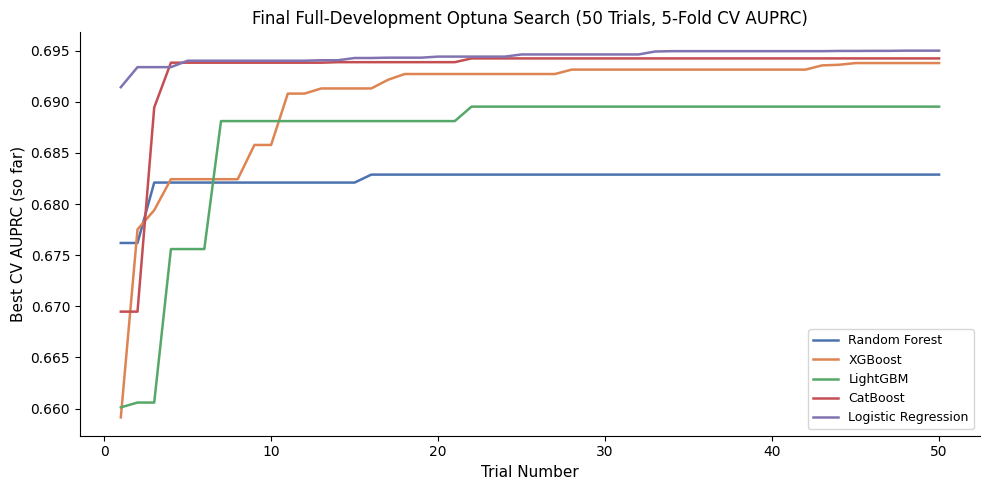

In [18]:
# ── Training Curve — Optuna Optimization History ────────────────────────────────
# Final full-development search: running best inner-CV AUPRC over 50 trials.
# Plateau early → converged; still rising at trial 50 → more budget may help.

_opt_colors = {
    'Random Forest':       '#4C72B0',
    'XGBoost':             '#DD8452',
    'LightGBM':            '#55A868',
    'CatBoost':            '#C44E52',
    'Logistic Regression': '#8172B2',
}

fig, ax = plt.subplots(figsize=(10, 5))
for name, info in results.items():
    trial_vals  = [t.value for t in info['study'].trials if t.value is not None]
    best_so_far = np.maximum.accumulate(trial_vals)
    ax.plot(range(1, len(best_so_far) + 1), best_so_far,
            linewidth=1.8, label=name, color=_opt_colors.get(name))

ax.set_xlabel('Trial Number', fontsize=11)
ax.set_ylabel('Best CV AUPRC (so far)', fontsize=11)
ax.set_title('Final Full-Development Optuna Search (50 Trials, 5-Fold CV AUPRC)', fontsize=12)
ax.legend(loc='lower right', fontsize=9)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

<h2 style="color:#FFA500";> 9. Refit & Evaluate Tuned Models on the Test Set </h2>

Refit each model using parameters from the final full-development Optuna search and score it on the held-out 2024 test set. Internal model ranking uses **nested OOF AUPRC** from the outer 2020–2023 folds; 2024 AUC/AUPRC are reported but never used to rank.

**Downstream model — pinned to CatBoost.** §10 (SHAP) and §12 (thresholds, calibration, DCA) use CatBoost, pinned explicitly rather than read from `eval_df.index[0]`. SHAP importance is compared across the 50+, 50-64 and 65+ cohorts, so the model being explained must be the **same algorithm** in all three; otherwise a difference in SHAP attribution between cohorts could reflect a change of model rather than an age-group effect. Whether CatBoost also tops a given cohort's OOF-AUPRC leaderboard is reported in the table below and does not affect the pin — only the model carried into §10 and §12 is fixed.

**Weighting policy for predictive analysis.** Model fitting, inner Optuna scores, nested OOF model comparison, nested-OOF-derived thresholds, and mean absolute SHAP aggregation are unweighted development-sample procedures. On the held-out 2024 test set, supported performance metrics use `wt_itvex` and are reported as population-weighted point estimates. Confusion matrices, the DeLong test, and decision-curve analysis remain sample-level because those implementations are unweighted; each is labeled where reported. Section 11 separately uses the full survey design for odds-ratio inference.

<h3 style="color:yellow";> 9.1 Final Refit, Rank by Nested OOF AUPRC & Pin CatBoost </h3>

In [19]:
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_predict

def build_estimator(name, params):
    if name == "Random Forest":
        return Pipeline([
            ("imputer", make_imputer()),
            ("model", RandomForestClassifier(
                class_weight="balanced", random_state=42, n_jobs=-1, **params))
        ])
    if name == "XGBoost":
        # scale_pos_weight is PINNED in §8 and no longer tuned, so it should not appear in
        # best_params. Strip it defensively: a `results` dict left over from a session where
        # it WAS tuned would otherwise raise "got multiple values for keyword argument
        # 'scale_pos_weight'" on a partial re-run of this cell.
        params = {k: v for k, v in params.items() if k != "scale_pos_weight"}
        return Pipeline([
            ("imputer", make_imputer()),
            ("model", XGBClassifier(
                scale_pos_weight=SCALE_POS_WEIGHT,
                eval_metric="logloss", random_state=42, nthread=1, **params))
        ])
    if name == "LightGBM":
        return Pipeline([
            ("imputer", make_imputer()),
            ("model", LGBMClassifier(
                class_weight="balanced", verbose=-1, random_state=42, n_jobs=1, **params))
        ])
    if name == "CatBoost":
        return Pipeline([
            ("imputer", make_imputer()),
            ("model", CatBoostClassifier(
                auto_class_weights="Balanced", random_seed=42, verbose=0, **params))
        ])
    if name == "Logistic Regression":
        return Pipeline([
            ("imputer", make_imputer()),
            ("scaler", make_scaler()),   # continuous only -- dummies stay 0/1, see §6
            # penalty inferred from l1_ratio (arrives via **params) -- see §8. The explicit
            # penalty= argument is removed in scikit-learn 1.10.
            ("model", LogisticRegression(
                class_weight="balanced",
                solver="saga", max_iter=LR_MAX_ITER, random_state=42, **params))
        ])
    raise ValueError(name)

fitted_models = {}
# Honest outer-fold predictions from §8.2; do not recompute them with the final
# full-development hyperparameters, because that would reintroduce tuning leakage.
oof_proba_by_model = {
    name: proba.copy() for name, proba in nested_oof_proba_by_model.items()
}
rows = []
for name, info in results.items():
    est = build_estimator(name, info["best_params"])
    _oof_proba = oof_proba_by_model[name]
    oof_auprc  = average_precision_score(y_train, _oof_proba)
    if name == "Logistic Regression":
        fit_with_convergence_check(est, X_train, y_train, 'Final full-development fit')
    else:
        est.fit(X_train, y_train)
    fitted_models[name] = est
    proba = est.predict_proba(X_test)[:, 1]
    # Test metrics are SURVEY-WEIGHTED (population estimates). CV/OOF above stay unweighted:
    # they drive model SELECTION, an internal choice made on the development sample.
    test_auc   = roc_auc_score(y_test, proba, sample_weight=w_test_arr)
    test_auprc = average_precision_score(y_test, proba, sample_weight=w_test_arr)
    rows.append({"Model": name,
                 "CV AUPRC":     info["best_cv_score"],
                 "OOF AUPRC":  oof_auprc,
                 "Test AUC":   test_auc,
                 "Test AUPRC": test_auprc})

# Rank by nested OOF AUPRC -- honest outer-fold predictions on 2020-2023 only.
#
# Selecting on Test AUPRC (the previous behaviour) makes every reported 2024 number a
# maximum over 5 candidate models, so the hold-out stops functioning as a hold-out and
# the optimism propagates into everything keyed on pinned_model_name: SHAP, top_shap_vars, the
# SHAP-informed regression in §9, the Youden/MCC thresholds, DCA and calibration. The
# bootstrap CIs in §9 do not cover that selection bias.
#
# Nested OOF AUPRC is the primary internal-validation estimate. Unlike Optuna's
# best_cv_score, every outer-fold prediction comes from hyperparameters selected only
# inside that outer fold's training partition.
#
# Test AUPRC / Test AUC remain in the table -- reported, never used to choose.
eval_df = (pd.DataFrame(rows)
             .set_index("Model")
             .sort_values("OOF AUPRC", ascending=False))
print(eval_df.round(4).to_string())
print("CAPTION: 'CV AUPRC' and 'OOF AUPRC' are UNWEIGHTED -- selection metrics computed on"
      "\nthe 2020-2023 development sample. 'Test AUC' and 'Test AUPRC' are SURVEY-WEIGHTED"
      "\npopulation estimates on the 2024 hold-out. Compare down a column, not across a row."
      "\nSelection is unweighted by design, so the selected model need not have the best"
      "\nweighted test score -- that is the hold-out working, not an inconsistency.")

nested_oof_winner_name = eval_df.index[0]  # nested-OOF leaderboard winner; never sees 2024

# CROSS-COHORT COMPARABILITY PIN ─────────────────────────────────────────────
# SHAP importance is compared across the 50+, 50-64 and 65+ cohorts, so the model
# being explained must be the SAME algorithm in all three. Holding it fixed means a
# SHAP difference between
# cohorts reflects age-group characteristics, not a change in model behaviour. The
# leaderboard above is unchanged and still reported in full; only the model carried
# downstream -- SHAP (§10), the Youden/MCC thresholds and confusion matrices (§12),
# calibration (§12.3) and DCA (§12.5) --
# is pinned here.
pinned_model_name  = 'CatBoost'
pinned_model = fitted_models[pinned_model_name]
print(f'Model pinned for cross-cohort SHAP comparability: {pinned_model_name}'
      f' (OOF AUPRC = {eval_df.loc[pinned_model_name, "OOF AUPRC"]:.4f}'
      f' | Test AUPRC: {eval_df.loc[pinned_model_name, "Test AUPRC"]:.4f}'
      f' | Test AUC: {eval_df.loc[pinned_model_name, "Test AUC"]:.4f}'
      f' | Optuna CV AUPRC: {eval_df.loc[pinned_model_name, "CV AUPRC"]:.4f})')
print(f'OOF AUPRC leaderboard winner (reported, not used downstream): {nested_oof_winner_name}'
      f' (OOF AUPRC = {eval_df.loc[nested_oof_winner_name, "OOF AUPRC"]:.4f})')

/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


                     CV AUPRC  OOF AUPRC  Test AUC  Test AUPRC
Model                                                         
Logistic Regression    0.6950     0.6920    0.7525      0.6903
CatBoost               0.6942     0.6916    0.7594      0.6901
XGBoost                0.6938     0.6889    0.7576      0.6902
LightGBM               0.6895     0.6854    0.7449      0.6757
Random Forest          0.6829     0.6783    0.7456      0.6794
CAPTION: 'CV AUPRC' and 'OOF AUPRC' are UNWEIGHTED -- selection metrics computed on
the 2020-2023 development sample. 'Test AUC' and 'Test AUPRC' are SURVEY-WEIGHTED
population estimates on the 2024 hold-out. Compare down a column, not across a row.
Selection is unweighted by design, so the selected model need not have the best
weighted test score -- that is the hold-out working, not an inconsistency.
Model pinned for cross-cohort SHAP comparability: CatBoost (OOF AUPRC = 0.6916 | Test AUPRC: 0.6901 | Test AUC: 0.7594 | Optuna CV AUPRC: 0.6942)
OOF AUPR

<h3 style="color:yellow";> 9.2 Bootstrap 95% CIs — Test-Set Metrics </h3>

In [20]:
# ── Test-set Accuracy/Recall/Precision/F1/AUROC, OOF AUPRC and survey-weighted Test AUPRC with bootstrap 95% CIs ──
# Accuracy/Recall/Specificity/Precision/F1 are evaluated at each model's MCC-optimal threshold: the
# threshold that maximizes Matthews correlation coefficient on that model's OOF training
# probabilities. This mirrors §12's confusion-matrix threshold selection but is computed
# independently here (rather than reusing §12's mcc_curve) so this cell stays
# self-contained and doesn't depend on §12 having already run -- same convention used
# elsewhere in this notebook. The threshold is picked purely from OOF/train predictions
# and never touches the test set.
#
# Accuracy/Recall/Precision/F1 and AUROC are computed on the 2024 hold-out test rows,
# survey-weighted (wt_itvex), with a 95% CI from a PSU-within-stratum cluster
# bootstrap of those rows -- the SAME resamples for every metric and model, so
# comparisons stay paired. AUPRC is OOF AUPRC -- out-of-fold average precision on the
# 2020-2023 training folds, i.e. §9.1's selection metric -- UNWEIGHTED, with its own 95%
# CI from a stratified bootstrap of the training rows, matching §9.1's convention that
# selection metrics are computed on the unweighted development sample. 'Test AUPRC' is
# the survey-weighted average precision on the 2024 hold-out (the §9.1 eval_df value),
# added beside OOF AUPRC with a 95% CI from the SAME test-row bootstrap as the other
# weighted metrics -- reported, never used for selection.
#
# Both bootstraps use 2000 resamples and a fixed seed: PSU-within-stratum clusters
# for test-set metrics and outcome-stratified rows for OOF AUPRC.
# Depends on fitted_models / oof_proba_by_model / X_test / y_test / y_train from
# the model-evaluation cell (§9.1).
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
                              recall_score, precision_score, f1_score, roc_curve,
                              confusion_matrix)

N_BOOT_CI = 2000
_yte = y_test.to_numpy()
_wte = w_test.to_numpy()      # survey weights, applied to every test-set metric

_ytr = y_train.to_numpy()
_idx0_tr = np.where(_ytr == 0)[0]
_idx1_tr = np.where(_ytr == 1)[0]

_rng_ci = np.random.default_rng(42)

# PSU-cluster bootstrap for the WEIGHTED test-set metrics -- resampling individual rows
# (the previous approach) treats every respondent as an independent draw, which a complex
# survey design violates: KNHANES samples clusters of respondents within each PSU, so rows
# sharing a PSU are correlated and a row-level bootstrap understates the true variance of a
# design-weighted estimate. Resample whole PSUs (with replacement, within stratum) instead,
# keeping each row's original wt_itvex unchanged -- a simplified cluster bootstrap that
# fixes the independence violation, not the full Rao-Wu-Yue-Beaumont replicate-weight
# bootstrap (which would also rescale weights per replicate). §11's primary design-based
# inference (Taylor linearization via svyglm) does not depend on this bootstrap at all.
#
# test_mask (§6) selects 2024 only, so year is constant here; kstrata/psu still combine
# into a globally-unique cluster id for consistency with §11's svy_psu convention.
_psu_te     = df_subset.loc[test_mask, 'psu'].to_numpy()
_kstrata_te = df_subset.loc[test_mask, 'kstrata'].to_numpy()
assert len(_psu_te) == len(_yte), "psu/kstrata misaligned with test rows"

_cluster_id = pd.factorize(
    pd.Series(_kstrata_te).astype(int).astype(str) + '_' + pd.Series(_psu_te).astype(str)
)[0]
_strata_id = pd.factorize(pd.Series(_kstrata_te).astype(int).astype(str))[0]

_strata_to_clusters = {s: np.unique(_cluster_id[_strata_id == s]) for s in np.unique(_strata_id)}
_cluster_to_rows = {c: np.where(_cluster_id == c)[0] for c in np.unique(_cluster_id)}

_boot_idx = []
for _ in range(N_BOOT_CI):
    _rows = []
    for _clusters in _strata_to_clusters.values():
        _drawn = _rng_ci.choice(_clusters, size=len(_clusters), replace=True)
        _rows.extend(_cluster_to_rows[_c] for _c in _drawn)
    _boot_idx.append(np.concatenate(_rows))

# unweighted OOF-AUPRC bootstrap (training rows, §9.1's own selection-metric convention)
# is unaffected by the cluster-vs-row question above -- it is not a design-weighted
# population estimate, so it keeps the original row-level stratified-by-outcome resample.
_boot_idx_tr = [
    np.concatenate([_rng_ci.choice(_idx0_tr, _idx0_tr.size, replace=True),
                    _rng_ci.choice(_idx1_tr, _idx1_tr.size, replace=True)])
    for _ in range(N_BOOT_CI)
]

def _mcc_optimal_threshold(y_true, oof_proba):
    # Vectorised MCC sweep over OOF ROC thresholds -- same trick as §12's mcc_curve
    # (sort scores once, walk the cut-point down as a running confusion-matrix total),
    # duplicated here rather than imported so this cell doesn't depend on §12's order.
    y = np.asarray(y_true, dtype=np.int64)
    p = np.asarray(oof_proba, dtype=float)
    _, _, thresh_oof = roc_curve(y, p)
    order    = np.argsort(-p, kind='mergesort')
    y_sorted = y[order]
    p_sorted = p[order]
    P = int(y.sum())
    N = y.size - P
    k = np.searchsorted(-p_sorted, -thresh_oof, side='right')
    cum_tp = np.concatenate(([0], np.cumsum(y_sorted)))
    TP = cum_tp[k].astype(float)
    FP = k - TP
    FN = P - TP
    TN = N - FP
    denom = np.sqrt((TP + FP) * (TP + FN) * (TN + FP) * (TN + FN))
    with np.errstate(invalid='ignore', divide='ignore'):
        mcc = (TP * TN - FP * FN) / denom
    mcc = np.where(denom == 0, 0.0, mcc)
    return float(thresh_oof[int(np.argmax(mcc))])

def _boot_ci_test(values, metric):
    # weights are indexed alongside y/values so each resample carries its own rows' weights.
    # A cluster resample could in principle land on a single-class outcome (unlike the old
    # stratified-by-outcome row resample, which guaranteed both classes) -- skip those rather
    # than let e.g. roc_auc_score raise; astronomically rare at this n_clusters/n_strata but
    # cheap to guard against.
    vals = []
    for bi in _boot_idx:
        yb = _yte[bi]
        if yb.min() == yb.max():
            continue
        vals.append(metric(yb, values[bi], sample_weight=_wte[bi]))
    lo, hi = np.percentile(np.asarray(vals, dtype=float), [2.5, 97.5])
    return lo, hi

def _boot_ci_oof(oof_proba):
    # unweighted, resampled over the training rows -- mirrors §9.1's OOF AUPRC convention
    vals = np.fromiter(
        (average_precision_score(_ytr[bi], oof_proba[bi]) for bi in _boot_idx_tr),
        dtype=float, count=N_BOOT_CI)
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return lo, hi

_metric_fns = {
    "Accuracy":    lambda y, pred, sample_weight: accuracy_score(y, pred, sample_weight=sample_weight),
    "Recall":      lambda y, pred, sample_weight: recall_score(y, pred, sample_weight=sample_weight, zero_division=0),
    "Specificity": lambda y, pred, sample_weight: recall_score(y, pred, pos_label=0, sample_weight=sample_weight, zero_division=0),
    "Precision":   lambda y, pred, sample_weight: precision_score(y, pred, sample_weight=sample_weight, zero_division=0),
    "F1":          lambda y, pred, sample_weight: f1_score(y, pred, sample_weight=sample_weight, zero_division=0),
}

_rows_ci = []
for _name, _model in fitted_models.items():
    _p      = _model.predict_proba(X_test)[:, 1]
    _oof_p  = oof_proba_by_model[_name]
    _thresh = _mcc_optimal_threshold(_ytr, _oof_p)
    _preds  = (_p >= _thresh).astype(int)

    _pt = {m: fn(_yte, _preds, sample_weight=_wte) for m, fn in _metric_fns.items()}
    _pt["AUROC"]     = roc_auc_score(_yte, _p, sample_weight=_wte)
    _pt["OOF AUPRC"] = average_precision_score(_ytr, _oof_p)
    _pt["Test AUPRC"] = average_precision_score(_yte, _p, sample_weight=_wte)

    # Cross-check: Sensitivity/Specificity recomputed directly from TP/FP/FN/TN of a
    # sample-weighted confusion matrix, confirming they match the recall_score values above.
    _tn, _fp, _fn, _tp = confusion_matrix(_yte, _preds, sample_weight=_wte).ravel()
    _sens_check = _tp / (_tp + _fn)
    _spec_check = _tn / (_tn + _fp)
    assert np.isclose(_sens_check, _pt["Recall"]) and np.isclose(_spec_check, _pt["Specificity"]), \
        f"{_name}: confusion-matrix check mismatch"
    print(f"  [check] {_name}: Sensitivity = TP/(TP+FN) = {_sens_check:.3f}, "
          f"Specificity = TN/(TN+FP) = {_spec_check:.3f}")

    _ci = {m: _boot_ci_test(_preds, fn) for m, fn in _metric_fns.items()}
    _ci["AUROC"]     = _boot_ci_test(_p, roc_auc_score)
    _ci["OOF AUPRC"] = _boot_ci_oof(_oof_p)
    _ci["Test AUPRC"] = _boot_ci_test(_p, average_precision_score)

    _row = {"Model": _name, "Threshold (MCC-opt., OOF)": f"{_thresh:.3f}"}
    for m in ("Accuracy", "Recall", "Specificity", "Precision", "F1", "AUROC", "OOF AUPRC", "Test AUPRC"):
        _row[f"{m} (95% CI)"] = f"{_pt[m]:.3f} ({_ci[m][0]:.3f}–{_ci[m][1]:.3f})"
    _rows_ci.append(_row)

metrics_ci_df = pd.DataFrame(_rows_ci).set_index("Model")
print(f"Test-set Accuracy/Recall/Specificity/Precision/F1/AUROC (95% CI), OOF AUPRC (95% CI) and "
      f"survey-weighted Test AUPRC (95% CI) "
      f"-- classification metrics at each model's OOF MCC-optimal threshold "
      f"(n_test={len(_yte)}, n_train={len(_ytr)}; test CI: {N_BOOT_CI} PSU-within-stratum cluster resamples; "
      f"OOF AUPRC CI: {N_BOOT_CI} outcome-stratified row resamples; seed=42)")
print(metrics_ci_df.to_string())


  [check] Random Forest: Sensitivity = TP/(TP+FN) = 0.516, Specificity = TN/(TN+FP) = 0.833
  [check] XGBoost: Sensitivity = TP/(TP+FN) = 0.629, Specificity = TN/(TN+FP) = 0.748


/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  [check] LightGBM: Sensitivity = TP/(TP+FN) = 0.532, Specificity = TN/(TN+FP) = 0.797
  [check] CatBoost: Sensitivity = TP/(TP+FN) = 0.579, Specificity = TN/(TN+FP) = 0.796
  [check] Logistic Regression: Sensitivity = TP/(TP+FN) = 0.644, Specificity = TN/(TN+FP) = 0.712
Test-set Accuracy/Recall/Specificity/Precision/F1/AUROC (95% CI), OOF AUPRC (95% CI) and survey-weighted Test AUPRC (95% CI) -- classification metrics at each model's OOF MCC-optimal threshold (n_test=1758, n_train=5946; test CI: 2000 PSU-within-stratum cluster resamples; OOF AUPRC CI: 2000 outcome-stratified row resamples; seed=42)
                    Threshold (MCC-opt., OOF)    Accuracy (95% CI)      Recall (95% CI) Specificity (95% CI)   Precision (95% CI)          F1 (95% CI)       AUROC (95% CI)   OOF AUPRC (95% CI)  Test AUPRC (95% CI)
Model                                                                                                                                                                              

<h3 style="color:#87CEEB";> 9.3 Sex-Stratified Discrimination — AUROC / AUPRC by Sex </h3>

In [21]:
# ── §9.3 Sex-stratified discrimination — AUROC / AUPRC by sex, all tuned models ──
# Reviewer request: report discrimination separately for male and female respondents
# within this cohort, to check the models perform equally well across sexes. Reuses the
# fitted pipelines and the 2024 hold-out test set from §9. CIs use the same PSU-within-
# stratum cluster bootstrap as §9.2 (2000 resamples, seed 42), constructed separately
# within each sex subset.
from sklearn.metrics import roc_auc_score, average_precision_score

_yte = y_test.to_numpy()  # self-contained: re-derive rather than lean on §9 leakage
_wte = w_test.to_numpy()  # survey weights (evaluation only) -- see the split cell in §6

# Sex aligned to the test rows. KNHANES codes sex 1=male / 2=female and the pipeline
# never recodes it; feat shares df_subset's index, so test_mask selects the same rows
# (in the same order) as X_test — asserted below before use.
_sex_test = df_subset.loc[test_mask, 'sex'].map({1: 'Male', 2: 'Female'})
assert _sex_test.index.equals(X_test.index), "sex vector misaligned with X_test rows"
_sex_arr = _sex_test.to_numpy()

N_BOOT_SEX = 2000
_rng_sex = np.random.default_rng(42)

_psu_sex = df_subset.loc[test_mask, 'psu'].to_numpy()
_strata_sex = df_subset.loc[test_mask, 'kstrata'].to_numpy()
assert len(_psu_sex) == len(_yte), "sex-bootstrap design columns misaligned"

def _psu_within_stratum_boot(rows, rng, n_boot):
    """Global-row indices from a PSU-within-stratum bootstrap of `rows`."""
    boots = []
    for _ in range(n_boot):
        drawn_rows = []
        for stratum in np.unique(_strata_sex[rows]):
            rows_h = rows[_strata_sex[rows] == stratum]
            psus_h = np.unique(_psu_sex[rows_h])
            drawn_psus = rng.choice(psus_h, size=len(psus_h), replace=True)
            drawn_rows.extend(rows_h[_psu_sex[rows_h] == psu] for psu in drawn_psus)
        boots.append(np.concatenate(drawn_rows))
    return boots

_sex_boot = {}
for _s in ('Male', 'Female'):
    _rows_s = np.where(_sex_arr == _s)[0]
    _y_s = _yte[_rows_s]
    _sex_boot[_s] = {
        'rows': _rows_s,
        'boot': (_psu_within_stratum_boot(_rows_s, _rng_sex, N_BOOT_SEX)
                 if len(np.unique(_y_s)) == 2 else None),
    }

def _sex_ci(proba, boot, metric):
    if boot is None:
        return None
    vals = [metric(_yte[bi], proba[bi], sample_weight=_wte[bi])
            for bi in boot if len(np.unique(_yte[bi])) == 2]
    if not vals:
        return None
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return lo, hi

def _fmt(pt, ci):
    if np.isnan(pt):
        return "n/a (single-class subset)"
    return f"{pt:.3f} ({ci[0]:.3f}–{ci[1]:.3f})" if ci else f"{pt:.3f} (CI n/a)"

_rows_sex = []
for _name, _model in fitted_models.items():
    _p_full = _model.predict_proba(X_test)[:, 1]
    for _s in ('Male', 'Female'):
        _rows_s, _boot_s = _sex_boot[_s]['rows'], _sex_boot[_s]['boot']
        _y_s, _p_s, _w_s = _yte[_rows_s], _p_full[_rows_s], _wte[_rows_s]
        _one_class = len(np.unique(_y_s)) < 2
        _auc = np.nan if _one_class else roc_auc_score(_y_s, _p_s, sample_weight=_w_s)
        _ap = np.nan if _one_class else average_precision_score(_y_s, _p_s, sample_weight=_w_s)
        _rows_sex.append({
            "Model": _name, "Sex": _s,
            "n": int(_rows_s.size), "n_pos": int(_y_s.sum()),
            "AUROC (95% CI)": _fmt(_auc, _sex_ci(_p_full, _boot_s, roc_auc_score)),
            "AUPRC (95% CI)": _fmt(_ap, _sex_ci(_p_full, _boot_s, average_precision_score)),
        })

sex_metrics_df = pd.DataFrame(_rows_sex).set_index(["Model", "Sex"])
print(f"Sex-stratified test-set discrimination "
      f"(age≥{age_threshold} cohort, n_test={len(_yte)}, "
      f"{N_BOOT_SEX} PSU-within-stratum cluster resamples, seed=42)")
print(sex_metrics_df.to_string())


/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Sex-stratified test-set discrimination (age≥65 cohort, n_test=1758, 2000 PSU-within-stratum cluster resamples, seed=42)
                               n  n_pos       AUROC (95% CI)       AUPRC (95% CI)
Model               Sex                                                          
Random Forest       Male     733    323  0.737 (0.704–0.769)  0.675 (0.631–0.719)
                    Female  1025    402  0.759 (0.727–0.791)  0.693 (0.644–0.737)
XGBoost             Male     733    323  0.749 (0.716–0.780)  0.692 (0.648–0.734)
                    Female  1025    402  0.768 (0.737–0.799)  0.694 (0.646–0.738)
LightGBM            Male     733    323  0.724 (0.691–0.756)  0.664 (0.617–0.708)
                    Female  1025    402  0.763 (0.733–0.793)  0.687 (0.639–0.729)
CatBoost            Male     733    323  0.751 (0.718–0.782)  0.685 (0.643–0.727)
                    Female  1025    402  0.772 (0.740–0.802)  0.700 (0.653–0.744)
Logistic Regression Male     733    323  0.735 (0.701–0.768)

<h3 style="color:#87CEEB";> 9.4 DeLong Significance Test — Pairwise Model AUC Comparison </h3>

In [22]:
# ── DeLong test — pairwise significance of Test AUC differences (Sun & Xu 2014 fast algorithm) ──
# Test AUPRC gaps between models are often within noise on a single temporal holdout; DeLong gives
# a p-value for whether the Test AUC gap between two models is real, using the fact that both models
# are scored on the same test rows (paired), not independent samples.
from scipy import stats

def _compute_midrank(x):
    J = np.argsort(x)
    Z = x[J]
    N = len(x)
    T = np.zeros(N, dtype=float)
    i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]:
            j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    T2 = np.empty(N, dtype=float)
    T2[J] = T
    return T2

def _fast_delong(preds, label_1_count):
    m = label_1_count
    n = preds.shape[1] - m
    positive = preds[:, :m]
    negative = preds[:, m:]
    k = preds.shape[0]

    tx = np.empty([k, m], dtype=float)
    ty = np.empty([k, n], dtype=float)
    tz = np.empty([k, m + n], dtype=float)
    for r in range(k):
        tx[r, :] = _compute_midrank(positive[r, :])
        ty[r, :] = _compute_midrank(negative[r, :])
        tz[r, :] = _compute_midrank(preds[r, :])
    aucs = tz[:, :m].sum(axis=1) / m / n - float(m + 1) / (2 * n)
    v01 = (tz[:, :m] - tx[:, :]) / n
    v10 = 1.0 - (tz[:, m:] - ty[:, :]) / m
    sx = np.cov(v01)
    sy = np.cov(v10)
    delongcov = sx / m + sy / n
    return aucs, delongcov

def _calc_pvalue(aucs, sigma):
    l = np.array([[1, -1]])
    z = np.abs(np.diff(aucs)) / np.sqrt(l.dot(sigma).dot(l.T))
    return 2 * (1 - stats.norm.cdf(z))[0, 0]

def delong_roc_test(y_true, prob_a, prob_b):
    order = np.argsort(-y_true)
    y_sorted = y_true[order]
    m = int(np.sum(y_sorted == 1))
    preds = np.vstack([prob_a[order], prob_b[order]])
    aucs, delongcov = _fast_delong(preds, m)
    return aucs, _calc_pvalue(aucs, delongcov)

# NOTE: this test is UNWEIGHTED. The fast DeLong algorithm assumes i.i.d. rows and has no
# survey-weighted form, so its AUCs are sample-level and will not match the survey-weighted
# 'Test AUC' column in §9. It answers "do these two models rank differently on these rows?",
# which is a model-comparison question, not a population estimate.
# Pairwise DeLong test across all fitted models, same test set
model_names = list(fitted_models.keys())
y_test_arr = y_test.to_numpy()
proba_by_model = {name: fitted_models[name].predict_proba(X_test)[:, 1] for name in model_names}

delong_rows = []
for i in range(len(model_names)):
    for j in range(i + 1, len(model_names)):
        name_i, name_j = model_names[i], model_names[j]
        (auc_i, auc_j), p = delong_roc_test(y_test_arr, proba_by_model[name_i], proba_by_model[name_j])
        delong_rows.append({
            "Model A": name_i, "Model B": name_j,
            "AUC A": round(auc_i, 4), "AUC B": round(auc_j, 4),
            "DeLong p-value": round(p, 4),
            "Significant (p<0.05)": p < 0.05,
        })

delong_df = pd.DataFrame(delong_rows)

print(f"Pairwise DeLong test -- Test AUC significance "
      f"(pinned model: {pinned_model_name}; OOF AUPRC winner: {nested_oof_winner_name})")
print(delong_df.to_string(index=False))

# ── Interpretation: is the pinned model distinguishable from the OOF AUPRC winner? ──
# pinned_model_name is pinned to CatBoost in §9.1. Compare it against the OOF AUPRC leaderboard
# winner; in the 50+ cohort the two coincide, so fall back to the next model down.
comparison_model_name = nested_oof_winner_name if nested_oof_winner_name != pinned_model_name else eval_df.index[1]
_pair_mask = (
    ((delong_df["Model A"] == pinned_model_name) & (delong_df["Model B"] == comparison_model_name)) |
    ((delong_df["Model A"] == comparison_model_name) & (delong_df["Model B"] == pinned_model_name))
)
_top_pair = delong_df[_pair_mask].iloc[0]
print(f"\nPinned {pinned_model_name} vs {comparison_model_name} -- DeLong p = {_top_pair['DeLong p-value']:.4f} "
      f"({'significant' if _top_pair['Significant (p<0.05)'] else 'NOT significant'} at alpha=0.05).")
if not _top_pair["Significant (p<0.05)"]:
    print(f"'{pinned_model_name}' (pinned) is not shown to be statistically superior to '{comparison_model_name}' "
          f"on test-set AUC.")


Pairwise DeLong test -- Test AUC significance (pinned model: CatBoost; OOF AUPRC winner: Logistic Regression)
      Model A             Model B  AUC A  AUC B  DeLong p-value  Significant (p<0.05)
Random Forest             XGBoost 0.7466 0.7552          0.0224                  True
Random Forest            LightGBM 0.7466 0.7437          0.5289                 False
Random Forest            CatBoost 0.7466 0.7550          0.0195                  True
Random Forest Logistic Regression 0.7466 0.7494          0.5953                 False
      XGBoost            LightGBM 0.7552 0.7437          0.0013                  True
      XGBoost            CatBoost 0.7552 0.7550          0.9110                 False
      XGBoost Logistic Regression 0.7552 0.7494          0.1560                 False
     LightGBM            CatBoost 0.7437 0.7550          0.0036                  True
     LightGBM Logistic Regression 0.7437 0.7494          0.2728                 False
     CatBoost Logistic Regress

/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


<h2 style="color:#FFA500";> 10. SHAP Importance & SHAP-Informed Regression </h2>

In [23]:
import shap

# ── Compute SHAP values for the pinned CatBoost comparison model ─────────
# X_test_imp: imputed (unscaled) test matrix in feature_cols order
X_test_imp = pinned_model.named_steps['imputer'].transform(X_test)

pinned_classifier = pinned_model.named_steps['model']

if pinned_model_name == 'Logistic Regression':
    # BACKGROUND = TRAINING DATA. LinearExplainer reduces to coef_j * (x_j - E[x_j]), where
    # E[x] comes from the background set. Passing X_test_scaled made the baseline the 2024
    # mean -- a distribution the coefficients were never fitted on. The 2020-2023 mean
    # is the conventional and correct reference. SHAP values are still EVALUATED on the
    # test rows; only the baseline they are measured against changes.
    X_train_imp    = pinned_model.named_steps['imputer'].transform(X_train)
    X_train_scaled = pinned_model.named_steps['scaler'].transform(X_train_imp)
    X_test_scaled  = pinned_model.named_steps['scaler'].transform(X_test_imp)
    explainer   = shap.LinearExplainer(pinned_classifier, X_train_scaled)
    shap_values = explainer.shap_values(X_test_scaled)
else:
    explainer = shap.TreeExplainer(pinned_classifier)
    sv_raw    = explainer.shap_values(X_test_imp)
    shap_values = sv_raw[..., 1] if getattr(sv_raw, 'ndim', 0) == 3 else (sv_raw[1] if isinstance(sv_raw, list) else sv_raw)

print(f'Pinned comparison model: {pinned_model_name}')
print(f'shap_values shape: {shap_values.shape}')
print(f'X_test_imp shape:  {X_test_imp.shape}')


Pinned comparison model: CatBoost
shap_values shape: (1758, 88)
X_test_imp shape:  (1758, 88)


<h3 style="color:yellow";> 10.1 SHAP Summary Plot — Feature Importance (Top 20) </h3>

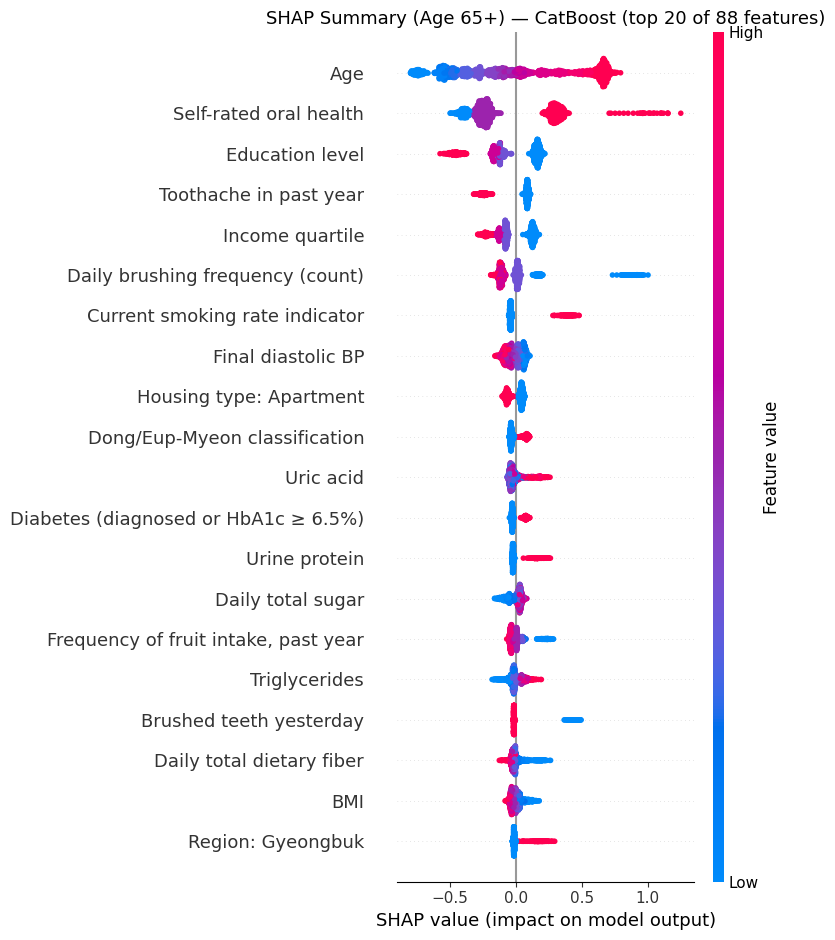

Top 20 features by unweighted mean |SHAP| (CatBoost):
   1. age                  0.4113
   2. OR1                  0.2984
   3. edu                  0.1839
   4. O_pain               0.1236  [two-valued: colour = absent/present]
   5. ho_incm              0.1207
   6. brush_freq           0.1080
   7. sm_presnt            0.0678  [two-valued: colour = absent/present]
   8. HE_dbp               0.0519
   9. live_t_2             0.0516  [two-valued: colour = absent/present]
  10. town_t               0.0473  [two-valued: colour = absent/present]
  11. HE_Uacid             0.0437
  12. diabetes             0.0420  [two-valued: colour = absent/present]
  13. HE_Upro              0.0416
  14. N_SUGAR              0.0379
  15. LS_FRUIT             0.0378
  16. HE_TG                0.0377
  17. BM1_0                0.0328  [two-valued: colour = absent/present]
  18. N_TDF                0.0319
  19. HE_BMI               0.0291
  20. region_15            0.0281  [two-valued: colour = absent/pr

In [24]:
# ── SHAP beeswarm — ALL feature types, top 20 by mean |SHAP| ─────────────────
# Every feature now competes on equal footing: continuous, ordinal, binary, and one-hot
# dummies. The previous version filtered out 5 binaries and all 8 dummy blocks on the
# grounds that "the colour gradient is meaningless for them". After one-hot encoding each
# dummy is a clean 0/1 indicator, so the gradient is simply TWO-VALUED (blue = 0/absent,
# red = 1/present) rather than meaningless -- and excluding them meant the beeswarm and the
# mean |SHAP| bar chart below ranked DIFFERENT feature sets, so the two panels of Figure 4
# disagreed with Table 3.
#
# max_display matches the bar chart below, so both panels show the same rows.
SHAP_MAX_DISPLAY = 20
from codebook_labels import label_list
_mean_abs_bee = np.abs(shap_values).mean(axis=0)
_top_idx = np.argsort(_mean_abs_bee)[::-1][:SHAP_MAX_DISPLAY]
_top_features = [feature_cols[i] for i in _top_idx]
_display_names = label_list(_top_features)

shap.summary_plot(
    shap_values[:, _top_idx], X_test_imp[:, _top_idx],
    feature_names=_display_names,
    max_display=SHAP_MAX_DISPLAY,
    sort=False,  # preserve unweighted mean-|SHAP| ordering
    show=False,
)
plt.title(f'SHAP Summary (Age 65+) — {pinned_model_name} '
          f'(top {SHAP_MAX_DISPLAY} of {len(feature_cols)} features)', fontsize=13)
plt.tight_layout()
plt.show()

# Global importance is the conventional unweighted mean absolute SHAP value across
# test rows, matching the unweighted model-fitting and selection pipeline.
# Flag which of the displayed features are two-valued, so the figure caption can state that
# their colour encodes absent/present rather than a continuous gradient.
_top_bee = pd.Series(_mean_abs_bee[_top_idx], index=_top_features)
_nuniq = {f: pd.Series(X_test_imp[:, feature_cols.index(f)]).nunique() for f in _top_bee.index}
print(f"Top {SHAP_MAX_DISPLAY} features by unweighted mean |SHAP| ({pinned_model_name}):")
for _r, (_f, _v) in enumerate(_top_bee.items(), 1):
    _tag = "  [two-valued: colour = absent/present]" if _nuniq[_f] <= 2 else ""
    print(f"  {_r:>2}. {_f:<20} {_v:.4f}{_tag}")
print(f"\n{sum(v <= 2 for v in _nuniq.values())} of the {SHAP_MAX_DISPLAY} displayed "
      f"features are two-valued — note this in the Figure 4 caption.")

<h3 style="color:yellow";> 10.2 Save SHAP Importance — Cross-Cohort Comparison </h3>

In [25]:
# -- Save mean |SHAP| feature importance for combined cross-cohort plot --
import numpy as np
# Conventional global SHAP importance: unweighted mean absolute attribution across
# test rows, matching the unweighted model-fitting and selection pipeline.
mean_abs_shap = np.abs(shap_values).mean(axis=0)
np.savez('shap_importance_65plus_catboost.npz',
         feature_names=np.array(feature_cols, dtype=object),
         mean_abs_shap=mean_abs_shap,
         model_name=pinned_model_name)
print(f"Saved shap_importance_65plus_catboost.npz ({pinned_model_name}, {len(feature_cols)} features)")


Saved shap_importance_65plus_catboost.npz (CatBoost, 88 features)


<h2 style="color:#FFA500;"> 11. Exploratory Association Analysis — Survey-Weighted Multivariable Logistic Regression </h2>

The sections above address prediction. This section instead estimates **cross-sectional adjusted associations** between the candidate variables and tooth-loss status using survey-weighted logistic regression. The adjusted odds ratios (aORs) describe conditional associations within this model; they do not establish that a variable causes, prevents, or independently affects tooth loss.

**Exploratory status and multiplicity:** this is a broad 81–82-term candidate model rather than a compact prespecified confirmatory model. Every reported p-value is raw and unadjusted for multiple testing. No coefficient is designated as a confirmatory hypothesis, and `p < 0.05` is not used as proof of an independent risk factor. Results should be interpreted as hypothesis-generating patterns that require confirmation in an independently specified analysis.

**`OR1` interpretation:** self-rated oral health is intentionally retained in this regression for consistency with the predictor set, but it may reflect existing tooth loss. Its aOR is therefore a cross-sectional adjusted association with substantial reverse-causation risk, not evidence that `OR1` causes tooth loss.

**Breakfast frequency:** `L_BR_FQ` is treated as categorical in §11 because its association need not be linear across its four ordered response levels. Daily breakfast (`L_BR_FQ = 1`) is the reference category.

<h4 style="color:#7FDBFF";> Note — quasi-complete separation in the table </h4>

Several nominal categories above (e.g. `fam_rela` levels with very few respondents in this cohort) have too few observations for a stable coefficient estimate. An `aOR` at or near 0, or implausibly large, is a **separation artifact**, not a robust finding. This is a general risk for any regression table with sparse dummy categories; this table does not screen for it automatically. Treat any row with `aOR ≤ 0.05` or `aOR ≥ 20` as unreliable pending a category-size check, not as the strongest finding in this table.

In [26]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Build modelling frame from the cleaned df_subset.
# sex is now retained in df_subset after eGFR derivation, so no need to pull from original df.
reg = df_subset.copy()
reg['sex_female'] = (reg['sex'] == 2).astype(float)
# 'diabetes' already present — operational criterion: diagnosis OR HbA1c >= 6.5%; no fasting-glucose component (§4.2)

# Binary recodes: KNHANES codes 2=No → recode to 0 for intuitive OR direction (1=yes vs 0=no)
# BD1 is LIFETIME DRINKING EXPERIENCE coded 1 = NEVER, 2 = Yes, so the drinker
# indicator maps {1: 0, 2: 1}. town_t (1 = urban) maps the other way, {1: 1, 2: 0}.
# Folding both into one loop inverted BD1 and labelled never-drinkers as drinkers.
reg['BD1']    = reg['BD1'].map({1: 0, 2: 1})
reg['town_t'] = reg['town_t'].map({1: 1, 2: 0})
# BP1 (perceived stress): original 1=very stressed → 4=not at all; reverse so higher = more stressed
reg['BP1'] = 5 - reg['BP1']
# BS12_1 (ever used nicotine e-cigarette/vape): 1=yes, 2=no ->
# recode to 1/0, matching the ML pipeline's identical recode at §6, so exposed=1 reads
# in the expected direction.
reg['BS12_1'] = reg['BS12_1'].map({1: 1, 2: 0})
# LS_VEG1/LS_FRUIT (vegetable/fruit intake frequency): raw KNHANES coding is
# 1=>=3x/day ... 9=almost never -- i.e. HIGHER code means LESS frequent intake.
# Reverse (10 - x) so higher = more frequent, matching the "higher = more/worse"
# convention already used for BP1 above.
reg['LS_VEG1']  = 10 - reg['LS_VEG1']
reg['LS_FRUIT'] = 10 - reg['LS_FRUIT']
# N_CA/N_NA (calcium/sodium, 24-hr recall) are recorded in raw mg. Typical intake in this
# cohort is ~400-500mg (calcium) and ~2,700-3,000mg (sodium) -- a 1mg aOR is mathematically
# correct but rounds to 1.000 (1.000-1.000) in the results table, indistinguishable from a
# null/degenerate row. Rescale to clinically legible increments: calcium per 100mg, sodium
# per 1000mg (1g). This only changes the unit the aOR is reported per; direction,
# significance, and the underlying model are unaffected.
reg['N_CA'] = reg['N_CA'] / 100
reg['N_NA'] = reg['N_NA'] / 1000

exposures = [
    # core (existing)
    'eGFR', 'diabetes', 'ho_incm', 'edu', 'cfam',
    # additional SES
    # marri_1 dropped: with marri_2 carrying an explicit never-married level (0), marri_1 is
    # an exact function of it (marri_1 == 2 <=> marri_2 == 0). Keeping both made marri_1
    # zero-variance in the complete-case frame -- the guard below removed it silently -- and
    # dropped every never-married respondent from the model. The contrast is now marri_2_0.
    # region, tins, house, live_t ADDED as dummies (see the nominal block below).
    'occp', 'marri_2', 'genertn', 'fam_rela', 'tins', 'house', 'live_t', 'town_t', 'region',
    # lifestyle
    'sm_presnt', 'BD1', 'pa_aerobic', 'BP1', 'BS12_1',
    # clinical
    'HE_BMI', 'HE_sbp', 'HE_dbp', 'HE_Uacid', 'HE_chol', 'HE_HDL_st2',
    # urinalysis
    'HE_Upro', 'HE_Ucrea',
    # dental
    # O_pain, MO4_00, OR1, BM1_0, L_BR_FQ, and brush_freq ADDED (previously excluded/omitted).
    #   Caveats still apply: O_pain/MO4_00/OR1 are plausibly CONSEQUENCES of tooth loss
    #   rather than antecedents (reverse-causality risk for aOR direction). L_BR_FQ is
    #   dummy-encoded below because its category relationship need not be linear.
    'O_pain', 'MO4_00', 'OR1', 'BM1_0', 'L_BR_FQ', 'brush_freq',
    # lipids
    'HE_TG',
    # dietary
    'N_CA', 'N_NA', 'N_PROT', 'N_TDF', 'LS_VEG1', 'LS_FRUIT', 'N_SUGAR',
]
# region     NOW INCLUDED as 16 dummies (reference = code 1). The old exclusion note said
#            "no linear ordering, not valid as continuous" -- true, but this cell already
#            dummy-encodes occp / marri_2 / genertn / fam_rela, so the same machinery
#            applies. Design df (nPSU - nStrata) is ample here for the extra terms.
# HE_wc     excluded: collinear with HE_BMI (see §4.1.1); HE_BMI retained
# L_BR_FQ   included and dummy-encoded below (reference = 1, daily breakfast) so no linear trend is imposed

covariates = ['age', 'sex_female']
model_vars = exposures + covariates

# Apply the same 50+-reference pooling used by the ML arm before complete-case selection.
# Missing nominal values remain missing here (and are handled by the stated complete-case
# policy); only valid sparse levels are combined into an explicit OTHER_RARE category.
SHARED_RARE_LEVELS_50PLUS_INF = {'marri_2': {5}, 'fam_rela': {4, 7, 9, 10}}
for _nom in ['occp', 'marri_2', 'genertn', 'fam_rela', 'region', 'tins', 'house', 'live_t', 'L_BR_FQ']:
    _rare = SHARED_RARE_LEVELS_50PLUS_INF.get(_nom, set())
    reg[_nom] = reg[_nom].map(
        lambda v: np.nan if pd.isna(v) else
        ('OTHER_RARE' if int(round(float(v))) in _rare else str(int(round(float(v)))))
    )

# complete-case; NO SMOTE (would bias the odds ratios)
# Survey design columns pulled alongside model vars for weighted inference
design_cols = ['wt_itvex', 'year', 'kstrata', 'psu']
m = (reg[['O_TC_'] + design_cols + model_vars]
     .replace([np.inf, -np.inf], np.nan).dropna())

# KNHANES integrated weight for pooled waves: annual weight / #years actually present
m['svy_wt'] = m['wt_itvex'] / m['year'].nunique()
# strata/PSU codes repeat across waves -> make globally unique per (year, stratum/PSU)
# survey internals coerce strata/PSU with as.numeric() -> string IDs become NA
# and blow up the variance estimate (Inf SE, p=1.0). Use integer codes instead.
m['svy_strata'] = pd.factorize(
    m['year'].astype(int).astype(str) + '_' + m['kstrata'].astype(int).astype(str)
)[0] + 1
m['svy_psu'] = pd.factorize(
    m['year'].astype(int).astype(str) + '_'
    + m['kstrata'].astype(int).astype(str) + '_'
    + m['psu'].astype(str)
)[0] + 1

print(f"Complete-case n = {len(m)}  |  tooth-loss prevalence = {m['O_TC_'].mean():.1%}")

# Nominal vars -> dummy-encode with an EXPLICIT reference level, replacing each single
# linear term so every category gets its own OR. Named explicitly rather than via
# drop_first, which silently takes whatever the lowest OBSERVED code happens to be --
# that reference can shift between the two cohort notebooks and change what every
# coefficient in the block means. These match the ML arm's `nominal_ref` in §6.
#   occp 1 = Managers/Professionals | marri_2 1 = married-cohabiting (0 = never married)
#   genertn 1 | fam_rela 1 = household head | region 1 = first province code
#   tins 10 = NHI Regional | house 1 = no home ownership | live_t 1 = detached dwelling
#   L_BR_FQ 1 = daily breakfast
nominal_ref_inf = {'occp': 1, 'marri_2': 1, 'genertn': 1, 'fam_rela': 1, 'region': 1,
                    'tins': 10, 'house': 1, 'live_t': 1, 'L_BR_FQ': 1}
shared_inf_schema = {
    'occp': [str(i) for i in range(2, 8)],
    'marri_2': ['0', '2', '3', '4', 'OTHER_RARE'],
    'genertn': [str(i) for i in range(2, 8)],
    'fam_rela': ['2', '3', '6', '8', 'OTHER_RARE'],
    'region': [str(i) for i in range(2, 18)],
    'tins': ['20', '30'],
    'house': ['2', '3'],
    'live_t': ['2', '3', '4'],
    'L_BR_FQ': ['2', '3', '4'],
}
_inf_dummy_cols = []
for _nom, _ref in nominal_ref_inf.items():
    if _nom in model_vars:
        _nom_d = pd.get_dummies(m[_nom], prefix=_nom, dtype=float)
        _ref_col = f'{_nom}_{_ref}'
        assert _ref_col in _nom_d.columns, (
            f"reference level {_ref_col} not present in the complete-case data; "
            f"available: {list(_nom_d.columns)}")
        _nom_d = _nom_d.drop(columns=[_ref_col])
        _expected = [f'{_nom}_{level}' for level in shared_inf_schema[_nom]]
        _unexpected = sorted(c for c in _nom_d.columns if c not in _expected)
        assert not _unexpected, f"{_nom}: unexpected levels {_unexpected}"
        _nom_d = _nom_d.reindex(columns=_expected, fill_value=0.0)
        m = pd.concat([m, _nom_d], axis=1)
        model_vars = [c for c in model_vars if c != _nom] + list(_nom_d.columns)
        _inf_dummy_cols += list(_nom_d.columns)
        print(f"  {_nom}: {len(_nom_d.columns)} dummies, reference = {_ref_col}")

# Sparse shared-schema terms are reported diagnostically but are not dropped or merged into
# the reference category. Their coefficients require the separation caution in the Markdown.
MIN_DUMMY_COUNT_INF = 20
sparse_dummies = sorted(c for c in _inf_dummy_cols
                        if c in model_vars and m[c].sum() < MIN_DUMMY_COUNT_INF)
if sparse_dummies:
    print(f"Retaining {len(sparse_dummies)} sparse shared-schema dummies "
          f"(< {MIN_DUMMY_COUNT_INF} complete-case positives):")
    for _c in sparse_dummies:
        print(f"  {_c:<18}{int(m[_c].sum()):>5}")

# Drop zero-variance columns (inestimable in any GLM)
# std < 1e-8 catches near-constant float columns that nunique() misses
zero_var = [c for c in model_vars if m[c].nunique() <= 1 or m[c].std() < 1e-8]
if zero_var:
    print(f"Dropping zero-variance columns (inestimable): {zero_var}")
    model_vars = [c for c in model_vars if c not in zero_var]

# Full complex-survey logistic regression via R's survey::svyglm
# Handles strata + PSU + weights with Taylor linearization — fully design-based SEs
import rpy2.robjects as ro
from rpy2.robjects import pandas2ri, numpy2ri
from rpy2.robjects.conversion import localconverter
from rpy2.robjects.packages import importr

survey_pkg = importr('survey')

# Pass model frame + design columns to R
r_cols = ['O_TC_', 'svy_wt', 'svy_strata', 'svy_psu'] + model_vars

# Narrow context: only convert the DataFrame going into R
with localconverter(ro.default_converter + numpy2ri.converter + pandas2ri.converter):
    r_df = pandas2ri.py2rpy(m[r_cols])

# R function calls outside the converter context so their return values
# (R S3 objects) are NOT auto-converted back to Python lists
# Strata with a single PSU can't estimate variance by default; 'adjust'
# centers the unit at the overall mean (Lumley's recommended handling)
ro.r('options(survey.lonely.psu = "adjust")')
svy_design = survey_pkg.svydesign(
    ids=ro.Formula('~svy_psu'),
    strata=ro.Formula('~svy_strata'),
    weights=ro.Formula('~svy_wt'),
    data=r_df
)

# quasibinomial recommended by Lumley for survey-weighted binary outcomes
formula_str = 'O_TC_ ~ ' + ' + '.join(model_vars)
svyfit = survey_pkg.svyglm(
    ro.Formula(formula_str),
    design=svy_design,
    family=ro.r('quasibinomial(link="logit")')
)

# Narrow context: only convert the result matrices back to pandas
coef_mat = ro.r('summary')(svyfit).rx2('coefficients')
ci_mat = ro.r('confint')(svyfit, level=0.95)
with localconverter(ro.default_converter + numpy2ri.converter + pandas2ri.converter):
    coef_df = pd.DataFrame(
        pandas2ri.rpy2py(coef_mat),
        index=list(ro.r('rownames')(coef_mat)),
        columns=['Estimate', 'SE', 't', 'p-value']
    )
    ci_df = pd.DataFrame(
        pandas2ri.rpy2py(ci_mat),
        index=list(ro.r('rownames')(ci_mat)),
        columns=['CI 2.5%', 'CI 97.5%']
    )

or_table = pd.DataFrame({
    'aOR':      np.exp(coef_df['Estimate']),
    'CI 2.5%':  np.exp(ci_df['CI 2.5%']),
    'CI 97.5%': np.exp(ci_df['CI 97.5%']),
    'p-value (unadjusted)': coef_df['p-value']
})

print("\n=== Adjusted odds ratios (survey::svyglm, Taylor linearization; exploratory, unadjusted p-values) ===")
print(or_table.round(4).to_string())
print("NOTE: Exploratory model. P-values are raw/unadjusted for multiple testing; do not interpret p<0.05 as confirmatory evidence.")


Complete-case n = 5790  |  tooth-loss prevalence = 40.0%
  occp: 6 dummies, reference = occp_1
  marri_2: 5 dummies, reference = marri_2_1
  genertn: 6 dummies, reference = genertn_1
  fam_rela: 5 dummies, reference = fam_rela_1
  region: 16 dummies, reference = region_1
  tins: 2 dummies, reference = tins_10
  house: 2 dummies, reference = house_1
  live_t: 3 dummies, reference = live_t_1
  L_BR_FQ: 3 dummies, reference = L_BR_FQ_1
Retaining 4 sparse shared-schema dummies (< 20 complete-case positives):
  fam_rela_3            0
  fam_rela_8           10
  fam_rela_OTHER_RARE   12
  marri_2_OTHER_RARE    2
Dropping zero-variance columns (inestimable): ['fam_rela_3']

=== Adjusted odds ratios (survey::svyglm, Taylor linearization; exploratory, unadjusted p-values) ===
                        aOR  CI 2.5%  CI 97.5%  p-value (unadjusted)
(Intercept)          0.0067   0.0007    0.0632                0.0000
eGFR                 1.0027   0.9969    1.0086                0.3613
diabetes      

<h3 style="color:#87CEEB";> 11.1 Collinearity Check (VIF) </h3>

Computed on §11's full inferential model (`m` / `model_vars`) — the model whose adjusted odds ratios are actually reported, so this is the collinearity that matters for that covariate table. VIF > 5 warrants attention, VIF > 10 is serious.


In [27]:
# VIF for §11's full inferential model (m / model_vars) -- the model whose aORs are
# actually reported, so this is the collinearity that matters. Runs after §11 because it
# needs `m` / `model_vars`, which §11's regression cell builds.
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_vars = list(model_vars)

Xc = sm.add_constant(m[vif_vars].astype(float), has_constant='add')
vif = pd.Series(
    [variance_inflation_factor(Xc.values, i) for i in range(Xc.shape[1])],
    index=Xc.columns
).drop('const')

# For each predictor, its two most-correlated OTHER predictors (Pearson, on the same
# design matrix VIF was computed from).
_corr = Xc.drop(columns='const').corr()
_top2 = {}
for col in _corr.columns:
    others = _corr[col].drop(index=col).abs().sort_values(ascending=False)
    _top2[col] = ', '.join(f"{name} ({_corr.loc[col, name]:+.2f})" for name in others.index[:2])

vif_table = pd.DataFrame({'VIF': vif, 'Most correlated with': pd.Series(_top2)}).sort_values('VIF', ascending=False)
print(f"VIF (with intercept) — §11 inferential model, {len(vif_vars)} terms, n = {len(m)}:")
print(vif_table.round(3).to_string())


VIF (with intercept) — §11 inferential model, 81 terms, n = 5790:
                        VIF                             Most correlated with
cfam                 10.910            genertn_7 (+0.65), fam_rela_6 (+0.41)
occp_7               10.194                   occp_6 (-0.54), occp_4 (-0.34)
genertn_7             9.087                 cfam (+0.65), fam_rela_6 (+0.46)
genertn_2             6.919            marri_2_3 (-0.55), fam_rela_2 (+0.37)
occp_6                6.588                  occp_7 (-0.54), tins_20 (+0.14)
genertn_4             5.863                  cfam (+0.37), genertn_2 (-0.32)
marri_2_3             4.133            genertn_2 (-0.55), sex_female (+0.37)
occp_4                3.895                   occp_7 (-0.34), town_t (-0.33)
genertn_6             3.463            genertn_2 (-0.25), fam_rela_6 (+0.21)
occp_3                3.336                      occp_7 (-0.31), age (-0.14)
occp_5                3.006               occp_7 (-0.29), sex_female (-0.21)
N_TDF     

<h2 style="color:#FFA500";> 12. Visualisation — Confusion Matrix, ROC Curve </h2>

Diagnostic plots for the **pinned model (CatBoost)** on the **test set**, built with `sklearn` + `matplotlib` (no PyCaret). The confusion matrix uses the model pinned in §9.1 (feature importance via SHAP is covered in §10, not here); §12.1 overlays the ROC curves of all tuned models.

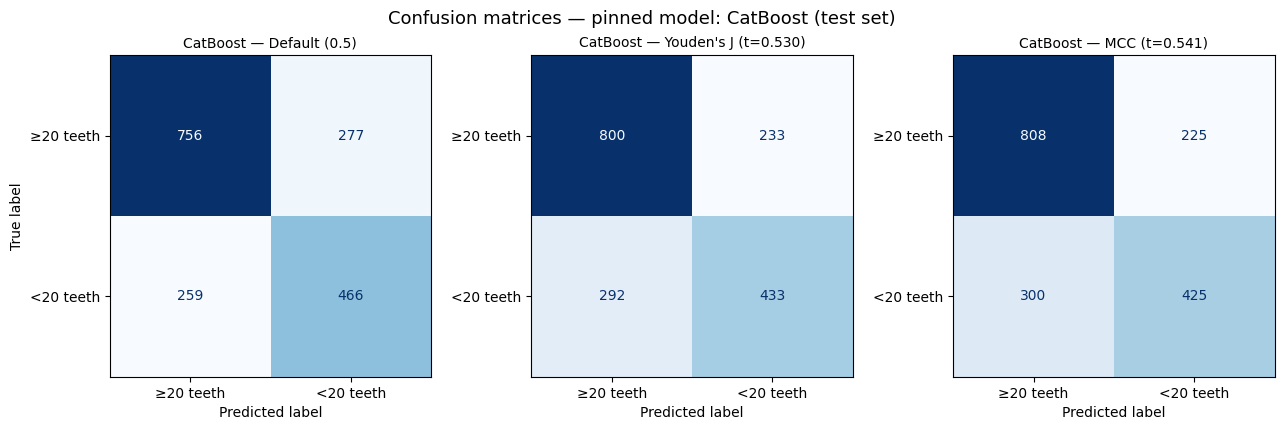

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, matthews_corrcoef
from sklearn.model_selection import cross_val_predict

def mcc_curve(y_true, proba, thresholds):
    """MCC at every threshold, vectorised.

    Exactly equivalent to [matthews_corrcoef(y_true, (proba >= t)) for t in thresholds],
    but O(n log n) instead of O(n * n_thresholds) -- the loop rebuilt an n-length prediction
    array for each of ~n distinct thresholds, which dominated the runtime of the per-model
    threshold search below.

    Sort the scores descending once; as the threshold sweeps down, rows flip 0 -> 1 in that
    order, so the confusion matrix at the k-th cut-point is a running total. This is the same
    trick sklearn's own roc_curve uses to build its TPS/FPS arrays.
    """
    y = np.asarray(y_true, dtype=np.int64)
    p = np.asarray(proba, dtype=float)
    order    = np.argsort(-p, kind='mergesort')
    y_sorted = y[order]
    p_sorted = p[order]
    P = int(y.sum())
    N = y.size - P
    # k = how many rows are predicted positive at each threshold, i.e. count of p >= t
    k      = np.searchsorted(-p_sorted, -np.asarray(thresholds, dtype=float), side='right')
    cum_tp = np.concatenate(([0], np.cumsum(y_sorted)))
    TP = cum_tp[k].astype(float)
    FP = k - TP
    FN = P - TP
    TN = N - FP
    denom = np.sqrt((TP + FP) * (TP + FN) * (TN + FP) * (TN + FN))
    with np.errstate(invalid='ignore', divide='ignore'):
        mcc = (TP * TN - FP * FN) / denom
    return np.where(denom == 0, 0.0, mcc)   # sklearn returns 0 for a degenerate split


# Pinned model only. pinned_model_name is pinned to CatBoost in §9.1 (cross-cohort SHAP
# comparability); this cell reports thresholds and confusion matrices for that model.
# The single-element list keeps the same list/loop machinery that previously drove the
# top-3 grid -- the grid is now 1x3 (pinned model x 3 thresholds).
target_models   = [pinned_model_name]
col_labels      = ["Default (0.5)", "Youden's J", 'MCC']

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))

for row, name in enumerate(target_models):
    model      = fitted_models[name]
    proba_test = model.predict_proba(X_test)[:, 1]

    # OOF probabilities on train — threshold must not touch test set. Reuse the §9.1
    # cache instead of recomputing via cross_val_predict(model, ...): for XGBoost, `model`
    # bakes in the frozen global SCALE_POS_WEIGHT, so a fresh cross_val_predict would use
    # that same frozen value on every fold instead of the fold-local ratio
    # _xgb_oof_proba() computed in §9.1 -- the exact inconsistency §8/§9.1 avoid elsewhere.
    oof_p = oof_proba_by_model[name]
    fpr_oof, tpr_oof, thresh_oof = roc_curve(y_train, oof_p)

    # Youden's J threshold
    j_scores      = tpr_oof + (1 - fpr_oof) - 1
    youden_thresh = float(thresh_oof[j_scores.argmax()])

    # MCC threshold -- vectorised via mcc_curve() defined above in this cell
    mcc_scores  = mcc_curve(y_train, oof_p, thresh_oof)
    mcc_thresh  = float(thresh_oof[int(np.argmax(mcc_scores))])

    for col, (thresh, label) in enumerate(zip([0.5, youden_thresh, mcc_thresh], col_labels)):
        preds = (proba_test >= thresh).astype(int)
        cm    = confusion_matrix(y_test, preds)
        ConfusionMatrixDisplay(cm, display_labels=['≥20 teeth', '<20 teeth']).plot(
            ax=axes[col], cmap='Blues', colorbar=False)
        t_str = '' if thresh == 0.5 else f' (t={thresh:.3f})'
        axes[col].set_title(f'{name} — {label}{t_str}', fontsize=10)
        if col != 0:
            axes[col].set_ylabel('')

plt.suptitle(f'Confusion matrices — pinned model: {", ".join(target_models)} '
             f'(test set)', fontsize=13)
plt.tight_layout()
plt.show()

<h3 style="color:yellow";> 12.1 ROC Curve Comparison </h3>

Overlay the ROC curves of all tuned models on the test set for side-by-side AUC comparison.

/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


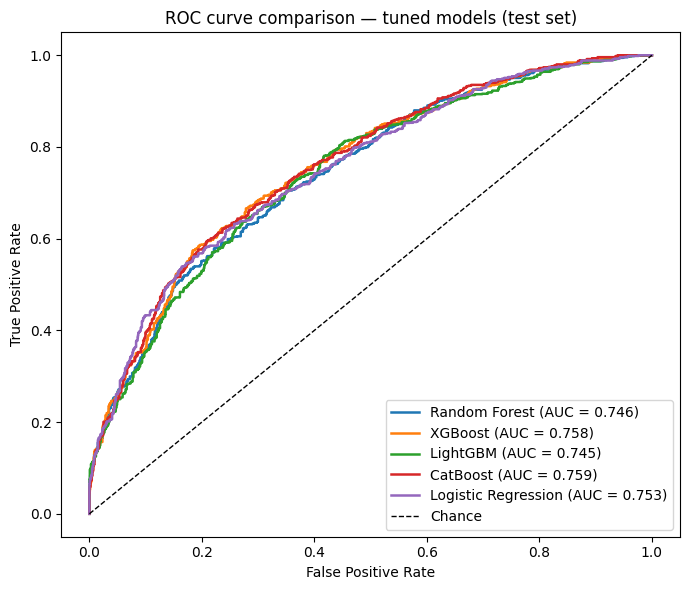

In [29]:
from sklearn.metrics import roc_curve, auc

# All tuned models on one ROC plot (test set) for comparison
fig, ax = plt.subplots(figsize=(7, 6))
for name, model in fitted_models.items():
    proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba, sample_weight=w_test_arr)
    ax.plot(fpr, tpr, linewidth=1.8, label=f'{name} (AUC = {auc(fpr, tpr):.3f})')

ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Chance')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC curve comparison — tuned models (test set)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()


<h3 style="color:yellow";> 12.2 AUPRC Curve  </h3>



/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


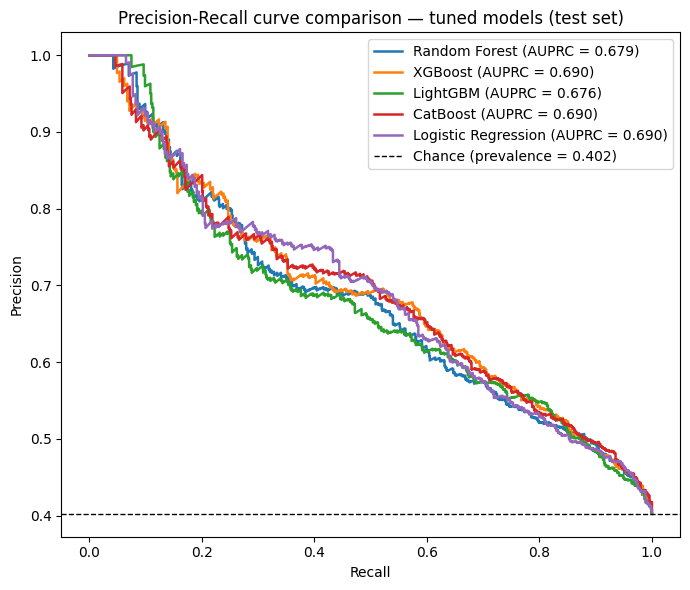

In [30]:
from sklearn.metrics import precision_recall_curve, average_precision_score

# Weighted prevalence: the chance line must sit at the POPULATION positive rate, matching
# the survey-weighted AUPRC values in the legend.
baseline = np.average(y_test.to_numpy(), weights=w_test_arr)

fig, ax = plt.subplots(figsize=(7, 6))
for name, model in fitted_models.items():
    proba = model.predict_proba(X_test)[:, 1]
    prec, rec, _ = precision_recall_curve(y_test, proba, sample_weight=w_test_arr)
    ap = average_precision_score(y_test, proba, sample_weight=w_test_arr)
    ax.plot(rec, prec, linewidth=1.8, label=f'{name} (AUPRC = {ap:.3f})')

ax.axhline(baseline, color='k', linestyle='--', linewidth=1,
           label=f'Chance (prevalence = {baseline:.3f})')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall curve comparison — tuned models (test set)')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()


<h3 style="color:yellow";> 12.3 Calibration Curve </h3>

Raw vs. Platt-recalibrated calibration curve for `pinned_model_name`. Recalibration is fitted from tuning-independent nested OOF development predictions for every model. The displayed **Platt mapping slope and intercept are transformation coefficients**, not 2024 calibration-slope or calibration-intercept diagnostics. The 2024 outcomes are used only for the weighted Brier score, ECE, and calibration curve.


/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/Users/yonghan/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters


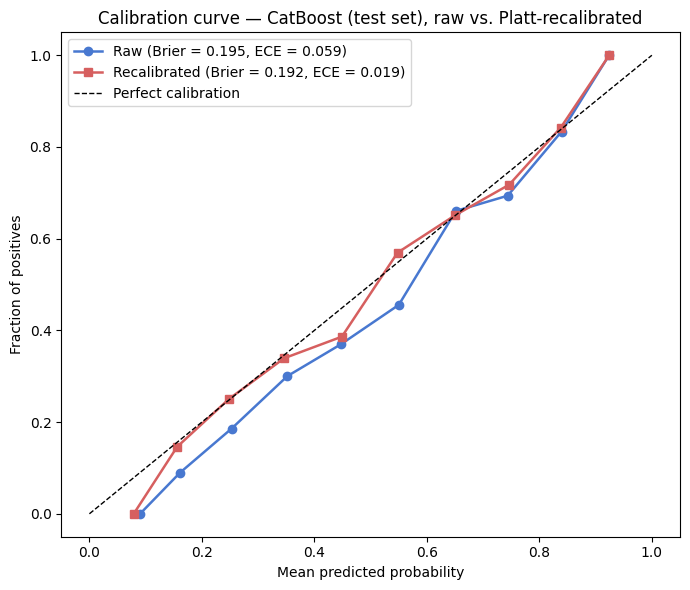


Development-fitted Platt mapping and 2024 weighted calibration performance (n_train=5946, n_test=1758):
                     Platt mapping slope (development OOF)  Platt mapping intercept (development OOF)  Brier (raw)  Brier (recalibrated)  ECE (raw)  ECE (recalibrated)
Model                                                                                                                                                                  
Random Forest                                       1.4235                                    -0.0660       0.2005                0.1965     0.0606              0.0353
XGBoost                                             1.0810                                    -0.2061       0.1957                0.1925     0.0597              0.0324
LightGBM                                            1.0316                                    -0.1958       0.1997                0.1973     0.0502              0.0283
CatBoost                                            1.0

In [31]:
# ── §12.3 Calibration curve — raw vs. Platt-recalibrated (pinned model, CatBoost) ──────────
# `class_weight="balanced"` / `scale_pos_weight` shift predicted probabilities away from
# true prevalence -- the same direction SMOTE would, which §11 explicitly avoided SMOTE
# for. Recalibration is fit on tuning-independent nested OOF TRAIN probabilities
# (oof_proba_by_model, §9.1) only; the test set is untouched until evaluation below.
# Its slope/intercept are Platt TRANSFORMATION coefficients, not 2024 calibration
# slope/intercept diagnostics.
from sklearn.metrics import brier_score_loss
from sklearn.linear_model import LogisticRegression

def _weighted_calibration_curve(y_true, y_prob, weight, n_bins=10):
    """Weighted-bin-proportion calibration curve. sklearn's calibration_curve accepts no
    sample_weight, so the plotted curve and the (already weighted) Brier/ECE score next to
    it described two different populations -- this puts both on the same weighted footing."""
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    bin_idx = np.clip(np.digitize(y_prob, edges[1:-1]), 0, n_bins - 1)
    prob_true, prob_pred = [], []
    for b in range(n_bins):
        m = bin_idx == b
        if not m.any():
            continue
        wb = weight[m]
        prob_true.append(np.average(y_true[m], weights=wb))
        prob_pred.append(np.average(y_prob[m], weights=wb))
    return np.array(prob_true), np.array(prob_pred)


def _logit(p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))

def _ece(y_true, y_prob, sample_weight=None, n_bins=10):
    # Expected Calibration Error -- uniform [0, 1] bins. Survey-weighted (sample_weight)
    # so it sits on the same footing as the Brier columns below; the plotted calibration
    # and the custom calibration curve use the same survey weights. Per-bin weight is the
    # share of the weighted test population landing in that bin.
    y_true = np.asarray(y_true, dtype=float)
    y_prob = np.asarray(y_prob, dtype=float)
    w = np.ones_like(y_prob) if sample_weight is None else np.asarray(sample_weight, dtype=float)
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    b_idx = np.clip(np.digitize(y_prob, edges[1:-1]), 0, n_bins - 1)
    total_w = w.sum()
    ece = 0.0
    for b in range(n_bins):
        m = b_idx == b
        w_b = w[m].sum()
        if w_b == 0:
            continue
        conf = np.average(y_prob[m], weights=w[m])
        acc = np.average(y_true[m], weights=w[m])
        ece += (w_b / total_w) * abs(acc - conf)
    return ece

recal_rows = []
recal_proba_by_model = {}
for name, model in fitted_models.items():
    proba_raw = model.predict_proba(X_test)[:, 1]

    # C=np.inf: Platt scaling must be UNPENALISED. LogisticRegression() defaults to
    # L2 with C=1, which shrinks the fitted mapping slope toward 0 and changes the
    # transformation applied to the 2024 probabilities.
    # C=np.inf replaces the deprecated penalty=None (removed in scikit-learn 1.10);
    # coefficients are bit-identical. sklearn 1.8 emits a cosmetic UserWarning here.
    recalibrator = LogisticRegression(C=np.inf).fit(
        _logit(oof_proba_by_model[name]).reshape(-1, 1), y_train)
    platt_slope, platt_intercept = recalibrator.coef_[0, 0], recalibrator.intercept_[0]
    proba_recal = recalibrator.predict_proba(_logit(proba_raw).reshape(-1, 1))[:, 1]
    recal_proba_by_model[name] = proba_recal

    recal_rows.append({
        "Model": name,
        "Platt mapping slope (development OOF)": platt_slope,
        "Platt mapping intercept (development OOF)": platt_intercept,
        # Test Brier scores are survey-weighted; the recalibrator itself is FITTED on
        # unweighted training OOF probabilities, since fitting stays unweighted throughout.
        "Brier (raw)": brier_score_loss(y_test, proba_raw, sample_weight=w_test_arr),
        "Brier (recalibrated)": brier_score_loss(y_test, proba_recal, sample_weight=w_test_arr),
        "ECE (raw)": _ece(y_test, proba_raw, sample_weight=w_test_arr),
        "ECE (recalibrated)": _ece(y_test, proba_recal, sample_weight=w_test_arr),
    })

recal_df = pd.DataFrame(recal_rows).set_index("Model")

# ── Plot: pinned model (CatBoost) only, raw vs. Platt-recalibrated ──────────────────────────────
# Curve and Brier/ECE score are now on the same weighted footing (see
# _weighted_calibration_curve above).
proba_pinned_raw = pinned_model.predict_proba(X_test)[:, 1]
proba_pinned_recal = recal_proba_by_model[pinned_model_name]
brier_raw = brier_score_loss(y_test, proba_pinned_raw, sample_weight=w_test_arr)
brier_recal = brier_score_loss(y_test, proba_pinned_recal, sample_weight=w_test_arr)
ece_raw = _ece(y_test, proba_pinned_raw, sample_weight=w_test_arr)
ece_recal = _ece(y_test, proba_pinned_recal, sample_weight=w_test_arr)

prob_true_raw, prob_pred_raw = _weighted_calibration_curve(y_test.to_numpy(), proba_pinned_raw, w_test_arr, n_bins=10)
prob_true_recal, prob_pred_recal = _weighted_calibration_curve(y_test.to_numpy(), proba_pinned_recal, w_test_arr, n_bins=10)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(prob_pred_raw, prob_true_raw, marker='o', linewidth=1.8, color='#4878d0',
        label=f'Raw (Brier = {brier_raw:.3f}, ECE = {ece_raw:.3f})')
ax.plot(prob_pred_recal, prob_true_recal, marker='s', linewidth=1.8, color='#d65f5f',
        label=f'Recalibrated (Brier = {brier_recal:.3f}, ECE = {ece_recal:.3f})')
ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Perfect calibration')
ax.set_xlabel('Mean predicted probability')
ax.set_ylabel('Fraction of positives')
ax.set_title(f'Calibration curve — {pinned_model_name} (test set), raw vs. Platt-recalibrated')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

print(f"\nDevelopment-fitted Platt mapping and 2024 weighted calibration performance "
      f"(n_train={len(y_train)}, n_test={len(y_test)}):")
print(recal_df.round(4).to_string())


<h3 style="color:#87CEEB";> 12.4 Sex-Stratified Calibration — Brier Score & Calibration Curve by Sex </h3>

Companion to §9.3: AUROC/AUPRC alone can't detect a sex-specific miscalibration (e.g. `class_weight="balanced"` shifting predicted probabilities differently for men vs. women), which would bias the §12 DCA net-benefit numbers for that subgroup. Restricted to `pinned_model_name` (the model carried through §11–§12) rather than all 5 tuned models, matching the summary-level ask.

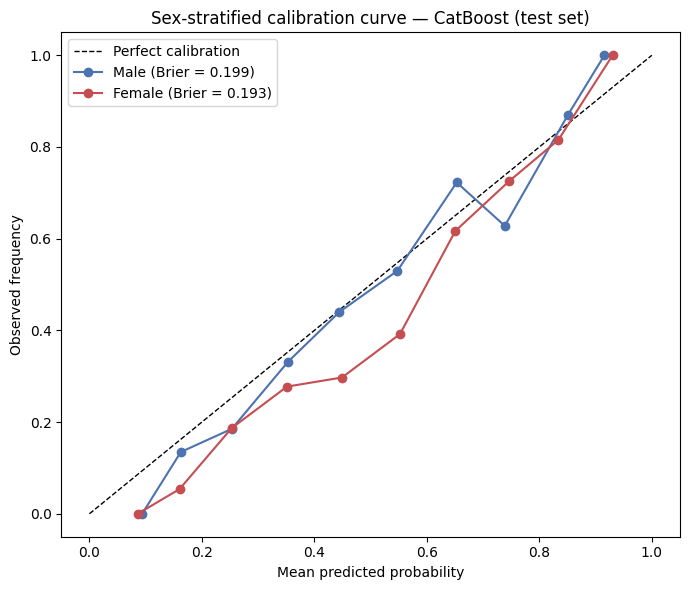

Sex-stratified calibration (CatBoost, age≥65 cohort, n_test=1758, 2000 PSU-within-stratum cluster resamples, seed=42)
           n  n_pos       Brier (95% CI)
Sex                                     
Male     733    323  0.199 (0.188–0.209)
Female  1025    402  0.193 (0.182–0.203)


In [32]:
# ── §12.4 Sex-stratified calibration — Brier score & calibration curve, pinned model (CatBoost) only ──
# Self-contained: re-derives the sex vector rather than relying on §9.3 execution order,
# mirroring §9.3's own "self-contained" comment. Same PSU-within-stratum cluster
# bootstrap as §9.2/§9.3 (2000 resamples, seed=42), within each sex subset.
from sklearn.metrics import brier_score_loss

def _weighted_calibration_curve(y_true, y_prob, weight, n_bins=10):
    """Weighted-bin-proportion calibration curve. sklearn's calibration_curve accepts no
    sample_weight, so the plotted curve and the (already weighted) Brier/ECE score next to
    it described two different populations -- this puts both on the same weighted footing."""
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    bin_idx = np.clip(np.digitize(y_prob, edges[1:-1]), 0, n_bins - 1)
    prob_true, prob_pred = [], []
    for b in range(n_bins):
        m = bin_idx == b
        if not m.any():
            continue
        wb = weight[m]
        prob_true.append(np.average(y_true[m], weights=wb))
        prob_pred.append(np.average(y_prob[m], weights=wb))
    return np.array(prob_true), np.array(prob_pred)


_yte_c = y_test.to_numpy()
_sex_c = df_subset.loc[test_mask, 'sex'].map({1: 'Male', 2: 'Female'})
assert _sex_c.index.equals(X_test.index), "sex vector misaligned with X_test rows"
_sex_c = _sex_c.to_numpy()
_proba_pinned = pinned_model.predict_proba(X_test)[:, 1]
_w_c = w_test.to_numpy()   # survey weights for both the Brier scores and the curve bins

N_BOOT_CAL = 2000
_rng_cal = np.random.default_rng(42)
_psu_cal = df_subset.loc[test_mask, 'psu'].to_numpy()
_strata_cal = df_subset.loc[test_mask, 'kstrata'].to_numpy()
assert len(_psu_cal) == len(_yte_c), "calibration-bootstrap design columns misaligned"

def _psu_boot_cal(rows, rng, n_boot):
    boots = []
    for _ in range(n_boot):
        drawn_rows = []
        for stratum in np.unique(_strata_cal[rows]):
            rows_h = rows[_strata_cal[rows] == stratum]
            psus_h = np.unique(_psu_cal[rows_h])
            drawn_psus = rng.choice(psus_h, size=len(psus_h), replace=True)
            drawn_rows.extend(rows_h[_psu_cal[rows_h] == psu] for psu in drawn_psus)
        boots.append(np.concatenate(drawn_rows))
    return boots

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Perfect calibration')

_cal_rows = []
for _s, _color in zip(('Male', 'Female'), ('#4C72B0', '#C44E52')):
    _rows_s = np.where(_sex_c == _s)[0]
    _y_s, _p_s, _w_s = _yte_c[_rows_s], _proba_pinned[_rows_s], _w_c[_rows_s]
    _brier = brier_score_loss(_y_s, _p_s, sample_weight=_w_s)

    _boot_idx_s = _psu_boot_cal(_rows_s, _rng_cal, N_BOOT_CAL)
    _boots = np.fromiter(
        (brier_score_loss(_yte_c[bi], _proba_pinned[bi], sample_weight=_w_c[bi])
         for bi in _boot_idx_s), dtype=float, count=N_BOOT_CAL)
    _lo, _hi = np.percentile(_boots, [2.5, 97.5])
    _brier_str = f"{_brier:.3f} ({_lo:.3f}–{_hi:.3f})"

    prob_true, prob_pred = _weighted_calibration_curve(_y_s, _p_s, _w_s, n_bins=10)
    ax.plot(prob_pred, prob_true, 'o-', color=_color, label=f'{_s} (Brier = {_brier:.3f})')

    _cal_rows.append({"Sex": _s, "n": int(_rows_s.size), "n_pos": int(_y_s.sum()),
                       "Brier (95% CI)": _brier_str})

ax.set_xlabel('Mean predicted probability')
ax.set_ylabel('Observed frequency')
ax.set_title(f'Sex-stratified calibration curve — {pinned_model_name} (test set)')
ax.legend()
plt.tight_layout()
plt.show()

sex_calibration_df = pd.DataFrame(_cal_rows).set_index("Sex")
print(f"Sex-stratified calibration ({pinned_model_name}, age≥{age_threshold} cohort, "
      f"n_test={len(_yte_c)}, {N_BOOT_CAL} PSU-within-stratum cluster resamples, seed=42)")
print(sex_calibration_df.to_string())

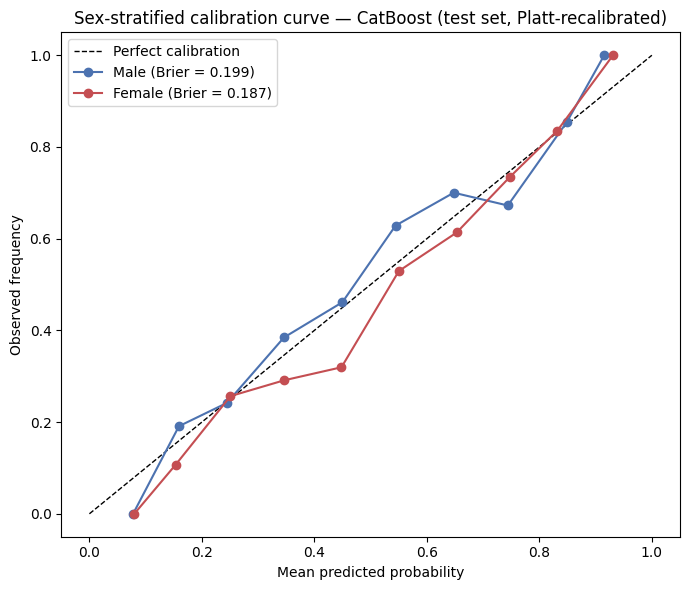

Sex-stratified calibration — Platt-recalibrated (CatBoost, age≥65 cohort, n_test=1758, 2000 PSU-within-stratum cluster resamples, seed=42)
           n  n_pos       Brier (95% CI)
Sex                                     
Male     733    323  0.199 (0.188–0.211)
Female  1025    402  0.187 (0.175–0.198)


In [33]:
# ── §12.4 (cont.) Sex-stratified calibration — Brier score, PLATT-RECALIBRATED probabilities, pinned model (CatBoost) only ──
# Companion to the RAW sex-stratified Brier reported above. Identical recipe -- self-contained
# sex vector, same PSU-within-stratum cluster bootstrap (2000 resamples, seed=42, within each sex subset,
# survey-weighted Brier and weighted-bin curve) -- but scored on recal_proba_by_model[pinned_model_name] (Platt-
# scaled on out-of-fold TRAIN probabilities in §12.3) instead of the model's raw output.
from sklearn.metrics import brier_score_loss

def _weighted_calibration_curve(y_true, y_prob, weight, n_bins=10):
    """Weighted-bin-proportion calibration curve. sklearn's calibration_curve accepts no
    sample_weight, so the plotted curve and the (already weighted) Brier/ECE score next to
    it described two different populations -- this puts both on the same weighted footing."""
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    bin_idx = np.clip(np.digitize(y_prob, edges[1:-1]), 0, n_bins - 1)
    prob_true, prob_pred = [], []
    for b in range(n_bins):
        m = bin_idx == b
        if not m.any():
            continue
        wb = weight[m]
        prob_true.append(np.average(y_true[m], weights=wb))
        prob_pred.append(np.average(y_prob[m], weights=wb))
    return np.array(prob_true), np.array(prob_pred)


_yte_r = y_test.to_numpy()
_sex_r = df_subset.loc[test_mask, 'sex'].map({1: 'Male', 2: 'Female'})
assert _sex_r.index.equals(X_test.index), "sex vector misaligned with X_test rows"
_sex_r = _sex_r.to_numpy()
_proba_recal = recal_proba_by_model[pinned_model_name]
_w_r = w_test.to_numpy()   # survey weights for both the Brier scores and the curve bins

N_BOOT_CAL = 2000
_rng_cal_r = np.random.default_rng(42)
_psu_cal_r = df_subset.loc[test_mask, 'psu'].to_numpy()
_strata_cal_r = df_subset.loc[test_mask, 'kstrata'].to_numpy()
assert len(_psu_cal_r) == len(_yte_r), "recalibration-bootstrap design columns misaligned"

def _psu_boot_cal_r(rows, rng, n_boot):
    boots = []
    for _ in range(n_boot):
        drawn_rows = []
        for stratum in np.unique(_strata_cal_r[rows]):
            rows_h = rows[_strata_cal_r[rows] == stratum]
            psus_h = np.unique(_psu_cal_r[rows_h])
            drawn_psus = rng.choice(psus_h, size=len(psus_h), replace=True)
            drawn_rows.extend(rows_h[_psu_cal_r[rows_h] == psu] for psu in drawn_psus)
        boots.append(np.concatenate(drawn_rows))
    return boots

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Perfect calibration')

_cal_rows_r = []
for _s, _color in zip(('Male', 'Female'), ('#4C72B0', '#C44E52')):
    _rows_s = np.where(_sex_r == _s)[0]
    _y_s, _p_s, _w_s = _yte_r[_rows_s], _proba_recal[_rows_s], _w_r[_rows_s]
    _brier = brier_score_loss(_y_s, _p_s, sample_weight=_w_s)

    _boot_idx_s = _psu_boot_cal_r(_rows_s, _rng_cal_r, N_BOOT_CAL)
    _boots = np.fromiter(
        (brier_score_loss(_yte_r[bi], _proba_recal[bi], sample_weight=_w_r[bi])
         for bi in _boot_idx_s), dtype=float, count=N_BOOT_CAL)
    _lo, _hi = np.percentile(_boots, [2.5, 97.5])
    _brier_str = f"{_brier:.3f} ({_lo:.3f}–{_hi:.3f})"

    prob_true, prob_pred = _weighted_calibration_curve(_y_s, _p_s, _w_s, n_bins=10)
    ax.plot(prob_pred, prob_true, 'o-', color=_color, label=f'{_s} (Brier = {_brier:.3f})')

    _cal_rows_r.append({"Sex": _s, "n": int(_rows_s.size), "n_pos": int(_y_s.sum()),
                        "Brier (95% CI)": _brier_str})

ax.set_xlabel('Mean predicted probability')
ax.set_ylabel('Observed frequency')
ax.set_title(f'Sex-stratified calibration curve — {pinned_model_name} (test set, Platt-recalibrated)')
ax.legend()
plt.tight_layout()
plt.show()

sex_calibration_recal_df = pd.DataFrame(_cal_rows_r).set_index("Sex")
print(f"Sex-stratified calibration — Platt-recalibrated ({pinned_model_name}, age≥{age_threshold} cohort, "
      f"n_test={len(_yte_r)}, {N_BOOT_CAL} PSU-within-stratum cluster resamples, seed=42)")
print(sex_calibration_recal_df.to_string())


<h3 style="color:yellow";> 12.5 Decision Curve Analysis — Clinical Utility (Recalibrated Probabilities) </h3>

AUC and AUPRC measure how well a model *ranks* respondents; neither says whether acting on a predicted risk is worth doing. Decision curve analysis (Vickers & Elkin, 2006) reports **net benefit** across a range of referral thresholds, against the two trivial defaults — refer everyone, refer no one.

**This section deliberately sits after §12.3.** Net benefit is evaluated *at* a probability threshold, so it is only meaningful if a predicted risk of 0.20 really corresponds to a 20% chance. Every tuned model here is fitted with `class_weight="balanced"` / `scale_pos_weight`, which §12.3 shows pushes predicted probabilities away from true prevalence — the same distortion that ruled out SMOTE. DCA is therefore computed on `recal_proba_by_model` (Platt-scaled on out-of-fold **training** probabilities, computed for every model in §12.3), not on raw model output. Running it on the raw probabilities, as an earlier version did, gave net-benefit values that were not interpretable at any threshold.

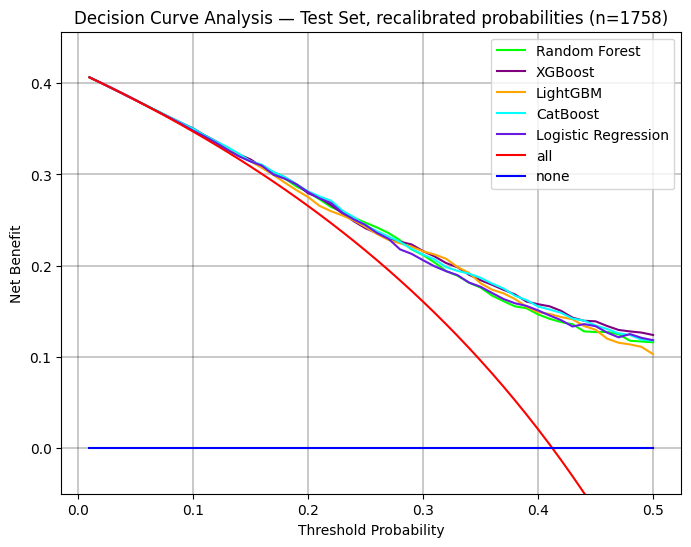

In [34]:
# ── Decision Curve Analysis — clinical utility of using each model to guide referral decisions ──
# AUC/AUPRC measure ranking quality; DCA measures whether acting on a model's predicted risk at a
# given threshold does more good than the "refer everyone" / "refer no one" defaults (Vickers &
# Elkin, 2006).
#
# USES THE RECALIBRATED PROBABILITIES from §12.3, not the raw ones. Net benefit is evaluated
# AT a probability threshold, so it is only interpretable if the predicted probability means
# what it says. Every model here is fitted with class_weight="balanced" / scale_pos_weight,
# which §12.3 shows deliberately shifts predicted probabilities away from true prevalence --
# exactly the distortion that made SMOTE unacceptable. Running DCA on those raw probabilities
# produced net-benefit numbers that were not interpretable at any threshold. This cell now
# sits AFTER §12.3 so recal_proba_by_model is available.
from dcurves import dca, plot_graphs

# NOTE: dcurves accepts no survey weights, so net benefit here is a SAMPLE-level quantity,
# unlike the survey-weighted metrics in §9. Report it as such.
dca_thresholds = np.arange(0.01, 0.51, 0.01)

dca_data = pd.DataFrame({"O_TC_": y_test_arr})
for name in model_names:
    dca_data[name] = recal_proba_by_model[name]

dca_result = dca(
    data=dca_data,
    outcome="O_TC_",
    modelnames=model_names,
    thresholds=dca_thresholds,
)

y_max = dca_result["net_benefit"].max() + 0.05
plt.figure(figsize=(8, 6))
plt.title(f"Decision Curve Analysis — Test Set, recalibrated probabilities (n={len(y_test_arr)})")
plot_graphs(
    plot_df=dca_result,
    graph_type="net_benefit",
    y_limits=(-0.05, y_max),
)


In [35]:
# ── DCA results as text (net benefit by threshold; recalibrated probabilities) ──
dca_table = (
    dca_result
    .pivot(index="threshold", columns="model", values="net_benefit")
    .round(4)
)
dca_table = dca_table[model_names + ["all", "none"]]
pd.set_option("display.max_rows", None)
print(dca_table.to_string())


model      Random Forest  XGBoost  LightGBM  CatBoost  Logistic Regression     all  none
threshold                                                                               
0.01              0.4065   0.4065    0.4065    0.4065               0.4065  0.4065   0.0
0.02              0.4004   0.4004    0.4004    0.4004               0.4004  0.4004   0.0
0.03              0.3942   0.3942    0.3942    0.3942               0.3942  0.3942   0.0
0.04              0.3880   0.3879    0.3879    0.3879               0.3879  0.3879   0.0
0.05              0.3817   0.3815    0.3816    0.3815               0.3815  0.3815   0.0
0.06              0.3753   0.3750    0.3753    0.3751               0.3750  0.3749   0.0
0.07              0.3689   0.3688    0.3685    0.3688               0.3685  0.3682   0.0
0.08              0.3619   0.3625    0.3626    0.3625               0.3620  0.3613   0.0
0.09              0.3552   0.3565    0.3560    0.3565               0.3554  0.3543   0.0
0.10              0.3